# Marriott International — Audit Analytics with Python

## Project objective
Analyse Marriott International's financial data to identify potential audit-risk indicators relating to revenue, receivables, operating cash flow, debt and liquidity.

## Data and methodology
The analysis uses financial information retrieved from SEC EDGAR XBRL company facts and filings. Python, pandas, NumPy and Matplotlib are used to extract, prepare, analyse and visualise the data.

## Scope
The main financial analysis covers 2015–2025, with a more detailed assessment of debt and liquidity indicators for 2021–2025.

## Audit perspective
The results are intended to support preliminary audit-risk assessment and the design of further audit procedures. They are analytical indicators, not proof of material misstatement or a substitute for a statutory audit.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [2]:
import requests

url = "https://data.sec.gov/api/xbrl/companyfacts/CIK0001048286.json"

headers = {
    "User-Agent": "Hotel Audit Project your-email@example.com"
}

response = requests.get(url, headers=headers)

data = response.json()

In [3]:
us_gaap = data["facts"]["us-gaap"]

In [4]:
from datetime import date

def get_annual_facts(us_gaap, concept_name, start_year, end_year):
    """
    Extract one annual observation per fiscal year from SEC Company Facts.

    Handles:
    - instant facts: balance-sheet items
    - duration facts: income-statement items
    """

    facts = us_gaap[concept_name]["units"]["USD"]

    candidates = [
        item
        for item in facts
        if (
            item.get("fy") is not None
            and start_year <= item["fy"] <= end_year
            and item.get("form") == "10-K"
        )
    ]

    annual_facts = []

    for fy in range(start_year, end_year + 1):

        year_facts = [
            item
            for item in candidates
            if item["fy"] == fy
        ]

        if not year_facts:
            continue

        duration_facts = [
            item for item in year_facts
            if "start" in item
        ]

        instant_facts = [
            item for item in year_facts
            if "start" not in item
        ]

        if duration_facts:

            annual_candidates = []

            for item in duration_facts:
                start = date.fromisoformat(item["start"])
                end = date.fromisoformat(item["end"])

                duration_days = (end - start).days

                if 300 <= duration_days <= 400:
                    annual_candidates.append(item)

            if not annual_candidates:
                continue

            annual = max(
                annual_candidates,
                key=lambda item: item["end"]
            )

        else:
            instant_candidates = [
                item for item in year_facts
                if "start" not in item
            ]

            if not instant_candidates:
                continue

            annual = max(
                instant_candidates,
                key=lambda item: item["end"]
            )

        annual_facts.append(annual)

    return annual_facts

In [5]:
revenue = get_annual_facts(
    us_gaap,
    "Revenues",
    2015,
    2025
)

receivables = get_annual_facts(
    us_gaap,
    "AccountsNotesAndLoansReceivableNetCurrent",
    2015,
    2025
)

In [6]:
df = pd.DataFrame({
    "year": [item["fy"] for item in revenue],
    "revenue": [item["val"] for item in revenue],
    "receivables": [item["val"] for item in receivables],
})

In [7]:
df["revenue_growth"] = df["revenue"].pct_change()
df["receivables_growth"] = df["receivables"].pct_change()

In [8]:
df["divergence"] = (
    df["revenue_growth"] -
    df["receivables_growth"]
)
df["abs_divergence"] = df["divergence"].abs()

In [9]:
df["divergence"].describe()

count    10.000000
mean     -0.019431
std       0.192038
min      -0.358201
25%      -0.151596
50%       0.015183
75%       0.146468
max       0.201923
Name: divergence, dtype: float64

In [10]:
df["period"] = pd.cut(
    df["year"],
    bins=[2015, 2019, 2020, 2025],
    labels=["Pre-2020", "2020", "Post-2020"]
)
df.groupby("period", observed=True)["abs_divergence"].agg(
    ["mean", "std", "count"]
)

,mean,std,count
period,,,
Pre-2020,0.200435,0.108105,4
2020,0.234152,NaN,1
Post-2020,0.101757,0.091278,5


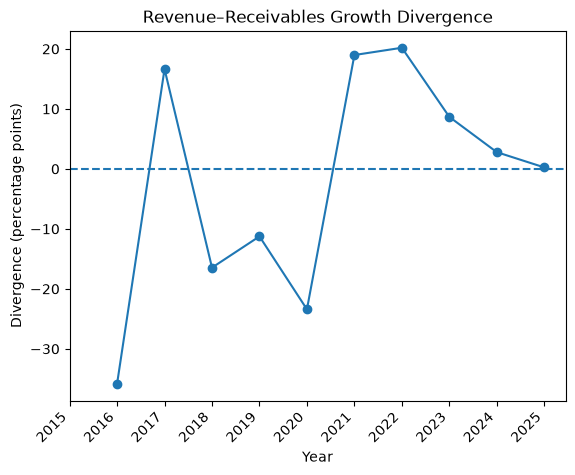

In [11]:
plt.plot(
    df["year"],
    df["divergence"] * 100,
    marker="o"
)

plt.axhline(0, linestyle="--")

plt.title("Revenue–Receivables Growth Divergence")
plt.xlabel("Year")
plt.ylabel("Divergence (percentage points)")

plt.xticks(
    df["year"],
    rotation=45,
    ha="right"
)

plt.show()

In [12]:
[c for c in us_gaap if "OperatingActivities" in c and "Cash" in c]

['NetCashProvidedByUsedInOperatingActivities',
 'OtherOperatingActivitiesCashFlowStatement']

In [13]:
[c for c in us_gaap if "OperatingActivities" in c and "Cash" in c]

['NetCashProvidedByUsedInOperatingActivities',
 'OtherOperatingActivitiesCashFlowStatement']

In [14]:
for concept in [
    "NetCashProvidedByUsedInOperatingActivities",
    "OtherOperatingActivitiesCashFlowStatement"
]:
    print("CONCEPT:", concept)
    print("LABEL:", us_gaap[concept]["label"])
    print("DESCRIPTION:", us_gaap[concept].get("description"))
    print("UNITS:", us_gaap[concept]["units"].keys())
    print("-" * 80)

CONCEPT: NetCashProvidedByUsedInOperatingActivities
LABEL: Net Cash Provided by (Used in) Operating Activities
DESCRIPTION: Amount of cash inflow (outflow) from operating activities, including discontinued operations. Operating activity cash flows include transactions, adjustments, and changes in value not defined as investing or financing activities.
UNITS: dict_keys(['USD'])
--------------------------------------------------------------------------------
CONCEPT: OtherOperatingActivitiesCashFlowStatement
LABEL: Other Operating Activities, Cash Flow Statement
DESCRIPTION: Other cash or noncash adjustments to reconcile net income to cash provided by (used in) operating activities that are not separately disclosed in the statement of cash flows (for example, cash received or cash paid during the current period for miscellaneous operating activities, net change during the reporting period in other assets or other liabilities).
UNITS: dict_keys(['USD'])
-----------------------------------

In [15]:
concept = "NetCashProvidedByUsedInOperatingActivities"

print(us_gaap[concept]["label"])
print(us_gaap[concept]["description"])
print(us_gaap[concept]["units"].keys())

Net Cash Provided by (Used in) Operating Activities
Amount of cash inflow (outflow) from operating activities, including discontinued operations. Operating activity cash flows include transactions, adjustments, and changes in value not defined as investing or financing activities.
dict_keys(['USD'])


In [16]:
concept = "NetCashProvidedByUsedInOperatingActivities"

print("LABEL:")
print(us_gaap[concept]["label"])

print("\nDESCRIPTION:")
print(us_gaap[concept]["description"])

print("\nUNITS:")
print(us_gaap[concept]["units"].keys())

LABEL:
Net Cash Provided by (Used in) Operating Activities

DESCRIPTION:
Amount of cash inflow (outflow) from operating activities, including discontinued operations. Operating activity cash flows include transactions, adjustments, and changes in value not defined as investing or financing activities.

UNITS:
dict_keys(['USD'])


In [17]:
facts = us_gaap[concept]["units"]["USD"]

for item in facts[:5]:
    print(item)
    print("-" * 80)

{'start': '2006-12-30', 'end': '2007-12-28', 'val': 778000000, 'accn': '0001193125-10-030603', 'fy': 2009, 'fp': 'FY', 'form': '10-K', 'filed': '2010-02-12', 'frame': 'CY2007'}
--------------------------------------------------------------------------------
{'start': '2007-12-29', 'end': '2008-06-13', 'val': 357000000, 'accn': '0001193125-09-150935', 'fy': 2009, 'fp': 'Q2', 'form': '10-Q', 'filed': '2009-07-17'}
--------------------------------------------------------------------------------
{'start': '2007-12-29', 'end': '2008-09-05', 'val': 555000000, 'accn': '0001193125-09-206036', 'fy': 2009, 'fp': 'Q3', 'form': '10-Q', 'filed': '2009-10-09'}
--------------------------------------------------------------------------------
{'start': '2007-12-29', 'end': '2009-01-02', 'val': 641000000, 'accn': '0001193125-10-030603', 'fy': 2009, 'fp': 'FY', 'form': '10-K', 'filed': '2010-02-12'}
--------------------------------------------------------------------------------
{'start': '2007-12-29', '

In [18]:
cash_flow_operations = get_annual_facts(
    us_gaap,
    "NetCashProvidedByUsedInOperatingActivities",
    2015,
    2025
)
len(cash_flow_operations)

11

In [19]:
for item in cash_flow_operations:
    print(
        item["fy"],
        item["val"],
        item["start"],
        item["end"]
    )

2015 1430000000 2015-01-01 2015-12-31
2016 1582000000 2016-01-01 2016-12-31
2017 2436000000 2017-01-01 2017-12-31
2018 2357000000 2018-01-01 2018-12-31
2019 1685000000 2019-01-01 2019-12-31
2020 1639000000 2020-01-01 2020-12-31
2021 1177000000 2021-01-01 2021-12-31
2022 2363000000 2022-01-01 2022-12-31
2023 3170000000 2023-01-01 2023-12-31
2024 2749000000 2024-01-01 2024-12-31
2025 3212000000 2025-01-01 2025-12-31


In [20]:
df["operating_cash_flow"] = [
    item["val"] for item in cash_flow_operations
]

In [21]:
df

,year,revenue,receivables,revenue_growth,receivables_growth,divergence,abs_divergence,period,operating_cash_flow
0,2015,14486000000,1103000000,NaN,NaN,NaN,NaN,NaN,1430000000
1,2016,17072000000,1695000000,0.178517,0.536718,-0.358201,0.358201,Pre-2020,1582000000
2,2017,22894000000,1991000000,0.341026,0.174631,0.166395,0.166395,Pre-2020,2436000000
3,2018,20758000000,2133000000,-0.093300,0.071321,-0.164620,0.164620,Pre-2020,2357000000
4,2019,20972000000,2395000000,0.010309,0.122832,-0.112522,0.112522,Pre-2020,1685000000
5,2020,10571000000,1768000000,-0.495947,-0.261795,-0.234152,0.234152,2020,1639000000
6,2021,13857000000,1982000000,0.310850,0.121041,0.189810,0.189810,Post-2020,1177000000
7,2022,20773000000,2571000000,0.499098,0.297175,0.201923,0.201923,Post-2020,2363000000
8,2023,23713000000,2712000000,0.141530,0.054842,0.086687,0.086687,Post-2020,3170000000
9,2024,25100000000,2795000000,0.058491,0.030605,0.027886,0.027886,Post-2020,2749000000


In [22]:
df_check = df[
    ["year", "revenue", "receivables", "operating_cash_flow"]
].copy()

print(
    df_check.to_string(
        formatters={
            "revenue": "{:,.0f}".format,
            "receivables": "{:,.0f}".format,
            "operating_cash_flow": "{:,.0f}".format,
        },
        index=False
    )
)

 year        revenue   receivables operating_cash_flow
 2015 14,486,000,000 1,103,000,000       1,430,000,000
 2016 17,072,000,000 1,695,000,000       1,582,000,000
 2017 22,894,000,000 1,991,000,000       2,436,000,000
 2018 20,758,000,000 2,133,000,000       2,357,000,000
 2019 20,972,000,000 2,395,000,000       1,685,000,000
 2020 10,571,000,000 1,768,000,000       1,639,000,000
 2021 13,857,000,000 1,982,000,000       1,177,000,000
 2022 20,773,000,000 2,571,000,000       2,363,000,000
 2023 23,713,000,000 2,712,000,000       3,170,000,000
 2024 25,100,000,000 2,795,000,000       2,749,000,000
 2025 26,186,000,000 2,909,000,000       3,212,000,000


In [23]:
df["operating_cash_flow_growth"] = (
    df["operating_cash_flow"].pct_change()
)



In [24]:
pd.reset_option("display.float_format")

In [25]:
df[["year", "operating_cash_flow_growth"]]

,year,operating_cash_flow_growth
0,2015,NaN
1,2016,0.106294
2,2017,0.539823
3,2018,-0.032430
4,2019,-0.285108
5,2020,-0.027300
6,2021,-0.281879
7,2022,1.007647
8,2023,0.341515
9,2024,-0.132808


In [26]:
df["cfo_divergence"] = (
    df["revenue_growth"] -
    df["operating_cash_flow_growth"]
)
df["abs_cfo_divergence"] = df["cfo_divergence"].abs()
df[
    ["year",
     "revenue_growth",
     "operating_cash_flow_growth",
     "cfo_divergence"]
]

,year,revenue_growth,operating_cash_flow_growth,cfo_divergence
0,2015,NaN,NaN,NaN
1,2016,0.178517,0.106294,0.072223
2,2017,0.341026,0.539823,-0.198797
3,2018,-0.093300,-0.032430,-0.060869
4,2019,0.010309,-0.285108,0.295417
5,2020,-0.495947,-0.027300,-0.468647
6,2021,0.310850,-0.281879,0.592730
7,2022,0.499098,1.007647,-0.508549
8,2023,0.141530,0.341515,-0.199985
9,2024,0.058491,-0.132808,0.191299


In [27]:
df["cfo_divergence"].describe()


count    10.000000
mean     -0.041034
std       0.340051
min      -0.508549
25%      -0.199688
50%      -0.093014
75%       0.161530
max       0.592730
Name: cfo_divergence, dtype: float64

In [28]:
df["abs_cfo_divergence"].describe()

count    10.000000
mean      0.271367
std       0.188899
min       0.060869
25%       0.141693
50%       0.199391
75%       0.425340
max       0.592730
Name: abs_cfo_divergence, dtype: float64

In [29]:
q1 = df["cfo_divergence"].quantile(0.25)
q3 = df["cfo_divergence"].quantile(0.75)

iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

q1, q3, iqr, lower_bound, upper_bound

(np.float64(-0.1996880563404162),
 np.float64(0.16152989117205163),
 np.float64(0.36121794751246783),
 np.float64(-0.7415149776091179),
 np.float64(0.7033568124407533))

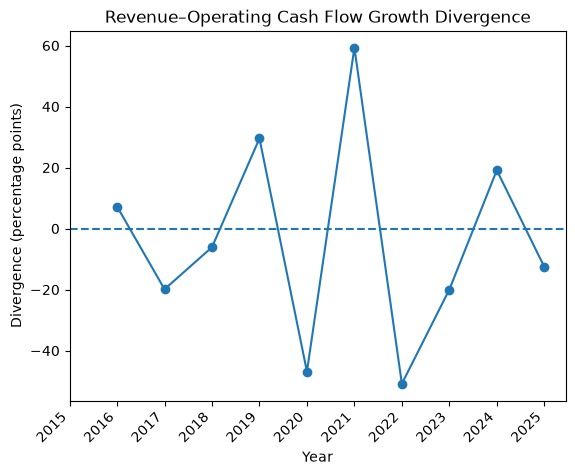

In [30]:
plt.plot(
    df["year"],
    df["cfo_divergence"] * 100,
    marker="o"
)

plt.axhline(0, linestyle="--")

plt.title("Revenue–Operating Cash Flow Growth Divergence")
plt.xlabel("Year")
plt.ylabel("Divergence (percentage points)")

plt.xticks(
    df["year"],
    rotation=45,
    ha="right"
)

plt.show()

In [31]:
[c for c in us_gaap if "OperatingActivities" in c]

['NetCashProvidedByUsedInOperatingActivities',
 'OtherOperatingActivitiesCashFlowStatement']

In [32]:
[c for c in us_gaap if "Receivable" in c]

['AccountsAndFinancingReceivableAllowanceForCreditLoss',
 'AccountsNotesAndLoansReceivableNetCurrent',
 'AllowanceForDoubtfulAccountsReceivableCurrent',
 'AllowanceForNotesReceivable',
 'FinancingReceivableAllowanceForCreditLosses',
 'FinancingReceivableAllowanceForCreditLossesPeriodIncreaseDecrease',
 'FinancingReceivableAllowanceForCreditLossesProvisions',
 'FinancingReceivableAllowanceForCreditLossesWriteOffs',
 'FinancingReceivableRecordedInvestmentPastDue',
 'ImpairedFinancingReceivableAverageRecordedInvestment',
 'ImpairedFinancingReceivableRecordedInvestment',
 'ImpairedFinancingReceivableWithNoRelatedAllowanceRecordedInvestment',
 'NotesAndLoansReceivableNetCurrent',
 'NotesAndLoansReceivableNetNoncurrent',
 'NotesReceivableNet',
 'OtherReceivables',
 'ProceedsFromSaleAndCollectionOfLoansReceivable',
 'ProceedsFromSaleAndCollectionOfNotesReceivable',
 'ReceivableWithImputedInterestDiscount',
 'AllowanceForDoubtfulAccountsReceivable']

In [33]:
[c for c in us_gaap if "IncreaseDecrease" in c]

['CashAndCashEquivalentsPeriodIncreaseDecrease',
 'CashCashEquivalentsRestrictedCashAndRestrictedCashEquivalentsPeriodIncreaseDecreaseIncludingExchangeRateEffect',
 'FinancingReceivableAllowanceForCreditLossesPeriodIncreaseDecrease',
 'IncreaseDecreaseInContractWithCustomerLiability',
 'IncreaseDecreaseInCustomerLoyaltyProgramLiability',
 'IncreaseDecreaseInOtherOperatingCapitalNet',
 'OtherComprehensiveIncomeDerivativesQualifyingAsHedgesNetOfTaxPeriodIncreaseDecrease',
 'OtherComprehensiveIncomeForeignCurrencyTransactionAndTranslationAdjustmentBeforeTaxPeriodIncreaseDecrease',
 'OtherComprehensiveIncomeForeignCurrencyTransactionAndTranslationAdjustmentNetOfTaxPeriodIncreaseDecrease',
 'OtherComprehensiveIncomeLossNetOfTaxPeriodIncreaseDecrease',
 'UnrecognizedTaxBenefitsPeriodIncreaseDecrease']

In [34]:
concept = "IncreaseDecreaseInOtherOperatingCapitalNet"

print("LABEL:")
print(us_gaap[concept]["label"])

print("\nDESCRIPTION:")
print(us_gaap[concept]["description"])

print("\nUNITS:")
print(us_gaap[concept]["units"].keys())

LABEL:
Increase (Decrease) in Other Operating Assets and Liabilities, Net

DESCRIPTION:
Amount of increase (decrease) in operating assets after deduction of operating liabilities classified as other.

UNITS:
dict_keys(['USD'])


In [35]:
facts = us_gaap[concept]["units"]["USD"]

for item in facts[:10]:
    print(item)
    print("-" * 80)

{'start': '2009-01-03', 'end': '2010-01-01', 'val': -106000000, 'accn': '0001445305-12-000342', 'fy': 2011, 'fp': 'FY', 'form': '10-K', 'filed': '2012-02-16', 'frame': 'CY2009'}
--------------------------------------------------------------------------------
{'start': '2010-01-02', 'end': '2010-09-10', 'val': -177000000, 'accn': '0001445305-11-002911', 'fy': 2011, 'fp': 'Q3', 'form': '10-Q', 'filed': '2011-10-07'}
--------------------------------------------------------------------------------
{'start': '2010-01-02', 'end': '2010-12-31', 'val': -120000000, 'accn': '0001445305-12-000342', 'fy': 2011, 'fp': 'FY', 'form': '10-K', 'filed': '2012-02-16'}
--------------------------------------------------------------------------------
{'start': '2010-01-02', 'end': '2010-12-31', 'val': -120000000, 'accn': '0001445305-13-000255', 'fy': 2012, 'fp': 'FY', 'form': '10-K', 'filed': '2013-02-20', 'frame': 'CY2010'}
--------------------------------------------------------------------------------
{'

In [36]:
[c for c in us_gaap if "Payable" in c]

['AccountsPayable',
 'AccountsPayableCurrent',
 'AccountsPayableTradeCurrent',
 'OtherAccountsPayableAndAccruedLiabilities']

In [37]:
[c for c in us_gaap if "Inventory" in c]

['InventoryNet', 'OtherInventory']

In [38]:
[c for c in us_gaap if "Payable" in c and "IncreaseDecrease" in c]

[]

In [39]:
[c for c in us_gaap if "Inventory" in c and "IncreaseDecrease" in c]

[]

In [40]:
[
    c for c in us_gaap
    if "Operating" in c
    and (
        "Asset" in c
        or "Liabil" in c
        or "Capital" in c
    )
]

['DeferredTaxAssetsOperatingLossCarryforwards',
 'DeferredTaxAssetsOperatingLossCarryforwardsSubjectToExpiration',
 'IncreaseDecreaseInOtherOperatingCapitalNet',
 'LesseeOperatingLeaseLiabilityPaymentsDue',
 'LesseeOperatingLeaseLiabilityPaymentsDueAfterYearFive',
 'LesseeOperatingLeaseLiabilityPaymentsDueNextTwelveMonths',
 'LesseeOperatingLeaseLiabilityPaymentsDueYearFive',
 'LesseeOperatingLeaseLiabilityPaymentsDueYearFour',
 'LesseeOperatingLeaseLiabilityPaymentsDueYearThree',
 'LesseeOperatingLeaseLiabilityPaymentsDueYearTwo',
 'LesseeOperatingLeaseLiabilityPaymentsRemainderOfFiscalYear',
 'LesseeOperatingLeaseLiabilityUndiscountedExcessAmount',
 'OperatingLeaseLiability',
 'OperatingLeaseLiabilityCurrent',
 'OperatingLeaseLiabilityNoncurrent',
 'OperatingLeaseRightOfUseAsset',
 'RightOfUseAssetObtainedInExchangeForOperatingLeaseLiability']

In [41]:
[c for c in us_gaap if "CashFlow" in c]

['AccumulatedOtherComprehensiveIncomeLossCumulativeChangesInNetGainLossFromCashFlowHedgesEffectNetOfTax',
 'CashFlowsBetweenSecuritizationSpecialPurposeEntitySPEAndTransferorProceedsFromNewlySecuritizedAssets',
 'CashFlowsBetweenSecuritizationSpecialPurposeEntitySPEAndTransferorPurchasesOfDelinquentOrForeclosedAssets',
 'CashFlowsBetweenTransfereeAndTransferorPurchasesOfPreviouslyTransferredFinancialAssets',
 'OtherComprehensiveIncomeLossCashFlowHedgeGainLossAfterReclassificationAndTaxParent',
 'OtherComprehensiveIncomeLossCashFlowHedgeGainLossBeforeReclassificationAfterTax',
 'OtherOperatingActivitiesCashFlowStatement']

In [42]:
for item in cash_flow_operations:
    if item["fy"] in [2020, 2021, 2022]:
        print(
            "FY:", item["fy"],
            "| Value:", f"{item['val']:,}",
            "| Accession:", item["accn"],
            "| Filed:", item["filed"]
        )

FY: 2020 | Value: 1,639,000,000 | Accession: 0001628280-21-002433 | Filed: 2021-02-18
FY: 2021 | Value: 1,177,000,000 | Accession: 0001628280-22-002666 | Filed: 2022-02-15
FY: 2022 | Value: 2,363,000,000 | Accession: 0001628280-23-003485 | Filed: 2023-02-14


In [43]:
df["divergence"] = (
    df["revenue_growth"] -
    df["receivables_growth"]
)
df["divergence"]

0          NaN
1    -0.358201
2     0.166395
3    -0.164620
4    -0.112522
5    -0.234152
6     0.189810
7     0.201923
8     0.086687
9     0.027886
10    0.002480
Name: divergence, dtype: float64

In [44]:
working_capital_2022 = pd.DataFrame({
    "item": [
        "Accounts receivable",
        "Accounts payable",
        "Accrued payroll and benefits",
        "Guest loyalty liability",
        "Accrued expenses and other",
    ],
    "2021": [
        1_982,
        726,
        1_187,
        2_522,
        1_167,
    ],
    "2022": [
        2_571,
        746,
        1_299,
        3_314,
        1_296,
    ]
})

working_capital_2022["change"] = (
    working_capital_2022["2022"]
    - working_capital_2022["2021"]
)

working_capital_2022

,item,2021,2022,change
0,Accounts receivable,1982,2571,589
1,Accounts payable,726,746,20
2,Accrued payroll and benefits,1187,1299,112
3,Guest loyalty liability,2522,3314,792
4,Accrued expenses and other,1167,1296,129


In [45]:
working_capital_2022 = pd.DataFrame({
    "item": [
        "Accounts receivable",
        "Accounts payable",
        "Accrued payroll and benefits",
        "Guest loyalty liability",
        "Accrued expenses and other",
    ],
    "2021": [
        1_982,
        726,
        1_187,
        2_522,
        1_167,
    ],
    "2022": [
        2_571,
        746,
        1_299,
        3_314,
        1_296,
    ]
})

working_capital_2022["change"] = (
    working_capital_2022["2022"]
    - working_capital_2022["2021"]
)

working_capital_2022

,item,2021,2022,change
0,Accounts receivable,1982,2571,589
1,Accounts payable,726,746,20
2,Accrued payroll and benefits,1187,1299,112
3,Guest loyalty liability,2522,3314,792
4,Accrued expenses and other,1167,1296,129


In [46]:
analysis = df[
    [
        "year",
        "revenue_growth",
        "receivables_growth",
        "operating_cash_flow_growth",
        "cfo_divergence",
        "abs_cfo_divergence",
    ]
].copy()

analysis

,year,revenue_growth,receivables_growth,operating_cash_flow_growth,cfo_divergence,abs_cfo_divergence
0,2015,NaN,NaN,NaN,NaN,NaN
1,2016,0.178517,0.536718,0.106294,0.072223,0.072223
2,2017,0.341026,0.174631,0.539823,-0.198797,0.198797
3,2018,-0.093300,0.071321,-0.032430,-0.060869,0.060869
4,2019,0.010309,0.122832,-0.285108,0.295417,0.295417
5,2020,-0.495947,-0.261795,-0.027300,-0.468647,0.468647
6,2021,0.310850,0.121041,-0.281879,0.592730,0.592730
7,2022,0.499098,0.297175,1.007647,-0.508549,0.508549
8,2023,0.141530,0.054842,0.341515,-0.199985,0.199985
9,2024,0.058491,0.030605,-0.132808,0.191299,0.191299


In [47]:
analysis.sort_values(
    "abs_cfo_divergence",
    ascending=False
)[
    [
        "year",
        "receivables_growth",
        "revenue_growth",
        "operating_cash_flow_growth",
        "cfo_divergence",
        "abs_cfo_divergence",
    ]
]

,year,receivables_growth,revenue_growth,operating_cash_flow_growth,cfo_divergence,abs_cfo_divergence
6,2021,0.121041,0.310850,-0.281879,0.592730,0.592730
7,2022,0.297175,0.499098,1.007647,-0.508549,0.508549
5,2020,-0.261795,-0.495947,-0.027300,-0.468647,0.468647
4,2019,0.122832,0.010309,-0.285108,0.295417,0.295417
8,2023,0.054842,0.141530,0.341515,-0.199985,0.199985
2,2017,0.174631,0.341026,0.539823,-0.198797,0.198797
9,2024,0.030605,0.058491,-0.132808,0.191299,0.191299
10,2025,0.040787,0.043267,0.168425,-0.125158,0.125158
1,2016,0.536718,0.178517,0.106294,0.072223,0.072223
3,2018,0.071321,-0.093300,-0.032430,-0.060869,0.060869


In [48]:
analysis[
    ["receivables_growth", "cfo_divergence"]
].corr()

,receivables_growth,cfo_divergence
receivables_growth,1.000000,0.188706
cfo_divergence,0.188706,1.000000


In [49]:
analysis[
    ["receivables_growth", "abs_cfo_divergence"]
].corr()

,receivables_growth,abs_cfo_divergence
receivables_growth,1.00000,-0.24853
abs_cfo_divergence,-0.24853,1.00000


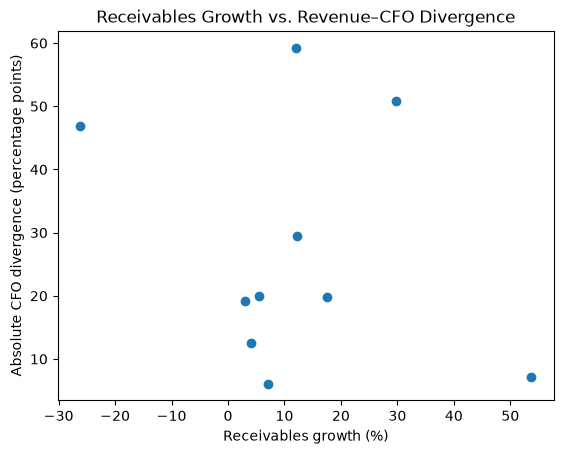

In [50]:
plt.scatter(
    analysis["receivables_growth"] * 100,
    analysis["abs_cfo_divergence"] * 100
)

plt.xlabel("Receivables growth (%)")
plt.ylabel("Absolute CFO divergence (percentage points)")
plt.title(
    "Receivables Growth vs. Revenue–CFO Divergence"
)

plt.show()

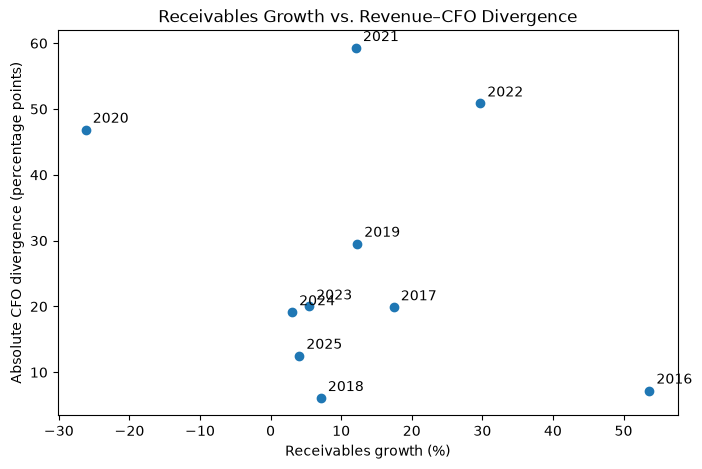

In [51]:
plt.figure(figsize=(8, 5))

plt.scatter(
    analysis["receivables_growth"] * 100,
    analysis["abs_cfo_divergence"] * 100
)

for _, row in analysis.dropna().iterrows():
    plt.annotate(
        str(int(row["year"])),
        (
            row["receivables_growth"] * 100,
            row["abs_cfo_divergence"] * 100
        ),
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.xlabel("Receivables growth (%)")
plt.ylabel("Absolute CFO divergence (percentage points)")
plt.title("Receivables Growth vs. Revenue–CFO Divergence")

plt.show()

In [52]:
[x for x in data["facts"]["us-gaap"].keys() if "Payable" in x]

['AccountsPayable',
 'AccountsPayableCurrent',
 'AccountsPayableTradeCurrent',
 'OtherAccountsPayableAndAccruedLiabilities']

In [53]:
payable_concepts = [
    "AccountsPayable",
    "AccountsPayableCurrent",
    "AccountsPayableTradeCurrent",
    "OtherAccountsPayableAndAccruedLiabilities",
]

for concept in payable_concepts:
    fact = data["facts"]["us-gaap"].get(concept)

    print(f"\n{'=' * 70}")
    print(concept)
    print(f"Label: {fact.get('label')}")
    print(f"Description: {fact.get('description')}")
    print(f"Units: {list(fact.get('units', {}).keys())}")


AccountsPayable
Label: Accounts Payable (Deprecated 2009-01-31)
Description: Carrying value as of the balance sheet date of liabilities incurred (and for which invoices have typically been received) and payable to vendors for goods and services received that are used in an entity's business. For classified balance sheets, used to reflect the current portion of the liabilities (due within one year or within the normal operating cycle if longer); for unclassified balance sheets, used to reflect the total liabilities (regardless of due date).
Units: ['USD']

AccountsPayableCurrent
Label: Accounts Payable, Current
Description: Carrying value as of the balance sheet date of liabilities incurred (and for which invoices have typically been received) and payable to vendors for goods and services received that are used in an entity's business. Used to reflect the current portion of the liabilities (due within one year or within the normal operating cycle if longer).
Units: ['USD']

AccountsPay

In [54]:
fact = data["facts"]["us-gaap"]["AccountsPayableTradeCurrent"]

print("Label:", fact["label"])

for unit, records in fact["units"].items():
    print("Unit:", unit)
    print("Number of facts:", len(records))

    for r in records[-10:]:
        print(
            r.get("end"),
            r.get("val"),
            r.get("fy"),
            r.get("fp"),
            r.get("form"),
            r.get("filed")
        )

Label: Accounts Payable, Trade, Current
Unit: USD
Number of facts: 124
2024-12-31 763000000 2025 Q3 10-Q 2025-11-04
2024-12-31 763000000 2025 FY 10-K 2026-02-10
2025-03-31 812000000 2025 Q1 10-Q 2025-05-06
2025-06-30 778000000 2025 Q2 10-Q 2025-08-05
2025-09-30 759000000 2025 Q3 10-Q 2025-11-04
2025-12-31 814000000 2025 FY 10-K 2026-02-10
2025-12-31 814000000 2026 Q1 10-Q 2026-05-06
2025-12-31 814000000 2026 Q2 10-Q 2026-08-03
2026-03-31 763000000 2026 Q1 10-Q 2026-05-06
2026-06-30 819000000 2026 Q2 10-Q 2026-08-03


In [55]:
payables = data["facts"]["us-gaap"]["AccountsPayableTradeCurrent"]["units"]["USD"]

payables_10k = [
    r for r in payables
    if r.get("form") == "10-K"
]

for r in payables_10k:
    print(
        r.get("end"),
        r.get("val"),
        r.get("fy"),
        r.get("filed")
    )

2010-12-31 634000000 2011 2012-02-16
2011-12-30 548000000 2011 2012-02-16
2011-12-30 548000000 2012 2013-02-20
2012-12-28 569000000 2012 2013-02-20
2012-12-28 569000000 2013 2014-02-20
2013-12-31 557000000 2013 2014-02-20
2013-12-31 557000000 2014 2015-02-19
2014-12-31 605000000 2014 2015-02-19
2014-12-31 605000000 2015 2016-02-18
2015-12-31 593000000 2015 2016-02-18
2015-12-31 593000000 2016 2017-02-21
2016-12-31 687000000 2016 2017-02-21
2016-12-31 687000000 2017 2018-02-15
2017-12-31 780000000 2017 2018-02-15
2017-12-31 783000000 2018 2019-03-01
2018-12-31 767000000 2018 2019-03-01
2018-12-31 767000000 2019 2020-02-27
2019-12-31 720000000 2019 2020-02-27
2019-12-31 720000000 2020 2021-02-18
2020-12-31 527000000 2020 2021-02-18
2020-12-31 527000000 2021 2022-02-15
2021-12-31 726000000 2021 2022-02-15
2021-12-31 726000000 2022 2023-02-14
2022-12-31 746000000 2022 2023-02-14
2022-12-31 746000000 2023 2024-02-13
2023-12-31 738000000 2023 2024-02-13
2023-12-31 738000000 2024 2025-02-11
2

In [56]:
payables_clean = (
    pd.DataFrame(payables_10k)
    .sort_values(["end", "filed"])
    .drop_duplicates(subset=["end"], keep="last")
    .copy()
)

payables_clean["fiscal_year"] = (
    pd.to_datetime(payables_clean["end"]).dt.year
)

payables_clean["payables"] = (
    payables_clean["val"] / 1_000_000
)

payables_clean = payables_clean[
    ["fiscal_year", "end", "payables", "filed"]
].reset_index(drop=True)

payables_clean

,fiscal_year,end,payables,filed
0,2010,2010-12-31,634.0,2012-02-16
1,2011,2011-12-30,548.0,2013-02-20
2,2012,2012-12-28,569.0,2014-02-20
3,2013,2013-12-31,557.0,2015-02-19
4,2014,2014-12-31,605.0,2016-02-18
5,2015,2015-12-31,593.0,2017-02-21
6,2016,2016-12-31,687.0,2018-02-15
7,2017,2017-12-31,783.0,2019-03-01
8,2018,2018-12-31,767.0,2020-02-27
9,2019,2019-12-31,720.0,2021-02-18


In [57]:
payables_clean["payables_growth"] = (
    payables_clean["payables"].pct_change()
)

payables_clean[
    ["fiscal_year", "payables", "payables_growth"]
].round(4)

,fiscal_year,payables,payables_growth
0,2010,634.0,NaN
1,2011,548.0,-0.1356
2,2012,569.0,0.0383
3,2013,557.0,-0.0211
4,2014,605.0,0.0862
5,2015,593.0,-0.0198
6,2016,687.0,0.1585
7,2017,783.0,0.1397
8,2018,767.0,-0.0204
9,2019,720.0,-0.0613


In [58]:
df = df.merge(
    payables_clean[["fiscal_year", "payables", "payables_growth"]],
    left_on="year",
    right_on="fiscal_year",
    how="left"
)


In [59]:
df = df.drop(columns="fiscal_year")

In [60]:
df.columns.tolist()

['year',
 'revenue',
 'receivables',
 'revenue_growth',
 'receivables_growth',
 'divergence',
 'abs_divergence',
 'period',
 'operating_cash_flow',
 'operating_cash_flow_growth',
 'cfo_divergence',
 'abs_cfo_divergence',
 'payables',
 'payables_growth']

In [61]:
df[
    [
        "year",
        "revenue_growth",
        "receivables_growth",
        "payables_growth",
        "operating_cash_flow_growth",
        "cfo_divergence"
    ]
].round(4)

,year,revenue_growth,receivables_growth,payables_growth,operating_cash_flow_growth,cfo_divergence
0,2015,NaN,NaN,-0.0198,NaN,NaN
1,2016,0.1785,0.5367,0.1585,0.1063,0.0722
2,2017,0.3410,0.1746,0.1397,0.5398,-0.1988
3,2018,-0.0933,0.0713,-0.0204,-0.0324,-0.0609
4,2019,0.0103,0.1228,-0.0613,-0.2851,0.2954
5,2020,-0.4959,-0.2618,-0.2681,-0.0273,-0.4686
6,2021,0.3109,0.1210,0.3776,-0.2819,0.5927
7,2022,0.4991,0.2972,0.0275,1.0076,-0.5085
8,2023,0.1415,0.0548,-0.0107,0.3415,-0.2000
9,2024,0.0585,0.0306,0.0339,-0.1328,0.1913


In [62]:
df[
    [
        "receivables_growth",
        "payables_growth",
        "cfo_divergence"
    ]
].corr().round(4)

,receivables_growth,payables_growth,cfo_divergence
receivables_growth,1.0000,0.5718,0.1887
payables_growth,0.5718,1.0000,0.6286
cfo_divergence,0.1887,0.6286,1.0000


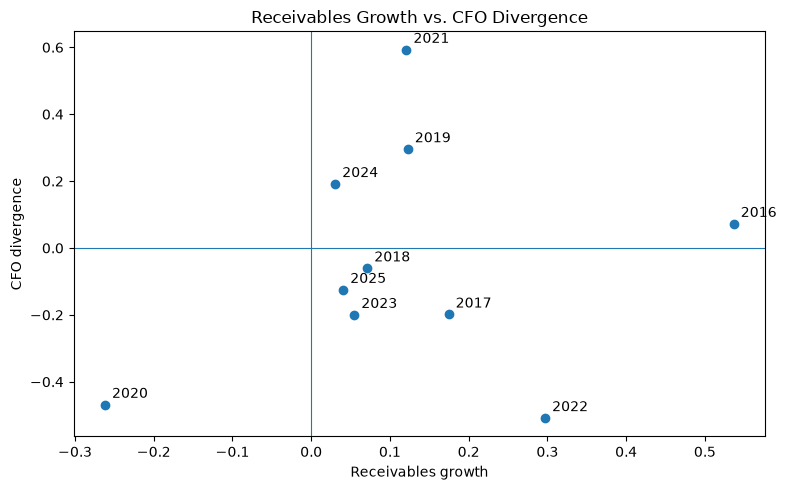

In [63]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["receivables_growth"],
    df["cfo_divergence"]
)

# Add year labels to each observation
for _, row in df.dropna(
    subset=["receivables_growth", "cfo_divergence"]
).iterrows():
    plt.annotate(
        int(row["year"]),
        (row["receivables_growth"], row["cfo_divergence"]),
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.axhline(0, linewidth=0.8)
plt.axvline(0, linewidth=0.8)

plt.xlabel("Receivables growth")
plt.ylabel("CFO divergence")
plt.title("Receivables Growth vs. CFO Divergence")

plt.tight_layout()
plt.show()

In [64]:
df[
    ["receivables_growth", "cfo_divergence"]
].corr().round(4)

,receivables_growth,cfo_divergence
receivables_growth,1.0000,0.1887
cfo_divergence,0.1887,1.0000


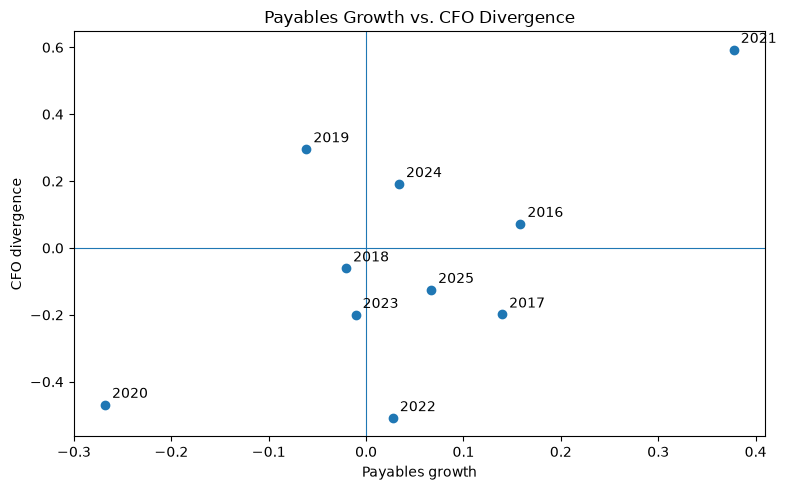

In [65]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["payables_growth"],
    df["cfo_divergence"]
)

for _, row in df.dropna(
    subset=["payables_growth", "cfo_divergence"]
).iterrows():
    plt.annotate(
        int(row["year"]),
        (row["payables_growth"], row["cfo_divergence"]),
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.axhline(0, linewidth=0.8)
plt.axvline(0, linewidth=0.8)

plt.xlabel("Payables growth")
plt.ylabel("CFO divergence")
plt.title("Payables Growth vs. CFO Divergence")

plt.tight_layout()
plt.show()

In [66]:
df[
    ["payables_growth", "cfo_divergence"]
].corr().round(4)

,payables_growth,cfo_divergence
payables_growth,1.0000,0.6286
cfo_divergence,0.6286,1.0000


In [67]:
df["receivables_change"] = df["receivables"].diff()
df["payables_change"] = df["payables"].diff()

In [68]:
df[
    [
        "year",
        "receivables",
        "receivables_change",
        "payables",
        "payables_change",
        "operating_cash_flow"
    ]
].round(2)

,year,receivables,receivables_change,payables,payables_change,operating_cash_flow
0,2015,1103000000,NaN,593.0,NaN,1430000000
1,2016,1695000000,592000000.0,687.0,94.0,1582000000
2,2017,1991000000,296000000.0,783.0,96.0,2436000000
3,2018,2133000000,142000000.0,767.0,-16.0,2357000000
4,2019,2395000000,262000000.0,720.0,-47.0,1685000000
5,2020,1768000000,-627000000.0,527.0,-193.0,1639000000
6,2021,1982000000,214000000.0,726.0,199.0,1177000000
7,2022,2571000000,589000000.0,746.0,20.0,2363000000
8,2023,2712000000,141000000.0,738.0,-8.0,3170000000
9,2024,2795000000,83000000.0,763.0,25.0,2749000000


In [69]:
df[
    ["receivables_change", "cfo_divergence"]
].corr().round(4)

,receivables_change,cfo_divergence
receivables_change,1.0000,0.2142
cfo_divergence,0.2142,1.0000


In [70]:
df[
    ["payables_change", "cfo_divergence"]
].corr().round(4)

,payables_change,cfo_divergence
payables_change,1.0000,0.5756
cfo_divergence,0.5756,1.0000


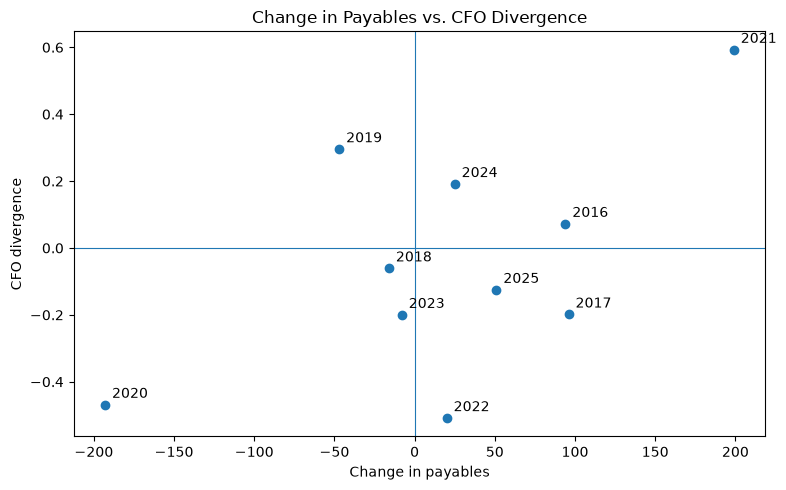

In [71]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["payables_change"],
    df["cfo_divergence"]
)

for _, row in df.dropna(
    subset=["payables_change", "cfo_divergence"]
).iterrows():
    plt.annotate(
        int(row["year"]),
        (row["payables_change"], row["cfo_divergence"]),
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.axhline(0, linewidth=0.8)
plt.axvline(0, linewidth=0.8)

plt.xlabel("Change in payables")
plt.ylabel("CFO divergence")
plt.title("Change in Payables vs. CFO Divergence")

plt.tight_layout()
plt.show()

In [72]:
df[
    ["payables_change", "cfo_divergence"]
].corr().round(4)

,payables_change,cfo_divergence
payables_change,1.0000,0.5756
cfo_divergence,0.5756,1.0000


In [73]:
df[
    [
        "year",
        "payables",
        "payables_change",
        "payables_growth",
        "cfo_divergence"
    ]
].round(4)

,year,payables,payables_change,payables_growth,cfo_divergence
0,2015,593.0,NaN,-0.0198,NaN
1,2016,687.0,94.0,0.1585,0.0722
2,2017,783.0,96.0,0.1397,-0.1988
3,2018,767.0,-16.0,-0.0204,-0.0609
4,2019,720.0,-47.0,-0.0613,0.2954
5,2020,527.0,-193.0,-0.2681,-0.4686
6,2021,726.0,199.0,0.3776,0.5927
7,2022,746.0,20.0,0.0275,-0.5085
8,2023,738.0,-8.0,-0.0107,-0.2000
9,2024,763.0,25.0,0.0339,0.1913


That is important for an audit-oriented analysis: we shouldn't write “higher payables cause higher CFO divergence.” A safer conclusion is that changes in payables are associated with CFO divergence in this sample, but the relationship is sensitive to a small number of exceptional years.

In [74]:
df_normal = df[
    ~df["year"].isin([2020, 2021])
]

df_normal[
    ["payables_change", "cfo_divergence"]
].corr().round(4)

,payables_change,cfo_divergence
payables_change,1.0000,-0.2305
cfo_divergence,-0.2305,1.0000


The apparent relationship between changes in payables and CFO divergence in Marriott's 2015–2025 data is largely driven by the COVID/recovery period rather than representing a consistent relationship across the full period.

In [75]:
df_normal[
    ["receivables_change", "cfo_divergence"]
].corr().round(4)

,receivables_change,cfo_divergence
receivables_change,1.0000,-0.3416
cfo_divergence,-0.3416,1.0000


Once the exceptional 2020–2021 period is removed, both relationships become moderately negative.
our analysis suggests:

Payables showed the stronger raw correlation with CFO divergence (+0.5756).
That relationship is largely associated with the unusual 2020–2021 period.
Outside that period, the relationship becomes negative (−0.2305).
Receivables behaves similarly: +0.2142 overall, but −0.3416 excluding 2020–2021.
With only 9 observations after excluding those two years, these correlations remain exploratory.

In [76]:
df["payables_change_usd"] = df["payables_change"] * 1_000_000

df["working_capital_cash_effect"] = (
    df["payables_change_usd"] - df["receivables_change"]
)

df[
    [
        "year",
        "receivables_change",
        "payables_change_usd",
        "working_capital_cash_effect",
        "operating_cash_flow"
    ]
].round(0)

,year,receivables_change,payables_change_usd,working_capital_cash_effect,operating_cash_flow
0,2015,NaN,NaN,NaN,1430000000
1,2016,592000000.0,94000000.0,-498000000.0,1582000000
2,2017,296000000.0,96000000.0,-200000000.0,2436000000
3,2018,142000000.0,-16000000.0,-158000000.0,2357000000
4,2019,262000000.0,-47000000.0,-309000000.0,1685000000
5,2020,-627000000.0,-193000000.0,434000000.0,1639000000
6,2021,214000000.0,199000000.0,-15000000.0,1177000000
7,2022,589000000.0,20000000.0,-569000000.0,2363000000
8,2023,141000000.0,-8000000.0,-149000000.0,3170000000
9,2024,83000000.0,25000000.0,-58000000.0,2749000000


In [77]:
df["working_capital_effect_pct_cfo"] = (
    df["working_capital_cash_effect"] / df["operating_cash_flow"] *100
)

df[
    [
        "year",
        "working_capital_cash_effect",
        "operating_cash_flow",
        "working_capital_effect_pct_cfo"
    ]
].round(2)

,year,working_capital_cash_effect,operating_cash_flow,working_capital_effect_pct_cfo
0,2015,NaN,1430000000,NaN
1,2016,-498000000.0,1582000000,-31.48
2,2017,-200000000.0,2436000000,-8.21
3,2018,-158000000.0,2357000000,-6.70
4,2019,-309000000.0,1685000000,-18.34
5,2020,434000000.0,1639000000,26.48
6,2021,-15000000.0,1177000000,-1.27
7,2022,-569000000.0,2363000000,-24.08
8,2023,-149000000.0,3170000000,-4.70
9,2024,-58000000.0,2749000000,-2.11


In [78]:
df["wc_effect_pct_revenue"] = (
    df["working_capital_cash_effect"] / df["revenue"] * 100
)

df["wc_effect_pct_cfo"] = (
    df["working_capital_cash_effect"] / df["operating_cash_flow"] * 100
)

In [79]:
df[
    [
        "year",
        "working_capital_cash_effect",
        "revenue",
        "operating_cash_flow",
        "wc_effect_pct_revenue",
        "wc_effect_pct_cfo"
    ]
].round(2)

,year,working_capital_cash_effect,revenue,operating_cash_flow,wc_effect_pct_revenue,wc_effect_pct_cfo
0,2015,NaN,14486000000,1430000000,NaN,NaN
1,2016,-498000000.0,17072000000,1582000000,-2.92,-31.48
2,2017,-200000000.0,22894000000,2436000000,-0.87,-8.21
3,2018,-158000000.0,20758000000,2357000000,-0.76,-6.70
4,2019,-309000000.0,20972000000,1685000000,-1.47,-18.34
5,2020,434000000.0,10571000000,1639000000,4.11,26.48
6,2021,-15000000.0,13857000000,1177000000,-0.11,-1.27
7,2022,-569000000.0,20773000000,2363000000,-2.74,-24.08
8,2023,-149000000.0,23713000000,3170000000,-0.63,-4.70
9,2024,-58000000.0,25100000000,2749000000,-0.23,-2.11


In [80]:
[x for x in data["facts"]["us-gaap"] if "Asset" in x][:50]

['AmortizationOfIntangibleAssets',
 'AssetImpairmentCharges',
 'Assets',
 'AssetsCurrent',
 'AssetsDisposedOfByMethodOtherThanSaleInPeriodOfDispositionGainLossOnDisposition',
 'AssetsDisposedOfByMethodOtherThanSaleInPeriodOfDispositionGainLossOnDisposition1',
 'AssetsHeldForSaleCurrent',
 'AssetsOfDisposalGroupIncludingDiscontinuedOperation',
 'AssetsOfDisposalGroupIncludingDiscontinuedOperationCurrent',
 'CapitalLeasedAssetsGross',
 'CapitalLeasesBalanceSheetAssetsByMajorClassNet',
 'CapitalLeasesLesseeBalanceSheetAssetsByMajorClassAccumulatedDeprecation',
 'CashFlowsBetweenSecuritizationSpecialPurposeEntitySPEAndTransferorProceedsFromNewlySecuritizedAssets',
 'CashFlowsBetweenSecuritizationSpecialPurposeEntitySPEAndTransferorPurchasesOfDelinquentOrForeclosedAssets',
 'CashFlowsBetweenTransfereeAndTransferorPurchasesOfPreviouslyTransferredFinancialAssets',
 'DeferredIncomeTaxAssetsNet',
 'DeferredTaxAssetsDeferredIncome',
 'DeferredTaxAssetsEquityMethodInvestments',
 'DeferredTaxAsset

In [81]:
[x for x in data["facts"]["us-gaap"]
 if "Income" in x or "Earnings" in x][:50]

['AccumulatedOtherComprehensiveIncomeLossAvailableForSaleSecuritiesAdjustmentNetOfTax',
 'AccumulatedOtherComprehensiveIncomeLossCumulativeChangesInNetGainLossFromCashFlowHedgesEffectNetOfTax',
 'AccumulatedOtherComprehensiveIncomeLossForeignCurrencyTranslationAdjustmentNetOfTax',
 'AccumulatedOtherComprehensiveIncomeLossNetOfTax',
 'AntidilutiveSecuritiesExcludedFromComputationOfEarningsPerShareAmount',
 'ComprehensiveIncomeNetOfTax',
 'ComprehensiveIncomeNetOfTaxIncludingPortionAttributableToNoncontrollingInterest',
 'CurrentIncomeTaxExpenseBenefit',
 'DeferredFederalIncomeTaxExpenseBenefit',
 'DeferredForeignIncomeTaxExpenseBenefit',
 'DeferredIncomeTaxAssetsNet',
 'DeferredIncomeTaxExpenseBenefit',
 'DeferredIncomeTaxLiabilities',
 'DeferredIncomeTaxLiabilitiesNet',
 'DeferredStateAndLocalIncomeTaxExpenseBenefit',
 'DeferredTaxAssetsDeferredIncome',
 'DiscontinuedOperationIncomeLossFromDiscontinuedOperationBeforeIncomeTax',
 'DiscontinuedOperationTaxEffectOfIncomeLossFromDiscontinu

In [82]:
for concept in [
    "Assets",
    "IncomeLossFromContinuingOperationsBeforeIncomeTaxesExtraordinaryItemsNoncontrollingInterest"
]:
    print("\n", concept)
    print(data["facts"]["us-gaap"][concept]["label"])
    print(data["facts"]["us-gaap"][concept]["description"])
    print(data["facts"]["us-gaap"][concept]["units"].keys())


 Assets
Assets
Sum of the carrying amounts as of the balance sheet date of all assets that are recognized. Assets are probable future economic benefits obtained or controlled by an entity as a result of past transactions or events.
dict_keys(['USD'])

 IncomeLossFromContinuingOperationsBeforeIncomeTaxesExtraordinaryItemsNoncontrollingInterest
Income (Loss) from Continuing Operations before Income Taxes, Noncontrolling Interest
Amount of income (loss) from continuing operations, including income (loss) from equity method investments, before deduction of income tax expense (benefit), and income (loss) attributable to noncontrolling interest.
dict_keys(['USD'])


In [83]:
for concept in [
    "Assets",
    "IncomeLossFromContinuingOperationsBeforeIncomeTaxesExtraordinaryItemsNoncontrollingInterest"
]:
    print("\n" + "=" * 80)
    print(concept)

    facts = data["facts"]["us-gaap"][concept]["units"]["USD"]

    for fact in facts:
        if fact.get("form") == "10-K":
            print(
                fact.get("fy"),
                fact.get("fp"),
                fact.get("end"),
                fact.get("val"),
                fact.get("accn")
            )


Assets
2009 FY 2009-01-02 8903000000 0001193125-10-030603
2009 FY 2010-01-01 7933000000 0001193125-10-030603
2010 FY 2010-01-01 7933000000 0001193125-11-039869
2010 FY 2010-12-31 8983000000 0001193125-11-039869
2011 FY 2010-12-31 8983000000 0001445305-12-000342
2011 FY 2011-12-30 5910000000 0001445305-12-000342
2012 FY 2011-12-30 5910000000 0001445305-13-000255
2012 FY 2012-12-28 6342000000 0001445305-13-000255
2013 FY 2012-12-28 6342000000 0001445305-14-000495
2013 FY 2013-12-31 6794000000 0001445305-14-000495
2014 FY 2013-12-31 6794000000 0001628280-15-000842
2014 FY 2014-12-31 6865000000 0001628280-15-000842
2015 FY 2014-12-31 6833000000 0001628280-16-011346
2015 FY 2015-12-31 6082000000 0001628280-16-011346
2016 FY 2015-12-31 6082000000 0001628280-17-001506
2016 FY 2016-12-31 24140000000 0001628280-17-001506
2017 FY 2016-12-31 24140000000 0001628280-18-001756
2017 FY 2017-12-31 23948000000 0001628280-18-001756
2018 FY 2017-12-31 23846000000 0001628280-19-002337
2018 FY 2018-12-31 

In [84]:
def get_original_annual_fact(data, concept, start_year=2015, end_year=2025):
    facts = data["facts"]["us-gaap"][concept]["units"]["USD"]

    records = []

    for fact in facts:
        if fact.get("form") != "10-K":
            continue

        fy = fact.get("fy")
        end = fact.get("end")

        if fy is None or end is None:
            continue

        if start_year <= fy <= end_year:
            records.append({
                "year": fy,
                "end": end,
                "value": fact["val"],
                "filed": fact.get("filed"),
                "accn": fact.get("accn")
            })

    return pd.DataFrame(records)

In [85]:
assets_df = get_original_annual_fact(
    data,
    "Assets"
)

pbt_df = get_original_annual_fact(
    data,
    "IncomeLossFromContinuingOperationsBeforeIncomeTaxesExtraordinaryItemsNoncontrollingInterest"
)

In [86]:
assets_df

,year,end,value,filed,accn
0,2015,2014-12-31,6833000000,2016-02-18,0001628280-16-011346
1,2015,2015-12-31,6082000000,2016-02-18,0001628280-16-011346
2,2016,2015-12-31,6082000000,2017-02-21,0001628280-17-001506
3,2016,2016-12-31,24140000000,2017-02-21,0001628280-17-001506
4,2017,2016-12-31,24140000000,2018-02-15,0001628280-18-001756
5,2017,2017-12-31,23948000000,2018-02-15,0001628280-18-001756
6,2018,2017-12-31,23846000000,2019-03-01,0001628280-19-002337
7,2018,2018-12-31,23696000000,2019-03-01,0001628280-19-002337
8,2019,2018-12-31,23696000000,2020-02-27,0001628280-20-002376
9,2019,2019-12-31,25051000000,2020-02-27,0001628280-20-002376


In [87]:
pbt_df

,year,end,value,filed,accn
0,2015,2013-12-31,897000000,2016-02-18,0001628280-16-011346
1,2015,2014-12-31,1088000000,2016-02-18,0001628280-16-011346
2,2016,2014-12-31,1088000000,2017-02-21,0001628280-17-001506
3,2015,2015-12-31,1255000000,2016-02-18,0001628280-16-011346
4,2016,2015-12-31,1255000000,2017-02-21,0001628280-17-001506
5,2017,2015-12-31,1255000000,2018-02-15,0001628280-18-001756
6,2016,2016-12-31,1184000000,2017-02-21,0001628280-17-001506
7,2017,2016-12-31,1184000000,2018-02-15,0001628280-18-001756
8,2018,2016-12-31,1239000000,2019-03-01,0001628280-19-002337
9,2017,2017-12-31,2836000000,2018-02-15,0001628280-18-001756


In [88]:
assets_annual = assets_df[
    assets_df["end"].str[:4].astype(int) == assets_df["year"]
].copy()

pbt_annual = pbt_df[
    (pbt_df["end"].str[:4].astype(int) == pbt_df["year"])
    & (pbt_df["end"].str.endswith("-12-31"))
].copy()

In [89]:
assets_annual

,year,end,value,filed,accn
1,2015,2015-12-31,6082000000,2016-02-18,0001628280-16-011346
3,2016,2016-12-31,24140000000,2017-02-21,0001628280-17-001506
5,2017,2017-12-31,23948000000,2018-02-15,0001628280-18-001756
7,2018,2018-12-31,23696000000,2019-03-01,0001628280-19-002337
9,2019,2019-12-31,25051000000,2020-02-27,0001628280-20-002376
11,2020,2020-12-31,24701000000,2021-02-18,0001628280-21-002433
13,2021,2021-12-31,25553000000,2022-02-15,0001628280-22-002666
15,2022,2022-12-31,24815000000,2023-02-14,0001628280-23-003485
17,2023,2023-12-31,25674000000,2024-02-13,0001628280-24-004372
19,2024,2024-12-31,26182000000,2025-02-11,0001628280-25-004818


In [90]:
pbt_annual

,year,end,value,filed,accn
3,2015,2015-12-31,1255000000,2016-02-18,0001628280-16-011346
6,2016,2016-12-31,1184000000,2017-02-21,0001628280-17-001506
9,2017,2017-12-31,2836000000,2018-02-15,0001628280-18-001756
15,2018,2018-12-31,2345000000,2019-03-01,0001628280-19-002337
18,2019,2019-12-31,1599000000,2020-02-27,0001628280-20-002376
21,2020,2020-12-31,-466000000,2021-02-18,0001628280-21-002433
24,2021,2021-12-31,1180000000,2022-02-15,0001628280-22-002666
27,2022,2022-12-31,3114000000,2023-02-14,0001628280-23-003485
30,2023,2023-12-31,3378000000,2024-02-13,0001628280-24-004372
33,2024,2024-12-31,3151000000,2025-02-11,0001628280-25-004818


In [91]:
benchmark_df = (
    assets_annual[["year", "value"]]
    .rename(columns={"value": "total_assets"})
    .merge(
        pbt_annual[["year", "value"]]
        .rename(columns={"value": "profit_before_tax"}),
        on="year",
        how="inner"
    )
)

df = df.merge(
    benchmark_df,
    on="year",
    how="left"
)

df[[
    "year",
    "revenue",
    "operating_cash_flow",
    "total_assets",
    "profit_before_tax"
]]

,year,revenue,operating_cash_flow,total_assets,profit_before_tax
0,2015,14486000000,1430000000,6082000000,1255000000
1,2016,17072000000,1582000000,24140000000,1184000000
2,2017,22894000000,2436000000,23948000000,2836000000
3,2018,20758000000,2357000000,23696000000,2345000000
4,2019,20972000000,1685000000,25051000000,1599000000
5,2020,10571000000,1639000000,24701000000,-466000000
6,2021,13857000000,1177000000,25553000000,1180000000
7,2022,20773000000,2363000000,24815000000,3114000000
8,2023,23713000000,3170000000,25674000000,3378000000
9,2024,25100000000,2749000000,26182000000,3151000000


In [92]:
df["wc_effect_pct_assets"] = (
    df["working_capital_cash_effect"]
    / df["total_assets"]
    * 100
)

df[[
    "year",
    "working_capital_cash_effect",
    "total_assets",
    "wc_effect_pct_assets"
]]

,year,working_capital_cash_effect,total_assets,wc_effect_pct_assets
0,2015,NaN,6082000000,NaN
1,2016,-498000000.0,24140000000,-2.062966
2,2017,-200000000.0,23948000000,-0.835143
3,2018,-158000000.0,23696000000,-0.666779
4,2019,-309000000.0,25051000000,-1.233484
5,2020,434000000.0,24701000000,1.757014
6,2021,-15000000.0,25553000000,-0.058702
7,2022,-569000000.0,24815000000,-2.292968
8,2023,-149000000.0,25674000000,-0.580354
9,2024,-58000000.0,26182000000,-0.221526


In [93]:
df["wc_effect_pct_pbt"] = np.where(
    df["profit_before_tax"] > 0,
    df["working_capital_cash_effect"]
    / df["profit_before_tax"]
    * 100,
    np.nan
)

df[[
    "year",
    "working_capital_cash_effect",
    "profit_before_tax",
    "wc_effect_pct_pbt"
]]

,year,working_capital_cash_effect,profit_before_tax,wc_effect_pct_pbt
0,2015,NaN,1255000000,NaN
1,2016,-498000000.0,1184000000,-42.060811
2,2017,-200000000.0,2836000000,-7.052186
3,2018,-158000000.0,2345000000,-6.737740
4,2019,-309000000.0,1599000000,-19.324578
5,2020,434000000.0,-466000000,NaN
6,2021,-15000000.0,1180000000,-1.271186
7,2022,-569000000.0,3114000000,-18.272319
8,2023,-149000000.0,3378000000,-4.410894
9,2024,-58000000.0,3151000000,-1.840685


In [94]:
audit_flags = df[
    (
        df["wc_effect_pct_cfo"].abs() >= 15
    )
    |
    (
        df["wc_effect_pct_pbt"].abs() >= 15
    )
].copy()

audit_flags = audit_flags[
    [
        "year",
        "working_capital_cash_effect",
        "wc_effect_pct_cfo",
        "wc_effect_pct_pbt"
    ]
].sort_values("year")

audit_flags

,year,working_capital_cash_effect,wc_effect_pct_cfo,wc_effect_pct_pbt
1,2016,-498000000.0,-31.479140,-42.060811
4,2019,-309000000.0,-18.338279,-19.324578
5,2020,434000000.0,26.479561,NaN
7,2022,-569000000.0,-24.079560,-18.272319


In [95]:
def get_flag_reason(row, threshold=15):
    reasons = []

    if abs(row["wc_effect_pct_cfo"]) >= threshold:
        reasons.append("Large relative to CFO")

    if pd.notna(row["wc_effect_pct_pbt"]) and abs(row["wc_effect_pct_pbt"]) >= threshold:
        reasons.append("Large relative to PBT")

    return " + ".join(reasons)


audit_flags["flag_reason"] = audit_flags.apply(
    get_flag_reason,
    axis=1
)

audit_flags

,year,working_capital_cash_effect,wc_effect_pct_cfo,wc_effect_pct_pbt,flag_reason
1,2016,-498000000.0,-31.479140,-42.060811,Large relative to CFO + Large relative to PBT
4,2019,-309000000.0,-18.338279,-19.324578,Large relative to CFO + Large relative to PBT
5,2020,434000000.0,26.479561,NaN,Large relative to CFO
7,2022,-569000000.0,-24.079560,-18.272319,Large relative to CFO + Large relative to PBT


In [96]:
audit_flags_display = audit_flags.copy()

audit_flags_display["working_capital_cash_effect"] = (
    audit_flags_display["working_capital_cash_effect"] / 1_000_000
).round(0)

audit_flags_display["wc_effect_pct_cfo"] = (
    audit_flags_display["wc_effect_pct_cfo"].round(1)
)

audit_flags_display["wc_effect_pct_pbt"] = (
    audit_flags_display["wc_effect_pct_pbt"].round(1)
)

audit_flags_display = audit_flags_display.rename(
    columns={
        "working_capital_cash_effect": "WC effect ($M)",
        "wc_effect_pct_cfo": "WC effect / CFO (%)",
        "wc_effect_pct_pbt": "WC effect / PBT (%)",
        "flag_reason": "Flag reason"
    }
)

audit_flags_display

,year,WC effect ($M),WC effect / CFO (%),WC effect / PBT (%),Flag reason
1,2016,-498.0,-31.5,-42.1,Large relative to CFO + Large relative to PBT
4,2019,-309.0,-18.3,-19.3,Large relative to CFO + Large relative to PBT
5,2020,434.0,26.5,NaN,Large relative to CFO
7,2022,-569.0,-24.1,-18.3,Large relative to CFO + Large relative to PBT


In [97]:
def get_audit_interpretation(row):
    year = row["year"]

    if year == 2016:
        return (
            "Large working-capital cash outflow relative to CFO and PBT",
            "Investigate receivables growth, collection patterns, and acquisition-related effects"
        )

    if year == 2019:
        return (
            "Large working-capital cash outflow relative to CFO and PBT",
            "Investigate receivables increase and deterioration in operating cash conversion"
        )

    if year == 2020:
        return (
            "Large working-capital cash inflow during an exceptional year",
            "Investigate COVID-related changes in activity, collections, and payment patterns"
        )

    if year == 2022:
        return (
            "Largest working-capital cash outflow in the period",
            "Investigate receivables growth, collection patterns, and subsequent cash receipts"
        )

    return ("", "")

In [98]:
audit_flags[
    ["analytical_signal", "audit_focus"]
] = audit_flags.apply(
    get_audit_interpretation,
    axis=1,
    result_type="expand"
)
audit_flags

,year,working_capital_cash_effect,wc_effect_pct_cfo,wc_effect_pct_pbt,flag_reason,analytical_signal,audit_focus
1,2016,-498000000.0,-31.479140,-42.060811,Large relative to CFO + Large relative to PBT,Large working-capital cash outflow relative to...,"Investigate receivables growth, collection pat..."
4,2019,-309000000.0,-18.338279,-19.324578,Large relative to CFO + Large relative to PBT,Large working-capital cash outflow relative to...,Investigate receivables increase and deteriora...
5,2020,434000000.0,26.479561,NaN,Large relative to CFO,Large working-capital cash inflow during an ex...,"Investigate COVID-related changes in activity,..."
7,2022,-569000000.0,-24.079560,-18.272319,Large relative to CFO + Large relative to PBT,Largest working-capital cash outflow in the pe...,"Investigate receivables growth, collection pat..."


In [99]:
audit_interpretation = audit_flags_display.copy()

audit_interpretation[
    ["analytical_signal", "audit_focus"]
] = audit_flags[
    ["analytical_signal", "audit_focus"]
].values

audit_interpretation

,year,WC effect ($M),WC effect / CFO (%),WC effect / PBT (%),Flag reason,analytical_signal,audit_focus
1,2016,-498.0,-31.5,-42.1,Large relative to CFO + Large relative to PBT,Large working-capital cash outflow relative to...,"Investigate receivables growth, collection pat..."
4,2019,-309.0,-18.3,-19.3,Large relative to CFO + Large relative to PBT,Large working-capital cash outflow relative to...,Investigate receivables increase and deteriora...
5,2020,434.0,26.5,NaN,Large relative to CFO,Large working-capital cash inflow during an ex...,"Investigate COVID-related changes in activity,..."
7,2022,-569.0,-24.1,-18.3,Large relative to CFO + Large relative to PBT,Largest working-capital cash outflow in the pe...,"Investigate receivables growth, collection pat..."


In [100]:
df.loc[
    df["year"] == 2022,
    [
        "year",
        "revenue_growth",
        "receivables_growth",
        "receivables_change",
        "working_capital_cash_effect",
        "operating_cash_flow"
    ]
]

,year,revenue_growth,receivables_growth,receivables_change,working_capital_cash_effect,operating_cash_flow
7,2022,0.499098,0.297175,589000000.0,-569000000.0,2363000000


In [101]:
df["receivables_revenue_growth_gap"] = (
    df["receivables_growth"]
    - df["revenue_growth"]
)

df[[
    "year",
    "revenue_growth",
    "receivables_growth",
    "receivables_revenue_growth_gap"
]].round(4)

,year,revenue_growth,receivables_growth,receivables_revenue_growth_gap
0,2015,NaN,NaN,NaN
1,2016,0.1785,0.5367,0.3582
2,2017,0.3410,0.1746,-0.1664
3,2018,-0.0933,0.0713,0.1646
4,2019,0.0103,0.1228,0.1125
5,2020,-0.4959,-0.2618,0.2342
6,2021,0.3109,0.1210,-0.1898
7,2022,0.4991,0.2972,-0.2019
8,2023,0.1415,0.0548,-0.0867
9,2024,0.0585,0.0306,-0.0279


In [102]:
comparison_years = [2016, 2019, 2020]

audit_comparison = df[
    df["year"].isin(comparison_years)
][[
    "year",
    "revenue",
    "revenue_growth",
    "receivables",
    "receivables_growth",
    "receivables_revenue_growth_gap",
    "working_capital_cash_effect",
    "operating_cash_flow",
    "wc_effect_pct_cfo",
    "profit_before_tax",
    "wc_effect_pct_pbt"
]].copy()

audit_comparison

,year,revenue,revenue_growth,receivables,receivables_growth,receivables_revenue_growth_gap,working_capital_cash_effect,operating_cash_flow,wc_effect_pct_cfo,profit_before_tax,wc_effect_pct_pbt
1,2016,17072000000,0.178517,1695000000,0.536718,0.358201,-498000000.0,1582000000,-31.479140,1184000000,-42.060811
4,2019,20972000000,0.010309,2395000000,0.122832,0.112522,-309000000.0,1685000000,-18.338279,1599000000,-19.324578
5,2020,10571000000,-0.495947,1768000000,-0.261795,0.234152,434000000.0,1639000000,26.479561,-466000000,NaN


In [103]:
audit_comparison_display = audit_comparison.copy()

for col in [
    "revenue",
    "receivables",
    "working_capital_cash_effect",
    "operating_cash_flow",
    "profit_before_tax"
]:
    audit_comparison_display[col] = (
        audit_comparison_display[col] / 1_000_000
    ).round(0)

for col in [
    "revenue_growth",
    "receivables_growth",
    "receivables_revenue_growth_gap"
]:
    audit_comparison_display[col] = (
        audit_comparison_display[col] * 100
    ).round(1)

for col in [
    "wc_effect_pct_cfo",
    "wc_effect_pct_pbt"
]:
    audit_comparison_display[col] = (
        audit_comparison_display[col]
    ).round(1)

audit_comparison_display

,year,revenue,revenue_growth,receivables,receivables_growth,receivables_revenue_growth_gap,working_capital_cash_effect,operating_cash_flow,wc_effect_pct_cfo,profit_before_tax,wc_effect_pct_pbt
1,2016,17072.0,17.9,1695.0,53.7,35.8,-498.0,1582.0,-31.5,1184.0,-42.1
4,2019,20972.0,1.0,2395.0,12.3,11.3,-309.0,1685.0,-18.3,1599.0,-19.3
5,2020,10571.0,-49.6,1768.0,-26.2,23.4,434.0,1639.0,26.5,-466.0,NaN


In [104]:
comparison_years = [2016, 2019, 2020, 2022]

audit_comparison = df[
    df["year"].isin(comparison_years)
][[
    "year",
    "revenue_growth",
    "receivables_growth",
    "receivables_revenue_growth_gap",
    "working_capital_cash_effect",
    "wc_effect_pct_cfo",
    "wc_effect_pct_pbt"
]].copy()

audit_comparison

,year,revenue_growth,receivables_growth,receivables_revenue_growth_gap,working_capital_cash_effect,wc_effect_pct_cfo,wc_effect_pct_pbt
1,2016,0.178517,0.536718,0.358201,-498000000.0,-31.479140,-42.060811
4,2019,0.010309,0.122832,0.112522,-309000000.0,-18.338279,-19.324578
5,2020,-0.495947,-0.261795,0.234152,434000000.0,26.479561,NaN
7,2022,0.499098,0.297175,-0.201923,-569000000.0,-24.079560,-18.272319


In [105]:
audit_comparison_display = audit_comparison.copy()

audit_comparison_display["working_capital_cash_effect"] = (
    audit_comparison_display["working_capital_cash_effect"]
    / 1_000_000
).round(0)

for col in [
    "revenue_growth",
    "receivables_growth",
    "receivables_revenue_growth_gap"
]:
    audit_comparison_display[col] = (
        audit_comparison_display[col] * 100
    ).round(1)

for col in [
    "wc_effect_pct_cfo",
    "wc_effect_pct_pbt"
]:
    audit_comparison_display[col] = (
        audit_comparison_display[col]
    ).round(1)

audit_comparison_display

,year,revenue_growth,receivables_growth,receivables_revenue_growth_gap,working_capital_cash_effect,wc_effect_pct_cfo,wc_effect_pct_pbt
1,2016,17.9,53.7,35.8,-498.0,-31.5,-42.1
4,2019,1.0,12.3,11.3,-309.0,-18.3,-19.3
5,2020,-49.6,-26.2,23.4,434.0,26.5,NaN
7,2022,49.9,29.7,-20.2,-569.0,-24.1,-18.3


In [106]:
def get_growth_signal(row):
    gap = row["receivables_revenue_growth_gap"]

    if gap >= 0.10:
        return "Receivables grew materially faster than revenue"
    elif gap <= -0.10:
        return "Revenue grew materially faster than receivables"
    else:
        return "Receivables and revenue growth broadly aligned"


audit_comparison["growth_relationship_signal"] = audit_comparison.apply(
    get_growth_signal,
    axis=1
)

audit_comparison[
    [
        "year",
        "receivables_revenue_growth_gap",
        "growth_relationship_signal"
    ]
]

,year,receivables_revenue_growth_gap,growth_relationship_signal
1,2016,0.358201,Receivables grew materially faster than revenue
4,2019,0.112522,Receivables grew materially faster than revenue
5,2020,0.234152,Receivables grew materially faster than revenue
7,2022,-0.201923,Revenue grew materially faster than receivables


In [107]:
def get_cash_flow_signal(row, threshold=15):
    pct = abs(row["wc_effect_pct_cfo"])

    if pct >= threshold:
        return "Large relative to CFO"
    else:
        return "Not large relative to CFO"


audit_comparison["cash_flow_signal"] = audit_comparison.apply(
    get_cash_flow_signal,
    axis=1
)

audit_comparison[
    [
        "year",
        "wc_effect_pct_cfo",
        "cash_flow_signal"
    ]
]

,year,wc_effect_pct_cfo,cash_flow_signal
1,2016,-31.479140,Large relative to CFO
4,2019,-18.338279,Large relative to CFO
5,2020,26.479561,Large relative to CFO
7,2022,-24.079560,Large relative to CFO


In [108]:
def get_profit_signal(row, threshold=15):
    pct = row["wc_effect_pct_pbt"]

    if pd.isna(pct):
        return "Not applicable"
    elif abs(pct) >= threshold:
        return "Large relative to PBT"
    else:
        return "Not large relative to PBT"


audit_comparison["profit_signal"] = audit_comparison.apply(
    get_profit_signal,
    axis=1
)

audit_comparison[
    [
        "year",
        "wc_effect_pct_pbt",
        "profit_signal"
    ]
]

,year,wc_effect_pct_pbt,profit_signal
1,2016,-42.060811,Large relative to PBT
4,2019,-19.324578,Large relative to PBT
5,2020,NaN,Not applicable
7,2022,-18.272319,Large relative to PBT


In [109]:
def get_context_signal(row):
    year = row["year"]

    if year == 2016:
        return "Starwood acquisition year"
    elif year == 2020:
        return "COVID-19 disruption year"
    else:
        return "No major exceptional context identified"


audit_comparison["context_signal"] = audit_comparison.apply(
    get_context_signal,
    axis=1
)

audit_comparison[
    [
        "year",
        "growth_relationship_signal",
        "cash_flow_signal",
        "profit_signal",
        "context_signal"
    ]
]

,year,growth_relationship_signal,cash_flow_signal,profit_signal,context_signal
1,2016,Receivables grew materially faster than revenue,Large relative to CFO,Large relative to PBT,Starwood acquisition year
4,2019,Receivables grew materially faster than revenue,Large relative to CFO,Large relative to PBT,No major exceptional context identified
5,2020,Receivables grew materially faster than revenue,Large relative to CFO,Not applicable,COVID-19 disruption year
7,2022,Revenue grew materially faster than receivables,Large relative to CFO,Large relative to PBT,No major exceptional context identified


In [110]:
final_audit_flags = audit_comparison[
    [
        "year",
        "growth_relationship_signal",
        "cash_flow_signal",
        "profit_signal",
        "context_signal"
    ]
].copy()

final_audit_flags

,year,growth_relationship_signal,cash_flow_signal,profit_signal,context_signal
1,2016,Receivables grew materially faster than revenue,Large relative to CFO,Large relative to PBT,Starwood acquisition year
4,2019,Receivables grew materially faster than revenue,Large relative to CFO,Large relative to PBT,No major exceptional context identified
5,2020,Receivables grew materially faster than revenue,Large relative to CFO,Not applicable,COVID-19 disruption year
7,2022,Revenue grew materially faster than receivables,Large relative to CFO,Large relative to PBT,No major exceptional context identified


In [111]:
[key for key in data["facts"]["us-gaap"].keys()
 if any(word in key.lower()
        for word in ["interest", "depreciation", "amortization"])]

['AccumulatedDepreciationDepletionAndAmortizationPropertyPlantAndEquipment',
 'AmortizationOfIntangibleAssets',
 'CapitalizedContractCostAmortization',
 'CapitalLeasesFutureMinimumPaymentsInterestIncludedInPayments',
 'ComprehensiveIncomeNetOfTaxIncludingPortionAttributableToNoncontrollingInterest',
 'DebtInstrumentInterestRateStatedPercentage',
 'Depreciation',
 'DepreciationAmortizationAndAccretionNet',
 'DepreciationAndAmortization',
 'DepreciationDepletionAndAmortization',
 'FinanceLeaseInterestPaymentOnLiability',
 'FiniteLivedIntangibleAssetsAccumulatedAmortization',
 'FiniteLivedIntangibleAssetsAmortizationExpense',
 'FiniteLivedIntangibleAssetsAmortizationExpenseNextTwelveMonths',
 'FiniteLivedIntangibleAssetsAmortizationExpenseYearFive',
 'FiniteLivedIntangibleAssetsAmortizationExpenseYearFour',
 'FiniteLivedIntangibleAssetsAmortizationExpenseYearThree',
 'FiniteLivedIntangibleAssetsAmortizationExpenseYearTwo',
 'FutureAmortizationExpenseYearFive',
 'FutureAmortizationExpenseY

In [112]:
for concept in [
    "InterestExpense",
    "DepreciationAndAmortization"
]:
    print("=" * 80)
    print(concept)

    facts = data["facts"]["us-gaap"][concept]["units"]["USD"]

    for fact in facts:
        print(
            fact.get("fy"),
            fact.get("fp"),
            fact.get("end"),
            fact.get("val"),
            fact.get("filed"),
            fact.get("accn")
        )

InterestExpense
2009 FY 2007-12-28 184000000 2010-02-12 0001193125-10-030603
2009 Q2 2008-06-13 80000000 2009-07-17 0001193125-09-150935
2009 Q2 2008-06-13 38000000 2009-07-17 0001193125-09-150935
2009 Q3 2008-09-05 113000000 2009-10-09 0001193125-09-206036
2009 Q3 2008-09-05 33000000 2009-10-09 0001193125-09-206036
2009 FY 2009-01-02 163000000 2010-02-12 0001193125-10-030603
2010 FY 2009-01-02 163000000 2011-02-18 0001193125-11-039869
2010 Q1 2009-03-27 29000000 2010-04-23 0001193125-10-091169
2010 Q1 2009-03-27 29000000 2010-04-28 0001193125-10-096111
2009 Q2 2009-06-19 57000000 2009-07-17 0001193125-09-150935
2010 Q2 2009-06-19 57000000 2010-07-16 0001193125-10-160212
2009 Q2 2009-06-19 28000000 2009-07-17 0001193125-09-150935
2010 Q2 2009-06-19 28000000 2010-07-16 0001193125-10-160212
2009 Q3 2009-09-11 84000000 2009-10-09 0001193125-09-206036
2010 Q3 2009-09-11 84000000 2010-10-08 0001193125-10-226672
2009 Q3 2009-09-11 27000000 2009-10-09 0001193125-09-206036
2010 Q3 2009-09-11 2

In [113]:
for concept in [
    "AmortizationOfIntangibleAssets",
    "FiniteLivedIntangibleAssetsAmortizationExpense"
]:
    print("=" * 80)
    print(concept)

    facts = data["facts"]["us-gaap"].get(concept)

    if facts is None:
        print("Concept not found")
        continue

    print("Label:", facts.get("label"))
    print("Description:", facts.get("description"))
    print("Units:", facts["units"].keys())

AmortizationOfIntangibleAssets
Label: Amortization of Intangible Assets
Description: The aggregate expense charged against earnings to allocate the cost of intangible assets (nonphysical assets not used in production) in a systematic and rational manner to the periods expected to benefit from such assets. As a noncash expense, this element is added back to net income when calculating cash provided by or used in operations using the indirect method.
Units: dict_keys(['USD'])
FiniteLivedIntangibleAssetsAmortizationExpense
Label: Finite-Lived Intangible Assets, Amortization Expense (Deprecated 2012-01-31)
Description: Aggregate amount of intangible asset amortization recognized as expense during the period.
Units: dict_keys(['USD'])


In [114]:
facts = data["facts"]["us-gaap"]["AmortizationOfIntangibleAssets"]

for unit, records in facts["units"].items():
    print("UNIT:", unit)

    for record in records:
        if record.get("fy", 0) >= 2015:
            print(
                record.get("fy"),
                record.get("fp"),
                record.get("end"),
                record.get("val"),
                record.get("filed"),
                record.get("accn")
            )

UNIT: USD
2015 FY 2013-12-31 68000000 2016-02-18 0001628280-16-011346
2015 FY 2014-12-31 64000000 2016-02-18 0001628280-16-011346
2016 FY 2014-12-31 64000000 2017-02-21 0001628280-17-001506
2015 FY 2015-12-31 65000000 2016-02-18 0001628280-16-011346
2016 FY 2015-12-31 65000000 2017-02-21 0001628280-17-001506
2017 FY 2015-12-31 65000000 2018-02-15 0001628280-18-001756
2016 FY 2016-12-31 87000000 2017-02-21 0001628280-17-001506
2017 FY 2016-12-31 87000000 2018-02-15 0001628280-18-001756
2017 FY 2017-12-31 185000000 2018-02-15 0001628280-18-001756
2024 FY 2022-12-31 197000000 2025-02-11 0001628280-25-004818
2024 FY 2023-12-31 226000000 2025-02-11 0001628280-25-004818
2025 FY 2023-12-31 226000000 2026-02-10 0001048286-26-000007
2024 FY 2024-12-31 255000000 2025-02-11 0001628280-25-004818
2025 FY 2024-12-31 255000000 2026-02-10 0001048286-26-000007
2025 FY 2025-12-31 313000000 2026-02-10 0001048286-26-000007


In [115]:
concepts = [
    "AmortizationOfIntangibleAssets",
    "DepreciationAndAmortization",
    "DepreciationAmortizationAndAccretionNet"
]

for concept in concepts:
    print("=" * 80)
    print(concept)

    facts = data["facts"]["us-gaap"].get(concept)

    if facts is None:
        print("Concept not found")
        continue

    print("Label:", facts.get("label"))
    print("Description:", facts.get("description"))

AmortizationOfIntangibleAssets
Label: Amortization of Intangible Assets
Description: The aggregate expense charged against earnings to allocate the cost of intangible assets (nonphysical assets not used in production) in a systematic and rational manner to the periods expected to benefit from such assets. As a noncash expense, this element is added back to net income when calculating cash provided by or used in operations using the indirect method.
DepreciationAndAmortization
Label: Depreciation, Depletion and Amortization, Nonproduction
Description: The current period expense charged against earnings on long-lived, physical assets not used in production, and which are not intended for resale, to allocate or recognize the cost of such assets over their useful lives; or to record the reduction in book value of an intangible asset over the benefit period of such asset; or to reflect consumption during the period of an asset that is not used in production.
DepreciationAmortizationAndAccre

In [116]:
concepts = [
    "AmortizationOfIntangibleAssets",
    "DepreciationAndAmortization",
    "DepreciationAmortizationAndAccretionNet"
]

for concept in concepts:
    print("=" * 80)
    print(concept)

    facts = data["facts"]["us-gaap"].get(concept)

    if facts is None:
        print("Concept not found")
        continue

    print("Label:", facts.get("label"))
    print("Description:", facts.get("description"))

AmortizationOfIntangibleAssets
Label: Amortization of Intangible Assets
Description: The aggregate expense charged against earnings to allocate the cost of intangible assets (nonphysical assets not used in production) in a systematic and rational manner to the periods expected to benefit from such assets. As a noncash expense, this element is added back to net income when calculating cash provided by or used in operations using the indirect method.
DepreciationAndAmortization
Label: Depreciation, Depletion and Amortization, Nonproduction
Description: The current period expense charged against earnings on long-lived, physical assets not used in production, and which are not intended for resale, to allocate or recognize the cost of such assets over their useful lives; or to record the reduction in book value of an intangible asset over the benefit period of such asset; or to reflect consumption during the period of an asset that is not used in production.
DepreciationAmortizationAndAccre

In [117]:
concept = "Depreciation"

facts = data["facts"]["us-gaap"].get(concept)

print("Label:", facts.get("label"))
print("Description:", facts.get("description"))
print("Units:", facts["units"].keys())

Label: Depreciation
Description: The amount of expense recognized in the current period that reflects the allocation of the cost of tangible assets over the assets' useful lives. Includes production and non-production related depreciation.
Units: dict_keys(['USD'])


In [118]:
concept = "AmortizationOfIntangibleAssets"

facts = data["facts"]["us-gaap"][concept]

for unit, records in facts["units"].items():
    print("UNIT:", unit)

    for record in records:
        if record.get("fp") == "FY" and 2015 <= record.get("fy", 0) <= 2025:
            print(
                record.get("fy"),
                record.get("end"),
                record.get("val"),
                record.get("filed"),
                record.get("accn")
            )

UNIT: USD
2015 2013-12-31 68000000 2016-02-18 0001628280-16-011346
2015 2014-12-31 64000000 2016-02-18 0001628280-16-011346
2016 2014-12-31 64000000 2017-02-21 0001628280-17-001506
2015 2015-12-31 65000000 2016-02-18 0001628280-16-011346
2016 2015-12-31 65000000 2017-02-21 0001628280-17-001506
2017 2015-12-31 65000000 2018-02-15 0001628280-18-001756
2016 2016-12-31 87000000 2017-02-21 0001628280-17-001506
2017 2016-12-31 87000000 2018-02-15 0001628280-18-001756
2017 2017-12-31 185000000 2018-02-15 0001628280-18-001756
2024 2022-12-31 197000000 2025-02-11 0001628280-25-004818
2024 2023-12-31 226000000 2025-02-11 0001628280-25-004818
2025 2023-12-31 226000000 2026-02-10 0001048286-26-000007
2024 2024-12-31 255000000 2025-02-11 0001628280-25-004818
2025 2024-12-31 255000000 2026-02-10 0001048286-26-000007
2025 2025-12-31 313000000 2026-02-10 0001048286-26-000007


In [119]:
concept = "Depreciation"

facts = data["facts"]["us-gaap"][concept]

for unit, records in facts["units"].items():
    print("UNIT:", unit)

    for record in records:
        if record.get("fp") == "FY" and 2015 <= record.get("fy", 0) <= 2025:
            print(
                record.get("fy"),
                record.get("end"),
                record.get("val"),
                record.get("filed"),
                record.get("accn")
            )

UNIT: USD
2015 2013-12-31 107000000 2016-02-18 0001628280-16-011346
2015 2014-12-31 135000000 2016-02-18 0001628280-16-011346
2016 2014-12-31 135000000 2017-02-21 0001628280-17-001506
2015 2015-12-31 132000000 2016-02-18 0001628280-16-011346
2016 2015-12-31 132000000 2017-02-21 0001628280-17-001506
2017 2015-12-31 132000000 2018-02-15 0001628280-18-001756
2016 2016-12-31 157000000 2017-02-21 0001628280-17-001506
2017 2016-12-31 157000000 2018-02-15 0001628280-18-001756
2018 2016-12-31 157000000 2019-03-01 0001628280-19-002337
2017 2017-12-31 231000000 2018-02-15 0001628280-18-001756
2018 2017-12-31 231000000 2019-03-01 0001628280-19-002337
2019 2017-12-31 231000000 2020-02-27 0001628280-20-002376
2018 2018-12-31 256000000 2019-03-01 0001628280-19-002337
2019 2018-12-31 256000000 2020-02-27 0001628280-20-002376
2020 2018-12-31 256000000 2021-02-18 0001628280-21-002433
2019 2019-12-31 346000000 2020-02-27 0001628280-20-002376
2020 2019-12-31 346000000 2021-02-18 0001628280-21-002433
2021

In [120]:
concept = data["facts"]["us-gaap"]["InterestExpense"]

for unit, facts in concept["units"].items():
    print("UNIT:", unit)

    for fact in facts:
        if (
            fact.get("fp") == "FY"
            and fact.get("fy") is not None
            and 2015 <= fact["fy"] <= 2025
            and fact.get("end", "").endswith("-12-31")
        ):
            print(
                fact["fy"],
                fact.get("end"),
                fact.get("val")
            )

UNIT: USD
2015 2013-12-31 120000000
2015 2014-12-31 115000000
2016 2014-12-31 115000000
2015 2015-12-31 167000000
2016 2015-12-31 167000000
2017 2015-12-31 167000000
2016 2016-12-31 234000000
2017 2016-12-31 234000000
2018 2016-12-31 234000000
2017 2017-12-31 288000000
2018 2017-12-31 288000000
2019 2017-12-31 288000000
2018 2018-12-31 340000000
2019 2018-12-31 340000000
2020 2018-12-31 340000000
2019 2019-12-31 394000000
2020 2019-12-31 394000000
2021 2019-12-31 394000000
2020 2020-12-31 445000000
2021 2020-12-31 445000000
2022 2020-12-31 445000000
2021 2021-12-31 420000000
2022 2021-12-31 420000000
2023 2021-12-31 420000000
2022 2022-12-31 403000000
2023 2022-12-31 403000000
2023 2023-12-31 565000000


In [121]:
concept = data["facts"]["us-gaap"]["InterestExpense"]

for unit, facts in concept["units"].items():
    print("UNIT:", unit)

    for fact in facts:
        if (
            fact.get("fp") == "FY"
            and fact.get("fy") is not None
            and 2015 <= fact["fy"] <= 2025
            and fact.get("end", "").endswith("-12-31")
            and str(fact["fy"]) == fact["end"][:4]
        ):
            print(
                fact["fy"],
                fact["end"],
                fact["val"]
            )

UNIT: USD
2015 2015-12-31 167000000
2016 2016-12-31 234000000
2017 2017-12-31 288000000
2018 2018-12-31 340000000
2019 2019-12-31 394000000
2020 2020-12-31 445000000
2021 2021-12-31 420000000
2022 2022-12-31 403000000
2023 2023-12-31 565000000


In [122]:
interest_expense = {
    2015: 167_000_000,
    2016: 234_000_000,
    2017: 288_000_000,
    2018: 340_000_000,
    2019: 394_000_000,
    2020: 445_000_000,
    2021: 420_000_000,
    2022: 403_000_000,
    2023: 565_000_000,
}

In [123]:
df["interest_expense"] = df["year"].map(interest_expense)
df[["year", "profit_before_tax", "interest_expense"]]

,year,profit_before_tax,interest_expense
0,2015,1255000000,167000000.0
1,2016,1184000000,234000000.0
2,2017,2836000000,288000000.0
3,2018,2345000000,340000000.0
4,2019,1599000000,394000000.0
5,2020,-466000000,445000000.0
6,2021,1180000000,420000000.0
7,2022,3114000000,403000000.0
8,2023,3378000000,565000000.0
9,2024,3151000000,NaN


In [124]:
df["ebit"] = df["profit_before_tax"] + df["interest_expense"]
df[["year", "profit_before_tax", "interest_expense", "ebit"]]

,year,profit_before_tax,interest_expense,ebit
0,2015,1255000000,167000000.0,1.422000e+09
1,2016,1184000000,234000000.0,1.418000e+09
2,2017,2836000000,288000000.0,3.124000e+09
3,2018,2345000000,340000000.0,2.685000e+09
4,2019,1599000000,394000000.0,1.993000e+09
5,2020,-466000000,445000000.0,-2.100000e+07
6,2021,1180000000,420000000.0,1.600000e+09
7,2022,3114000000,403000000.0,3.517000e+09
8,2023,3378000000,565000000.0,3.943000e+09
9,2024,3151000000,NaN,NaN


In [125]:
df[["year", "profit_before_tax", "interest_expense", "ebit"]].assign(
    profit_before_tax=lambda x: x["profit_before_tax"] / 1_000_000,
    interest_expense=lambda x: x["interest_expense"] / 1_000_000,
    ebit=lambda x: x["ebit"] / 1_000_000
)

,year,profit_before_tax,interest_expense,ebit
0,2015,1255.0,167.0,1422.0
1,2016,1184.0,234.0,1418.0
2,2017,2836.0,288.0,3124.0
3,2018,2345.0,340.0,2685.0
4,2019,1599.0,394.0,1993.0
5,2020,-466.0,445.0,-21.0
6,2021,1180.0,420.0,1600.0
7,2022,3114.0,403.0,3517.0
8,2023,3378.0,565.0,3943.0
9,2024,3151.0,NaN,NaN


In [126]:
df["ebit_margin"] = df["ebit"] / df["revenue"] * 100


In [127]:
df[["year", "revenue", "ebit", "ebit_margin"]].assign(
    revenue=lambda x: x["revenue"] / 1_000_000,
    ebit=lambda x: x["ebit"] / 1_000_000
)

,year,revenue,ebit,ebit_margin
0,2015,14486.0,1422.0,9.816374
1,2016,17072.0,1418.0,8.305998
2,2017,22894.0,3124.0,13.645497
3,2018,20758.0,2685.0,12.934772
4,2019,20972.0,1993.0,9.503147
5,2020,10571.0,-21.0,-0.198657
6,2021,13857.0,1600.0,11.546511
7,2022,20773.0,3517.0,16.930631
8,2023,23713.0,3943.0,16.628010
9,2024,25100.0,NaN,NaN


In [128]:
amortization = {
    2015: 65_000_000,
    2016: 87_000_000,
    2017: 185_000_000,
    2022: 197_000_000,
    2023: 226_000_000,
    2024: 255_000_000,
    2025: 313_000_000,
}

df["amortization"] = df["year"].map(amortization)

In [129]:
df[["year", "ebit", "amortization"]]

,year,ebit,amortization
0,2015,1.422000e+09,65000000.0
1,2016,1.418000e+09,87000000.0
2,2017,3.124000e+09,185000000.0
3,2018,2.685000e+09,NaN
4,2019,1.993000e+09,NaN
5,2020,-2.100000e+07,NaN
6,2021,1.600000e+09,NaN
7,2022,3.517000e+09,197000000.0
8,2023,3.943000e+09,226000000.0
9,2024,NaN,255000000.0


In [130]:
df["ebita"] = df["ebit"] + df["amortization"]

In [131]:
df[["year", "ebit", "amortization", "ebita"]].assign(
    ebit=lambda x: x["ebit"] / 1_000_000,
    amortization=lambda x: x["amortization"] / 1_000_000,
    ebita=lambda x: x["ebita"] / 1_000_000
)

,year,ebit,amortization,ebita
0,2015,1422.0,65.0,1487.0
1,2016,1418.0,87.0,1505.0
2,2017,3124.0,185.0,3309.0
3,2018,2685.0,NaN,NaN
4,2019,1993.0,NaN,NaN
5,2020,-21.0,NaN,NaN
6,2021,1600.0,NaN,NaN
7,2022,3517.0,197.0,3714.0
8,2023,3943.0,226.0,4169.0
9,2024,NaN,255.0,NaN


In [132]:
df["ebita_margin"] = df["ebita"] / df["revenue"] * 100
df[["year", "ebita", "revenue", "ebita_margin"]].assign(
    ebita=lambda x: x["ebita"] / 1_000_000,
    revenue=lambda x: x["revenue"] / 1_000_000
)

,year,ebita,revenue,ebita_margin
0,2015,1487.0,14486.0,10.265084
1,2016,1505.0,17072.0,8.815604
2,2017,3309.0,22894.0,14.453569
3,2018,NaN,20758.0,NaN
4,2019,NaN,20972.0,NaN
5,2020,NaN,10571.0,NaN
6,2021,NaN,13857.0,NaN
7,2022,3714.0,20773.0,17.878978
8,2023,4169.0,23713.0,17.581074
9,2024,NaN,25100.0,NaN


In [133]:
depreciation = {
    2015: 132_000_000,
    2016: 157_000_000,
    2017: 231_000_000,
    2018: 256_000_000,
    2019: 346_000_000,
    2020: 322_000_000,
    2021: 138_000_000,
    2022: 114_000_000,
    2023: 122_000_000,
    2024: 128_000_000,
    2025: 145_000_000,
}

df["depreciation"] = df["year"].map(depreciation)

In [134]:
df[["year", "depreciation"]].assign(
    depreciation=lambda x: x["depreciation"] / 1_000_000
)

,year,depreciation
0,2015,132.0
1,2016,157.0
2,2017,231.0
3,2018,256.0
4,2019,346.0
5,2020,322.0
6,2021,138.0
7,2022,114.0
8,2023,122.0
9,2024,128.0


In [135]:
df["ebitda"] = df["ebit"] + df["depreciation"] + df["amortization"]

In [136]:
df[["year", "ebit", "depreciation", "amortization", "ebitda"]].assign(
    ebit=lambda x: x["ebit"] / 1_000_000,
    depreciation=lambda x: x["depreciation"] / 1_000_000,
    amortization=lambda x: x["amortization"] / 1_000_000,
    ebitda=lambda x: x["ebitda"] / 1_000_000
)

,year,ebit,depreciation,amortization,ebitda
0,2015,1422.0,132.0,65.0,1619.0
1,2016,1418.0,157.0,87.0,1662.0
2,2017,3124.0,231.0,185.0,3540.0
3,2018,2685.0,256.0,NaN,NaN
4,2019,1993.0,346.0,NaN,NaN
5,2020,-21.0,322.0,NaN,NaN
6,2021,1600.0,138.0,NaN,NaN
7,2022,3517.0,114.0,197.0,3828.0
8,2023,3943.0,122.0,226.0,4291.0
9,2024,NaN,128.0,255.0,NaN


In [137]:
df["ebitda_margin"] = df["ebitda"] / df["revenue"] * 100

In [138]:
df[["year", "ebitda", "revenue", "ebitda_margin"]].assign(
    ebitda=lambda x: x["ebitda"] / 1_000_000,
    revenue=lambda x: x["revenue"] / 1_000_000
)

,year,ebitda,revenue,ebitda_margin
0,2015,1619.0,14486.0,11.176308
1,2016,1662.0,17072.0,9.735239
2,2017,3540.0,22894.0,15.462567
3,2018,NaN,20758.0,NaN
4,2019,NaN,20972.0,NaN
5,2020,NaN,10571.0,NaN
6,2021,NaN,13857.0,NaN
7,2022,3828.0,20773.0,18.427767
8,2023,4291.0,23713.0,18.095559
9,2024,NaN,25100.0,NaN


In [139]:
interest_concepts = [
    "InterestExpense",
    "InterestExpenseNonoperating",
    "InterestIncomeExpenseNonoperatingNet"
]

for concept in interest_concepts:
    if concept in data["facts"]["us-gaap"]:
        print("\n" + "=" * 80)
        print(concept)

        concept_data = data["facts"]["us-gaap"][concept]

        print("Label:", concept_data.get("label"))
        print("Description:", concept_data.get("description"))

        for unit, values in concept_data.get("units", {}).items():
            print("\nUNIT:", unit)

            for item in values:
                if item.get("form") == "10-K":
                    print(
                        item.get("fy"),
                        item.get("start"),
                        item.get("end"),
                        item.get("val")
                    )


InterestExpense
Label: Interest Expense
Description: Amount of the cost of borrowed funds accounted for as interest expense.

UNIT: USD
2009 2006-12-30 2007-12-28 184000000
2009 2007-12-29 2009-01-02 163000000
2010 2007-12-29 2009-01-02 163000000
2009 2009-01-03 2010-01-01 118000000
2010 2009-01-03 2010-01-01 118000000
2011 2009-01-03 2010-01-01 118000000
2010 2010-01-02 2010-12-31 180000000
2011 2010-01-02 2010-12-31 180000000
2012 2010-01-02 2010-12-31 180000000
2011 2011-01-01 2011-12-30 164000000
2012 2011-01-01 2011-12-30 164000000
2013 2011-01-01 2011-12-30 164000000
2012 2011-12-31 2012-12-28 137000000
2013 2011-12-31 2012-12-28 137000000
2014 2011-12-31 2012-12-28 137000000
2013 2012-12-29 2013-12-31 120000000
2014 2012-12-29 2013-12-31 120000000
2015 2012-12-29 2013-12-31 120000000
2014 2014-01-01 2014-12-31 115000000
2015 2014-01-01 2014-12-31 115000000
2016 2014-01-01 2014-12-31 115000000
2015 2015-01-01 2015-12-31 167000000
2016 2015-01-01 2015-12-31 167000000
2017 2015-01

In [140]:
interest_later = pd.DataFrame({
    "year": [2024, 2025],
    "interest_expense": [695_000_000, 809_000_000]
})

interest_later

,year,interest_expense
0,2024,695000000
1,2025,809000000


In [141]:
df = df.merge(
    interest_later,
    on="year",
    how="left",
    suffixes=("", "_new")
)

df["interest_expense"] = df["interest_expense"].fillna(
    df["interest_expense_new"]
)

df = df.drop(columns="interest_expense_new")

In [142]:
df["ebit"] = (
    df["profit_before_tax"] +
    df["interest_expense"]
)

In [143]:
df[["year", "profit_before_tax", "interest_expense", "ebit"]]

,year,profit_before_tax,interest_expense,ebit
0,2015,1255000000,167000000.0,1.422000e+09
1,2016,1184000000,234000000.0,1.418000e+09
2,2017,2836000000,288000000.0,3.124000e+09
3,2018,2345000000,340000000.0,2.685000e+09
4,2019,1599000000,394000000.0,1.993000e+09
5,2020,-466000000,445000000.0,-2.100000e+07
6,2021,1180000000,420000000.0,1.600000e+09
7,2022,3114000000,403000000.0,3.517000e+09
8,2023,3378000000,565000000.0,3.943000e+09
9,2024,3151000000,695000000.0,3.846000e+09


In [144]:
concept = data["facts"]["us-gaap"]["AmortizationOfIntangibleAssets"]

for unit, values in concept["units"].items():
    print("UNIT:", unit)

    for item in values:
        if item.get("form") == "10-K":
            print(
                item.get("fy"),
                item.get("start"),
                item.get("end"),
                item.get("val"),
                item.get("filed")
            )

UNIT: USD
2012 2010-01-02 2010-12-31 40000000 2013-02-20
2012 2011-01-01 2011-12-30 41000000 2013-02-20
2013 2011-01-01 2011-12-30 57000000 2014-02-20
2012 2011-12-31 2012-12-28 51000000 2013-02-20
2013 2011-12-31 2012-12-28 54000000 2014-02-20
2014 2011-12-31 2012-12-28 54000000 2015-02-19
2013 2012-12-29 2013-12-31 68000000 2014-02-20
2014 2012-12-29 2013-12-31 68000000 2015-02-19
2015 2012-12-29 2013-12-31 68000000 2016-02-18
2014 2014-01-01 2014-12-31 64000000 2015-02-19
2015 2014-01-01 2014-12-31 64000000 2016-02-18
2016 2014-01-01 2014-12-31 64000000 2017-02-21
2015 2015-01-01 2015-12-31 65000000 2016-02-18
2016 2015-01-01 2015-12-31 65000000 2017-02-21
2017 2015-01-01 2015-12-31 65000000 2018-02-15
2016 2016-01-01 2016-12-31 87000000 2017-02-21
2017 2016-01-01 2016-12-31 87000000 2018-02-15
2017 2017-01-01 2017-12-31 185000000 2018-02-15
2024 2022-01-01 2022-12-31 197000000 2025-02-11
2024 2023-01-01 2023-12-31 226000000 2025-02-11
2025 2023-01-01 2023-12-31 226000000 2026-02-10

In [145]:
concept = data["facts"]["us-gaap"]["DepreciationAndAmortization"]

print("Label:", concept.get("label"))
print("Description:", concept.get("description"))

for unit, values in concept.get("units", {}).items():
    print("\nUNIT:", unit)

    for item in values:
        if item.get("form") == "10-K":
            print(
                item.get("fy"),
                item.get("start"),
                item.get("end"),
                item.get("val"),
                item.get("filed")
            )

Label: Depreciation, Depletion and Amortization, Nonproduction
Description: The current period expense charged against earnings on long-lived, physical assets not used in production, and which are not intended for resale, to allocate or recognize the cost of such assets over their useful lives; or to record the reduction in book value of an intangible asset over the benefit period of such asset; or to reflect consumption during the period of an asset that is not used in production.

UNIT: USD
2009 2006-12-30 2007-12-28 197000000 2010-02-12
2010 2007-12-29 2009-01-02 190000000 2011-02-18
2009 2007-12-29 2009-01-02 190000000 2010-02-12
2010 2009-01-03 2010-01-01 185000000 2011-02-18
2009 2009-01-03 2010-01-01 185000000 2010-02-12
2010 2010-01-02 2010-12-31 178000000 2011-02-18


In [146]:
df[[
    "year",
    "profit_before_tax",
    "interest_expense",
    "ebit"
]]

,year,profit_before_tax,interest_expense,ebit
0,2015,1255000000,167000000.0,1.422000e+09
1,2016,1184000000,234000000.0,1.418000e+09
2,2017,2836000000,288000000.0,3.124000e+09
3,2018,2345000000,340000000.0,2.685000e+09
4,2019,1599000000,394000000.0,1.993000e+09
5,2020,-466000000,445000000.0,-2.100000e+07
6,2021,1180000000,420000000.0,1.600000e+09
7,2022,3114000000,403000000.0,3.517000e+09
8,2023,3378000000,565000000.0,3.943000e+09
9,2024,3151000000,695000000.0,3.846000e+09


In [147]:
df["ebita"] = df["ebit"] + df["amortization"]
df["ebitda"] = df["ebit"] + df["depreciation"] + df["amortization"]
df[[
    "year",
    "ebit",
    "depreciation",
    "amortization",
    "ebita",
    "ebitda"
]]

,year,ebit,depreciation,amortization,ebita,ebitda
0,2015,1.422000e+09,132000000,65000000.0,1.487000e+09,1.619000e+09
1,2016,1.418000e+09,157000000,87000000.0,1.505000e+09,1.662000e+09
2,2017,3.124000e+09,231000000,185000000.0,3.309000e+09,3.540000e+09
3,2018,2.685000e+09,256000000,NaN,NaN,NaN
4,2019,1.993000e+09,346000000,NaN,NaN,NaN
5,2020,-2.100000e+07,322000000,NaN,NaN,NaN
6,2021,1.600000e+09,138000000,NaN,NaN,NaN
7,2022,3.517000e+09,114000000,197000000.0,3.714000e+09,3.828000e+09
8,2023,3.943000e+09,122000000,226000000.0,4.169000e+09,4.291000e+09
9,2024,3.846000e+09,128000000,255000000.0,4.101000e+09,4.229000e+09


In [148]:
df.loc[df["year"] == 2019, "marriott_da"] = 341_000_000 + 62_000_000 + 121_000_000 + 29_000_000

In [149]:
df.loc[
    df["year"] == 2019,
    ["year", "ebit", "marriott_da"]
]

,year,ebit,marriott_da
4,2019,1.993000e+09,553000000.0


In [150]:
df["ebitda_marriott_da"] = df["ebit"] + df["marriott_da"]

In [151]:
df.loc[
    df["year"] == 2019,
    ["year", "ebit", "marriott_da", "ebitda_marriott_da"]
]

,year,ebit,marriott_da,ebitda_marriott_da
4,2019,1.993000e+09,553000000.0,2.546000e+09


In [152]:
df.loc[df["year"] == 2019, [
    "year",
    "depreciation",
    "amortization",
    "marriott_da",
    "ebitda_marriott_da"
]]

,year,depreciation,amortization,marriott_da,ebitda_marriott_da
4,2019,346000000,NaN,553000000.0,2.546000e+09


In [153]:
df.loc[df["year"] == 2019, [
    "year",
    "ebit",
    "depreciation",
    "amortization",
    "marriott_da",
    "ebitda_marriott_da"
]].T

,4
year,2.019000e+03
ebit,1.993000e+09
depreciation,3.460000e+08
amortization,NaN
marriott_da,5.530000e+08
ebitda_marriott_da,2.546000e+09


In [154]:
df = df.rename(columns={
    "marriott_da": "marriott_da_addbacks",
    "ebitda_marriott_da": "ebitda_with_marriott_da_addbacks"
})

In [155]:
df.loc[df["year"] == 2019, [
    "year",
    "ebit",
    "depreciation",
    "amortization",
    "marriott_da_addbacks",
    "ebitda_with_marriott_da_addbacks"
]]

,year,ebit,depreciation,amortization,marriott_da_addbacks,ebitda_with_marriott_da_addbacks
4,2019,1.993000e+09,346000000,NaN,553000000.0,2.546000e+09


In [156]:
df.loc[df["year"] == 2018, [
    "year",
    "ebit",
    "depreciation",
    "amortization"
]]

,year,ebit,depreciation,amortization
3,2018,2.685000e+09,256000000,NaN


In [157]:
df.loc[df["year"] == 2018, [
    "year",
    "ebit",
    "ebita",
    "ebitda"
]]

,year,ebit,ebita,ebitda
3,2018,2.685000e+09,NaN,NaN


In [158]:
df["ebitda"] = df["ebit"] + 471_000_000

In [159]:
df.loc[df["year"] == 2018, "marriott_da_addbacks"] = (
    226_000_000
    + 58_000_000
    + 147_000_000
    + 40_000_000
)

In [160]:
df.loc[df["year"].isin([2018, 2019]), [
    "year",
    "ebit",
    "depreciation",
    "amortization",
    "marriott_da_addbacks"
]]

,year,ebit,depreciation,amortization,marriott_da_addbacks
3,2018,2.685000e+09,256000000,NaN,471000000.0
4,2019,1.993000e+09,346000000,NaN,553000000.0


In [161]:
df.loc[df["year"].isin([2018, 2019]), "marriott_da_difference"] = (
    df["marriott_da_addbacks"] - df["depreciation"]
)

df.loc[df["year"].isin([2018, 2019]), [
    "year",
    "depreciation",
    "marriott_da_addbacks",
    "marriott_da_difference"
]]

,year,depreciation,marriott_da_addbacks,marriott_da_difference
3,2018,256000000,471000000.0,215000000.0
4,2019,346000000,553000000.0,207000000.0


In [162]:
df.loc[df["year"] == 2020, [
    "year",
    "ebit",
    "depreciation",
    "amortization",
    "ebita",
    "ebitda"
]]

,year,ebit,depreciation,amortization,ebita,ebitda
5,2020,-21000000.0,322000000,NaN,NaN,450000000.0


In [163]:
df["ebita"] = df["ebit"] + df["amortization"]

df["ebitda"] = (
    df["ebit"]
    + df["depreciation"]
    + df["amortization"]
)

In [164]:
df.loc[df["year"] == 2020, [
    "year",
    "ebit",
    "depreciation",
    "amortization",
    "ebita",
    "ebitda"
]]

,year,ebit,depreciation,amortization,ebita,ebitda
5,2020,-21000000.0,322000000,NaN,NaN,NaN


In [165]:
df.loc[df["year"] == 2020, "marriott_da_addbacks"] = (
    346_000_000
    + 132_000_000
    + 109_000_000
    + 104_000_000
)
df.loc[df["year"] == 2020, [
    "year",
    "ebit",
    "depreciation",
    "amortization",
    "marriott_da_addbacks"
]]

,year,ebit,depreciation,amortization,marriott_da_addbacks
5,2020,-21000000.0,322000000,NaN,691000000.0


In [166]:
df.loc[df["year"] == 2020, "marriott_da_difference"] = (
    df["marriott_da_addbacks"] - df["depreciation"]
)
df.loc[df["year"].isin([2018, 2019, 2020]), [
    "year",
    "depreciation",
    "marriott_da_addbacks",
    "marriott_da_difference"
]]

,year,depreciation,marriott_da_addbacks,marriott_da_difference
3,2018,256000000,471000000.0,215000000.0
4,2019,346000000,553000000.0,207000000.0
5,2020,322000000,691000000.0,369000000.0


In [167]:
df.loc[df["year"].isin([2018, 2019, 2020]), [
    "year",
    "depreciation",
    "marriott_da_addbacks",
    "marriott_da_difference"
]]

,year,depreciation,marriott_da_addbacks,marriott_da_difference
3,2018,256000000,471000000.0,215000000.0
4,2019,346000000,553000000.0,207000000.0
5,2020,322000000,691000000.0,369000000.0


In [168]:
df["marriott_da_difference"] = (
    df["marriott_da_addbacks"]
    - df["depreciation"]
    - df["amortization"].fillna(0)
)

df[
    [
        "year",
        "depreciation",
        "amortization",
        "marriott_da_addbacks",
        "marriott_da_difference",
    ]
]

,year,depreciation,amortization,marriott_da_addbacks,marriott_da_difference
0,2015,132000000,65000000.0,NaN,NaN
1,2016,157000000,87000000.0,NaN,NaN
2,2017,231000000,185000000.0,NaN,NaN
3,2018,256000000,NaN,471000000.0,215000000.0
4,2019,346000000,NaN,553000000.0,207000000.0
5,2020,322000000,NaN,691000000.0,369000000.0
6,2021,138000000,NaN,NaN,NaN
7,2022,114000000,197000000.0,NaN,NaN
8,2023,122000000,226000000.0,NaN,NaN
9,2024,128000000,255000000.0,NaN,NaN


In [169]:
df["marriott_da_difference"] = (
    df["marriott_da_addbacks"]
    - df["depreciation"]
    - df["amortization"].fillna(0)
)

In [170]:
df.loc[df["year"].isin([2018, 2019, 2020]), [
    "year",
    "depreciation",
    "amortization",
    "marriott_da_addbacks",
    "marriott_da_difference"
]]

,year,depreciation,amortization,marriott_da_addbacks,marriott_da_difference
3,2018,256000000,NaN,471000000.0,215000000.0
4,2019,346000000,NaN,553000000.0,207000000.0
5,2020,322000000,NaN,691000000.0,369000000.0


In [171]:
note10_amortization = {
    2019: 105_000_000,
    2020: 97_000_000,
    2021: 165_000_000,
}

df["note10_amortization"] = df["year"].map(note10_amortization)

In [172]:
df.loc[df["year"].isin([2019, 2020, 2021]), [
    "year",
    "depreciation",
    "amortization",
    "note10_amortization",
    "marriott_da_addbacks",
    "marriott_da_difference"
]]

,year,depreciation,amortization,note10_amortization,marriott_da_addbacks,marriott_da_difference
4,2019,346000000,NaN,105000000.0,553000000.0,207000000.0
5,2020,322000000,NaN,97000000.0,691000000.0,369000000.0
6,2021,138000000,NaN,165000000.0,NaN,NaN


In [173]:
df["remaining_da_difference"] = (
    df["marriott_da_addbacks"]
    - df["depreciation"]
    - df["note10_amortization"].fillna(0)
)

In [174]:
df.loc[df["year"].isin([2019, 2020]), [
    "year",
    "marriott_da_addbacks",
    "depreciation",
    "note10_amortization",
    "remaining_da_difference"
]]

,year,marriott_da_addbacks,depreciation,note10_amortization,remaining_da_difference
4,2019,553000000.0,346000000,105000000.0,102000000.0
5,2020,691000000.0,322000000,97000000.0,272000000.0


In [175]:
df.loc[df["year"] == 2020, "depreciation_reimbursed"] = 109_000_000

In [176]:
df.loc[df["year"] == 2020, "remaining_da_difference_2"] = (
    df.loc[df["year"] == 2020, "marriott_da_addbacks"]
    - df.loc[df["year"] == 2020, "depreciation"]
    - df.loc[df["year"] == 2020, "note10_amortization"]
    - df.loc[df["year"] == 2020, "depreciation_reimbursed"]
)

In [177]:
df.loc[df["year"] == 2020, [
    "marriott_da_addbacks",
    "depreciation",
    "note10_amortization",
    "depreciation_reimbursed",
    "remaining_da_difference_2"
]]

,marriott_da_addbacks,depreciation,note10_amortization,depreciation_reimbursed,remaining_da_difference_2
5,691000000.0,322000000,97000000.0,109000000.0,163000000.0


In [178]:
df.loc[df["year"] == 2020, "da_unconsolidated_jv"] = 104_000_000

In [179]:
df.loc[df["year"] == 2020, "remaining_da_difference_3"] = (
    df.loc[df["year"] == 2020, "marriott_da_addbacks"]
    - df.loc[df["year"] == 2020, "depreciation"]
    - df.loc[df["year"] == 2020, "note10_amortization"]
    - df.loc[df["year"] == 2020, "depreciation_reimbursed"]
    - df.loc[df["year"] == 2020, "da_unconsolidated_jv"]
)

df.loc[df["year"] == 2020, [
    "marriott_da_addbacks",
    "depreciation",
    "note10_amortization",
    "depreciation_reimbursed",
    "da_unconsolidated_jv",
    "remaining_da_difference_3"
]]

,marriott_da_addbacks,depreciation,note10_amortization,depreciation_reimbursed,da_unconsolidated_jv,remaining_da_difference_3
5,691000000.0,322000000,97000000.0,109000000.0,104000000.0,59000000.0


In [180]:
df["cfo_to_ebit"] = (
    df["operating_cash_flow"] / df["ebit"] * 100
)

In [181]:
df.loc[df["ebit"] > 0, [
    "year",
    "ebit",
    "operating_cash_flow",
    "cfo_to_ebit"
]]

,year,ebit,operating_cash_flow,cfo_to_ebit
0,2015,1.422000e+09,1430000000,100.562588
1,2016,1.418000e+09,1582000000,111.565585
2,2017,3.124000e+09,2436000000,77.976953
3,2018,2.685000e+09,2357000000,87.783985
4,2019,1.993000e+09,1685000000,84.545911
6,2021,1.600000e+09,1177000000,73.562500
7,2022,3.517000e+09,2363000000,67.187944
8,2023,3.943000e+09,3170000000,80.395638
9,2024,3.846000e+09,2749000000,71.476859
10,2025,4.203000e+09,3212000000,76.421604


In [182]:
df["cfo_conversion_flag"] = np.where(
    df["cfo_to_ebit"] < 80,
    "Below 80%",
    "80% or above"
)

In [183]:
df.loc[df["ebit"] > 0, [
    "year",
    "cfo_to_ebit",
    "cfo_conversion_flag"
]]

,year,cfo_to_ebit,cfo_conversion_flag
0,2015,100.562588,80% or above
1,2016,111.565585,80% or above
2,2017,77.976953,Below 80%
3,2018,87.783985,80% or above
4,2019,84.545911,80% or above
6,2021,73.562500,Below 80%
7,2022,67.187944,Below 80%
8,2023,80.395638,80% or above
9,2024,71.476859,Below 80%
10,2025,76.421604,Below 80%


In [184]:
df["wc_cash_direction"] = np.where(
    df["working_capital_cash_effect"] < 0,
    "Use of cash",
    "Source of cash"
)

In [185]:
df.loc[df["ebit"] > 0, [
    "year",
    "cfo_to_ebit",
    "working_capital_cash_effect",
    "wc_effect_pct_cfo",
    "wc_cash_direction"
]]

,year,cfo_to_ebit,working_capital_cash_effect,wc_effect_pct_cfo,wc_cash_direction
0,2015,100.562588,NaN,NaN,Source of cash
1,2016,111.565585,-498000000.0,-31.479140,Use of cash
2,2017,77.976953,-200000000.0,-8.210181,Use of cash
3,2018,87.783985,-158000000.0,-6.703437,Use of cash
4,2019,84.545911,-309000000.0,-18.338279,Use of cash
6,2021,73.562500,-15000000.0,-1.274427,Use of cash
7,2022,67.187944,-569000000.0,-24.079560,Use of cash
8,2023,80.395638,-149000000.0,-4.700315,Use of cash
9,2024,71.476859,-58000000.0,-2.109858,Use of cash
10,2025,76.421604,-63000000.0,-1.961395,Use of cash


The weaker CFO/EBIT conversion in recent years cannot be explained solely by the receivables/payables working-capital effect.

In [186]:
df.loc[df["ebit"] > 0, [
    "year",
    "cfo_to_ebit",
    "cfo_conversion_flag",
    "working_capital_cash_effect",
    "wc_effect_pct_cfo",
    "receivables_revenue_growth_gap"
]]

,year,cfo_to_ebit,cfo_conversion_flag,working_capital_cash_effect,wc_effect_pct_cfo,receivables_revenue_growth_gap
0,2015,100.562588,80% or above,NaN,NaN,NaN
1,2016,111.565585,80% or above,-498000000.0,-31.479140,0.358201
2,2017,77.976953,Below 80%,-200000000.0,-8.210181,-0.166395
3,2018,87.783985,80% or above,-158000000.0,-6.703437,0.164620
4,2019,84.545911,80% or above,-309000000.0,-18.338279,0.112522
6,2021,73.562500,Below 80%,-15000000.0,-1.274427,-0.189810
7,2022,67.187944,Below 80%,-569000000.0,-24.079560,-0.201923
8,2023,80.395638,80% or above,-149000000.0,-4.700315,-0.086687
9,2024,71.476859,Below 80%,-58000000.0,-2.109858,-0.027886
10,2025,76.421604,Below 80%,-63000000.0,-1.961395,-0.002480


In [187]:
df["ebit_margin"] = (
    df["ebit"] / df["revenue"] * 100
)

In [188]:
df.loc[:, [
    "year",
    "revenue",
    "ebit",
    "ebit_margin"
]]

,year,revenue,ebit,ebit_margin
0,2015,14486000000,1.422000e+09,9.816374
1,2016,17072000000,1.418000e+09,8.305998
2,2017,22894000000,3.124000e+09,13.645497
3,2018,20758000000,2.685000e+09,12.934772
4,2019,20972000000,1.993000e+09,9.503147
5,2020,10571000000,-2.100000e+07,-0.198657
6,2021,13857000000,1.600000e+09,11.546511
7,2022,20773000000,3.517000e+09,16.930631
8,2023,23713000000,3.943000e+09,16.628010
9,2024,25100000000,3.846000e+09,15.322709


In [189]:
df.loc[:, [
    "year",
    "ebit_margin",
    "cfo_to_ebit"
]]

,year,ebit_margin,cfo_to_ebit
0,2015,9.816374,100.562588
1,2016,8.305998,111.565585
2,2017,13.645497,77.976953
3,2018,12.934772,87.783985
4,2019,9.503147,84.545911
5,2020,-0.198657,-7804.761905
6,2021,11.546511,73.562500
7,2022,16.930631,67.187944
8,2023,16.628010,80.395638
9,2024,15.322709,71.476859


In [190]:
df["cfo_to_ebit"] = np.where(
    df["ebit"] > 0,
    df["operating_cash_flow"] / df["ebit"] * 100,
    np.nan
)

In [191]:
df.loc[:, [
    "year",
    "ebit_margin",
    "cfo_to_ebit"
]]

,year,ebit_margin,cfo_to_ebit
0,2015,9.816374,100.562588
1,2016,8.305998,111.565585
2,2017,13.645497,77.976953
3,2018,12.934772,87.783985
4,2019,9.503147,84.545911
5,2020,-0.198657,NaN
6,2021,11.546511,73.562500
7,2022,16.930631,67.187944
8,2023,16.628010,80.395638
9,2024,15.322709,71.476859


In [192]:
df["ebitda_margin"] = (
    df["ebitda"] / df["revenue"] * 100
)

In [193]:
df.loc[:, [
    "year",
    "ebit",
    "ebitda",
    "revenue",
    "ebitda_margin"
]]

,year,ebit,ebitda,revenue,ebitda_margin
0,2015,1.422000e+09,1.619000e+09,14486000000,11.176308
1,2016,1.418000e+09,1.662000e+09,17072000000,9.735239
2,2017,3.124000e+09,3.540000e+09,22894000000,15.462567
3,2018,2.685000e+09,NaN,20758000000,NaN
4,2019,1.993000e+09,NaN,20972000000,NaN
5,2020,-2.100000e+07,NaN,10571000000,NaN
6,2021,1.600000e+09,NaN,13857000000,NaN
7,2022,3.517000e+09,3.828000e+09,20773000000,18.427767
8,2023,3.943000e+09,4.291000e+09,23713000000,18.095559
9,2024,3.846000e+09,4.229000e+09,25100000000,16.848606


In [194]:
df.loc[:, [
    "year",
    "ebit_margin",
    "ebitda_margin",
    "cfo_to_ebit"
]]

,year,ebit_margin,ebitda_margin,cfo_to_ebit
0,2015,9.816374,11.176308,100.562588
1,2016,8.305998,9.735239,111.565585
2,2017,13.645497,15.462567,77.976953
3,2018,12.934772,NaN,87.783985
4,2019,9.503147,NaN,84.545911
5,2020,-0.198657,NaN,NaN
6,2021,11.546511,NaN,73.562500
7,2022,16.930631,18.427767,67.187944
8,2023,16.628010,18.095559,80.395638
9,2024,15.322709,16.848606,71.476859


In [195]:
df["profitability_cash_flag"] = np.where(
    (df["ebit_margin"] >= 15) &
    (df["cfo_to_ebit"] < 80),
    "High profitability / weak cash conversion",
    "No flag"
)

df.loc[:, [
    "year",
    "ebit_margin",
    "cfo_to_ebit",
    "profitability_cash_flag"
]]

,year,ebit_margin,cfo_to_ebit,profitability_cash_flag
0,2015,9.816374,100.562588,No flag
1,2016,8.305998,111.565585,No flag
2,2017,13.645497,77.976953,No flag
3,2018,12.934772,87.783985,No flag
4,2019,9.503147,84.545911,No flag
5,2020,-0.198657,NaN,No flag
6,2021,11.546511,73.562500,No flag
7,2022,16.930631,67.187944,High profitability / weak cash conversion
8,2023,16.628010,80.395638,No flag
9,2024,15.322709,71.476859,High profitability / weak cash conversion


In [196]:
df.loc[
    df["year"].isin([2022, 2024, 2025]),
    [
        "year",
        "ebit",
        "operating_cash_flow",
        "cfo_to_ebit",
        "working_capital_cash_effect",
        "wc_effect_pct_cfo",
        "wc_cash_direction"
    ]
]

,year,ebit,operating_cash_flow,cfo_to_ebit,working_capital_cash_effect,wc_effect_pct_cfo,wc_cash_direction
7,2022,3.517000e+09,2363000000,67.187944,-569000000.0,-24.079560,Use of cash
9,2024,3.846000e+09,2749000000,71.476859,-58000000.0,-2.109858,Use of cash
10,2025,4.203000e+09,3212000000,76.421604,-63000000.0,-1.961395,Use of cash


In [197]:
df["ebit_cfo_gap"] = df["ebit"] - df["operating_cash_flow"]

df.loc[
    df["year"].isin([2022, 2024, 2025]),
    [
        "year",
        "ebit",
        "operating_cash_flow",
        "ebit_cfo_gap",
        "working_capital_cash_effect"
    ]
]

,year,ebit,operating_cash_flow,ebit_cfo_gap,working_capital_cash_effect
7,2022,3.517000e+09,2363000000,1.154000e+09,-569000000.0
9,2024,3.846000e+09,2749000000,1.097000e+09,-58000000.0
10,2025,4.203000e+09,3212000000,9.910000e+08,-63000000.0


In [198]:
[c for c in df.columns if any(
    term in c.lower()
    for term in [
        "depreciation",
        "amortization",
        "impairment",
        "stock",
        "compensation",
        "deferred",
        "tax",
        "working",
        "cash"
    ]
)]

['operating_cash_flow',
 'operating_cash_flow_growth',
 'working_capital_cash_effect',
 'working_capital_effect_pct_cfo',
 'profit_before_tax',
 'amortization',
 'depreciation',
 'note10_amortization',
 'depreciation_reimbursed',
 'wc_cash_direction',
 'profitability_cash_flag']

In [199]:
df.loc[
    df["year"].isin([2022, 2024, 2025]),
    [
        "year",
        "ebit_cfo_gap",
        "depreciation",
        "amortization",
        "depreciation_reimbursed",
        "note10_amortization"
    ]
]

,year,ebit_cfo_gap,depreciation,amortization,depreciation_reimbursed,note10_amortization
7,2022,1.154000e+09,114000000,197000000.0,NaN,NaN
9,2024,1.097000e+09,128000000,255000000.0,NaN,NaN
10,2025,9.910000e+08,145000000,313000000.0,NaN,NaN


In [200]:
[x for x in data["facts"]["us-gaap"]
 if "compensation" in x.lower()]

['AdjustmentsToAdditionalPaidInCapitalTaxEffectFromShareBasedCompensation',
 'AllocatedShareBasedCompensationExpense',
 'DeferredCompensationSharebasedArrangementsLiabilityCurrentAndNoncurrent',
 'DeferredTaxAssetsTaxDeferredExpenseCompensationAndBenefitsEmployeeBenefits',
 'EffectiveIncomeTaxRateReconciliationShareBasedCompensationExcessTaxBenefitPercent',
 'EmployeeServiceShareBasedCompensationNonvestedAwardsTotalCompensationCostNotYetRecognized',
 'EmployeeServiceShareBasedCompensationNonvestedAwardsTotalCompensationCostNotYetRecognizedPeriodForRecognition',
 'EmployeeServiceShareBasedCompensationTaxBenefitFromCompensationExpense',
 'EmployeeServiceShareBasedCompensationUnrecognizedCompensationCostsOnNonvestedAwardsWeightedAveragePeriodOfRecognition',
 'ExcessTaxBenefitFromShareBasedCompensationFinancingActivities',
 'PaymentsRelatedToTaxWithholdingForShareBasedCompensation',
 'ProceedsFromIssuanceOfSharesUnderIncentiveAndShareBasedCompensationPlansIncludingStockOptions',
 'ShareBas

In [201]:
fact = data["facts"]["us-gaap"]["ShareBasedCompensation"]

print(fact["label"])
print(fact["description"])
print(fact["units"].keys())

Share-based Payment Arrangement, Noncash Expense
Amount of noncash expense for share-based payment arrangement.
dict_keys(['USD'])


In [202]:
facts = data["facts"]["us-gaap"]["ShareBasedCompensation"]["units"]["USD"]

[
    (f["fy"], f["fp"], f["form"], f["filed"], f["val"])
    for f in facts
    if f["fy"] in [2022, 2024, 2025]
]

[(2022, 'FY', '10-K', '2023-02-14', 201000000),
 (2022, 'Q1', '10-Q', '2022-05-04', 53000000),
 (2022, 'Q2', '10-Q', '2022-08-02', 96000000),
 (2022, 'Q3', '10-Q', '2022-11-03', 138000000),
 (2022, 'FY', '10-K', '2023-02-14', 182000000),
 (2022, 'Q1', '10-Q', '2022-05-04', 44000000),
 (2022, 'Q2', '10-Q', '2022-08-02', 96000000),
 (2022, 'Q3', '10-Q', '2022-11-03', 144000000),
 (2022, 'FY', '10-K', '2023-02-14', 192000000),
 (2024, 'FY', '10-K', '2025-02-11', 192000000),
 (2024, 'Q1', '10-Q', '2024-05-01', 37000000),
 (2024, 'Q2', '10-Q', '2024-07-31', 93000000),
 (2024, 'Q3', '10-Q', '2024-11-04', 147000000),
 (2024, 'FY', '10-K', '2025-02-11', 205000000),
 (2025, 'FY', '10-K', '2026-02-10', 205000000),
 (2024, 'Q1', '10-Q', '2024-05-01', 53000000),
 (2025, 'Q1', '10-Q', '2025-05-06', 53000000),
 (2024, 'Q2', '10-Q', '2024-07-31', 110000000),
 (2025, 'Q2', '10-Q', '2025-08-05', 110000000),
 (2024, 'Q3', '10-Q', '2024-11-04', 173000000),
 (2025, 'Q3', '10-Q', '2025-11-04', 173000000),


In [203]:
[
    (
        f["fy"],
        f["fp"],
        f["form"],
        f["filed"],
        f.get("start"),
        f.get("end"),
        f["val"]
    )
    for f in facts
    if f["fy"] in [2022, 2024, 2025]
    and f["fp"] == "FY"
]

[(2022, 'FY', '10-K', '2023-02-14', '2020-01-01', '2020-12-31', 201000000),
 (2022, 'FY', '10-K', '2023-02-14', '2021-01-01', '2021-12-31', 182000000),
 (2022, 'FY', '10-K', '2023-02-14', '2022-01-01', '2022-12-31', 192000000),
 (2024, 'FY', '10-K', '2025-02-11', '2022-01-01', '2022-12-31', 192000000),
 (2024, 'FY', '10-K', '2025-02-11', '2023-01-01', '2023-12-31', 205000000),
 (2025, 'FY', '10-K', '2026-02-10', '2023-01-01', '2023-12-31', 205000000),
 (2024, 'FY', '10-K', '2025-02-11', '2024-01-01', '2024-12-31', 237000000),
 (2025, 'FY', '10-K', '2026-02-10', '2024-01-01', '2024-12-31', 237000000),
 (2025, 'FY', '10-K', '2026-02-10', '2025-01-01', '2025-12-31', 236000000)]

In [204]:
def get_annual_fact(concept, year):
    facts = data["facts"]["us-gaap"][concept]["units"]["USD"]

    start = f"{year}-01-01"
    end = f"{year}-12-31"
    filing_year = year + 1

    matches = [
        f for f in facts
        if f.get("start") == start
        and f.get("end") == end
        and f.get("form") == "10-K"
        and f.get("filed", "").startswith(str(filing_year))
    ]

    if not matches:
        return np.nan

    return matches[-1]["val"]

In [205]:
for year in [2022, 2024, 2025]:
    print(year, get_annual_fact("ShareBasedCompensation", year))

2022 192000000
2024 237000000
2025 236000000


In [206]:
[x for x in data["facts"]["us-gaap"]
 if "loyalty" in x.lower()
 or "loyalty" in (data["facts"]["us-gaap"][x].get("label") or "").lower()]

['CustomerLoyaltyProgramLiabilityCurrent',
 'CustomerLoyaltyProgramLiabilityNoncurrent',
 'IncreaseDecreaseInCustomerLoyaltyProgramLiability']

In [207]:
fact = data["facts"]["us-gaap"]["IncreaseDecreaseInCustomerLoyaltyProgramLiability"]

print(fact["label"])
print(fact["description"])
print(fact["units"].keys())

Increase (Decrease) in Customer Loyalty Program Liability
Increase (decrease) in the liability arising from revenue deferred or cost to provide future products or services resulting from customer loyalty program. Excludes liability associated with frequent flier programs. Includes liability associated with customer loyalty programs for other businesses, for example, but not limited to, hotels, supermarkets, credit card companies, automobile rental companies, and book sellers.
dict_keys(['USD'])


In [208]:
for year in [2022, 2024, 2025]:
    print(
        year,
        get_annual_fact(
            "IncreaseDecreaseInCustomerLoyaltyProgramLiability",
            year
        )
    )

2022 nan
2024 nan
2025 nan


In [209]:
[x for x in data["facts"]["us-gaap"]
 if any(
     term in x.lower()
     for term in [
         "cashflow",
         "cashflowstatement",
         "increasedecrease"
     ]
 )][:100]

['AccumulatedOtherComprehensiveIncomeLossCumulativeChangesInNetGainLossFromCashFlowHedgesEffectNetOfTax',
 'CashAndCashEquivalentsPeriodIncreaseDecrease',
 'CashCashEquivalentsRestrictedCashAndRestrictedCashEquivalentsPeriodIncreaseDecreaseIncludingExchangeRateEffect',
 'CashFlowsBetweenSecuritizationSpecialPurposeEntitySPEAndTransferorProceedsFromNewlySecuritizedAssets',
 'CashFlowsBetweenSecuritizationSpecialPurposeEntitySPEAndTransferorPurchasesOfDelinquentOrForeclosedAssets',
 'CashFlowsBetweenTransfereeAndTransferorPurchasesOfPreviouslyTransferredFinancialAssets',
 'FinancingReceivableAllowanceForCreditLossesPeriodIncreaseDecrease',
 'IncreaseDecreaseInContractWithCustomerLiability',
 'IncreaseDecreaseInCustomerLoyaltyProgramLiability',
 'IncreaseDecreaseInOtherOperatingCapitalNet',
 'OtherComprehensiveIncomeDerivativesQualifyingAsHedgesNetOfTaxPeriodIncreaseDecrease',
 'OtherComprehensiveIncomeForeignCurrencyTransactionAndTranslationAdjustmentBeforeTaxPeriodIncreaseDecrease',
 'O

In [210]:
fact = data["facts"]["us-gaap"]["IncreaseDecreaseInContractWithCustomerLiability"]

print(fact["label"])
print(fact["description"])
print(fact["units"].keys())

Increase (Decrease) in Contract with Customer, Liability
Amount of increase (decrease) in obligation to transfer good or service to customer for which consideration has been received or is receivable.
dict_keys(['USD'])


In [211]:
fact = data["facts"]["us-gaap"]["IncreaseDecreaseInContractWithCustomerLiability"]

print(fact.keys())

dict_keys(['label', 'description', 'units'])


In [212]:
print(fact["label"])
print(fact["description"])
print(fact["units"].keys())

Increase (Decrease) in Contract with Customer, Liability
Amount of increase (decrease) in obligation to transfer good or service to customer for which consideration has been received or is receivable.
dict_keys(['USD'])


In [213]:
fact = data["facts"]["us-gaap"]["OtherOperatingActivitiesCashFlowStatement"]

print(fact["label"])
print(fact["description"])
print(fact["units"].keys())

Other Operating Activities, Cash Flow Statement
Other cash or noncash adjustments to reconcile net income to cash provided by (used in) operating activities that are not separately disclosed in the statement of cash flows (for example, cash received or cash paid during the current period for miscellaneous operating activities, net change during the reporting period in other assets or other liabilities).
dict_keys(['USD'])


In [214]:
facts = data["facts"]["us-gaap"]["OtherOperatingActivitiesCashFlowStatement"]["units"]["USD"]

[
    (
        f.get("fy"),
        f.get("fp"),
        f.get("form"),
        f.get("filed"),
        f.get("start"),
        f.get("end"),
        f.get("val")
    )
    for f in facts
    if f.get("fy") in [2022, 2024, 2025]
]

[(2022, 'FY', '10-K', '2023-02-14', '2020-01-01', '2020-12-31', 1140000000),
 (2022, 'Q1', '10-Q', '2022-05-04', '2021-01-01', '2021-03-31', -28000000),
 (2022, 'Q2', '10-Q', '2022-08-02', '2021-01-01', '2021-06-30', -99000000),
 (2022, 'Q3', '10-Q', '2022-11-03', '2021-01-01', '2021-09-30', -95000000),
 (2022, 'FY', '10-K', '2023-02-14', '2021-01-01', '2021-12-31', -144000000),
 (2022, 'Q1', '10-Q', '2022-05-04', '2022-01-01', '2022-03-31', 36000000),
 (2022, 'Q2', '10-Q', '2022-08-02', '2022-01-01', '2022-06-30', -37000000),
 (2022, 'Q3', '10-Q', '2022-11-03', '2022-01-01', '2022-09-30', 19000000),
 (2022, 'FY', '10-K', '2023-02-14', '2022-01-01', '2022-12-31', 69000000),
 (2024, 'FY', '10-K', '2025-02-11', '2022-01-01', '2022-12-31', -49000000),
 (2024, 'Q1', '10-Q', '2024-05-01', '2023-01-01', '2023-03-31', 56000000),
 (2024, 'Q2', '10-Q', '2024-07-31', '2023-01-01', '2023-06-30', 64000000),
 (2024, 'Q3', '10-Q', '2024-11-04', '2023-01-01', '2023-09-30', 64000000),
 (2024, 'FY', '1

In [215]:
for year in [2022, 2024, 2025]:
    value = get_annual_fact(
        "OtherOperatingActivitiesCashFlowStatement",
        year
    )
    print(year, value)

2022 69000000
2024 4000000
2025 176000000


In [216]:
[x for x in data["facts"]["us-gaap"]
 if "tax" in x.lower()
 and (
     "payment" in x.lower()
     or "income" in x.lower()
     or "cash" in x.lower()
 )][:100]

['AccumulatedOtherComprehensiveIncomeLossAvailableForSaleSecuritiesAdjustmentNetOfTax',
 'AccumulatedOtherComprehensiveIncomeLossCumulativeChangesInNetGainLossFromCashFlowHedgesEffectNetOfTax',
 'AccumulatedOtherComprehensiveIncomeLossForeignCurrencyTranslationAdjustmentNetOfTax',
 'AccumulatedOtherComprehensiveIncomeLossNetOfTax',
 'ComprehensiveIncomeNetOfTax',
 'ComprehensiveIncomeNetOfTaxIncludingPortionAttributableToNoncontrollingInterest',
 'CurrentIncomeTaxExpenseBenefit',
 'DeferredFederalIncomeTaxExpenseBenefit',
 'DeferredForeignIncomeTaxExpenseBenefit',
 'DeferredIncomeTaxAssetsNet',
 'DeferredIncomeTaxExpenseBenefit',
 'DeferredIncomeTaxLiabilities',
 'DeferredIncomeTaxLiabilitiesNet',
 'DeferredStateAndLocalIncomeTaxExpenseBenefit',
 'DeferredTaxAssetsDeferredIncome',
 'DiscontinuedOperationIncomeLossFromDiscontinuedOperationBeforeIncomeTax',
 'DiscontinuedOperationTaxEffectOfIncomeLossFromDiscontinuedOperationDuringPhaseOutPeriod',
 'EffectiveIncomeTaxRateContinuingOperat

In [217]:
fact = data["facts"]["us-gaap"]["IncomeTaxesPaidNet"]

print(fact["label"])
print(fact["description"])
print(fact["units"].keys())

Income Taxes Paid, Net
The amount of cash paid during the current period to foreign, federal, state, and local authorities as taxes on income, net of any cash received during the current period as refunds for the overpayment of taxes.
dict_keys(['USD'])


In [218]:
for year in [2022, 2024, 2025]:
    value = get_annual_fact(
        "IncomeTaxesPaidNet",
        year
    )
    print(year, value)

2022 476000000
2024 947000000
2025 1070000000


In [219]:
for year in [2022, 2024, 2025]:
    print(
        year,
        "D&A =", (
            df.loc[df["year"] == year, "depreciation"].iloc[0]
            + df.loc[df["year"] == year, "amortization"].iloc[0]
        ),
        "Stock comp =", get_annual_fact(
            "ShareBasedCompensation",
            year
        ),
        "Cash taxes =", get_annual_fact(
            "IncomeTaxesPaidNet",
            year
        ),
        "Other operating =", get_annual_fact(
            "OtherOperatingActivitiesCashFlowStatement",
            year
        )
    )

2022 D&A = 311000000.0 Stock comp = 192000000 Cash taxes = 476000000 Other operating = 69000000
2024 D&A = 383000000.0 Stock comp = 237000000 Cash taxes = 947000000 Other operating = 4000000
2025 D&A = 458000000.0 Stock comp = 236000000 Cash taxes = 1070000000 Other operating = 176000000


In [220]:
for year in [2022, 2024, 2025]:
    print(
        year,
        get_annual_fact("NetIncomeLoss", year)
    )

2022 2358000000
2024 2375000000
2025 2601000000


In [221]:
df.columns.tolist()

['year',
 'revenue',
 'receivables',
 'revenue_growth',
 'receivables_growth',
 'divergence',
 'abs_divergence',
 'period',
 'operating_cash_flow',
 'operating_cash_flow_growth',
 'cfo_divergence',
 'abs_cfo_divergence',
 'payables',
 'payables_growth',
 'receivables_change',
 'payables_change',
 'payables_change_usd',
 'working_capital_cash_effect',
 'working_capital_effect_pct_cfo',
 'wc_effect_pct_revenue',
 'wc_effect_pct_cfo',
 'total_assets',
 'profit_before_tax',
 'wc_effect_pct_assets',
 'wc_effect_pct_pbt',
 'receivables_revenue_growth_gap',
 'interest_expense',
 'ebit',
 'ebit_margin',
 'amortization',
 'ebita',
 'ebita_margin',
 'depreciation',
 'ebitda',
 'ebitda_margin',
 'marriott_da_addbacks',
 'ebitda_with_marriott_da_addbacks',
 'marriott_da_difference',
 'note10_amortization',
 'remaining_da_difference',
 'depreciation_reimbursed',
 'remaining_da_difference_2',
 'da_unconsolidated_jv',
 'remaining_da_difference_3',
 'cfo_to_ebit',
 'cfo_conversion_flag',
 'wc_cash_dir

In [222]:
df["net_income"] = df["year"].apply(
    lambda year: get_annual_fact("NetIncomeLoss", year)
)

In [223]:
df.loc[
    df["year"].isin([2022, 2024, 2025]),
    [
        "year",
        "net_income",
        "operating_cash_flow"
    ]
]

,year,net_income,operating_cash_flow
7,2022,2358000000,2363000000
9,2024,2375000000,2749000000
10,2025,2601000000,3212000000


In [224]:
df["cfo_minus_net_income"] = (
    df["operating_cash_flow"] - df["net_income"]
)

df.loc[
    df["year"].isin([2022, 2024, 2025]),
    [
        "year",
        "net_income",
        "operating_cash_flow",
        "cfo_minus_net_income"
    ]
]

,year,net_income,operating_cash_flow,cfo_minus_net_income
7,2022,2358000000,2363000000,5000000
9,2024,2375000000,2749000000,374000000
10,2025,2601000000,3212000000,611000000


In [225]:
df["cfo_net_income_conversion"] = np.where(
    df["net_income"] > 0,
    df["operating_cash_flow"] / df["net_income"] * 100,
    np.nan
)

df.loc[
    df["year"].isin([2022, 2024, 2025]),
    [
        "year",
        "net_income",
        "operating_cash_flow",
        "cfo_net_income_conversion"
    ]
]

,year,net_income,operating_cash_flow,cfo_net_income_conversion
7,2022,2358000000,2363000000,100.212044
9,2024,2375000000,2749000000,115.747368
10,2025,2601000000,3212000000,123.490965


In [226]:
df["share_based_compensation"] = df["year"].apply(
    lambda year: get_annual_fact("ShareBasedCompensation", year)
)

df.loc[
    df["year"].isin([2022, 2024, 2025]),
    [
        "year",
        "net_income",
        "operating_cash_flow",
        "cfo_minus_net_income",
        "share_based_compensation"
    ]
]

,year,net_income,operating_cash_flow,cfo_minus_net_income,share_based_compensation
7,2022,2358000000,2363000000,5000000,192000000
9,2024,2375000000,2749000000,374000000,237000000
10,2025,2601000000,3212000000,611000000,236000000


In [227]:
df.loc[
    df["year"].isin([2022, 2024, 2025]),
    [
        "year",
        "cfo_minus_net_income",
        "depreciation",
        "amortization",
        "share_based_compensation"
    ]
]

,year,cfo_minus_net_income,depreciation,amortization,share_based_compensation
7,2022,5000000,114000000,197000000.0,192000000
9,2024,374000000,128000000,255000000.0,237000000
10,2025,611000000,145000000,313000000.0,236000000


In [228]:
df.loc[
    df["year"].isin([2022, 2024, 2025]),
    [
        "year",
        "cfo_minus_net_income",
        "depreciation",
        "amortization",
        "share_based_compensation"
    ]
]

,year,cfo_minus_net_income,depreciation,amortization,share_based_compensation
7,2022,5000000,114000000,197000000.0,192000000
9,2024,374000000,128000000,255000000.0,237000000
10,2025,611000000,145000000,313000000.0,236000000


In [229]:
df["known_non_cash_adjustments"] = (
    df["depreciation"]
    + df["amortization"]
    + df["share_based_compensation"]
)

df["cfo_reconciliation_residual"] = (
    df["cfo_minus_net_income"]
    - df["known_non_cash_adjustments"]
)

df.loc[
    df["year"].isin([2022, 2024, 2025]),
    [
        "year",
        "cfo_minus_net_income",
        "known_non_cash_adjustments",
        "cfo_reconciliation_residual"
    ]
]

,year,cfo_minus_net_income,known_non_cash_adjustments,cfo_reconciliation_residual
7,2022,5000000,503000000.0,-498000000.0
9,2024,374000000,620000000.0,-246000000.0
10,2025,611000000,694000000.0,-83000000.0


In [230]:
df.loc[
    df["year"].isin([2022, 2024, 2025]),
    [
        "year",
        "cfo_reconciliation_residual",
        "working_capital_cash_effect",
        "cfo_minus_net_income"
    ]
]

,year,cfo_reconciliation_residual,working_capital_cash_effect,cfo_minus_net_income
7,2022,-498000000.0,-569000000.0,5000000
9,2024,-246000000.0,-58000000.0,374000000
10,2025,-83000000.0,-63000000.0,611000000


In [231]:
for concept in [
    "DepreciationAmortizationAndOther",
    "IncomeTaxes",
    "IncreaseDecreaseInCustomerLoyaltyProgramLiability",
    "ContractAcquisitionCosts"
]:
    print(concept, concept in data["facts"]["us-gaap"])

DepreciationAmortizationAndOther False
IncomeTaxes False
IncreaseDecreaseInCustomerLoyaltyProgramLiability True
ContractAcquisitionCosts False


In [232]:
keywords = [
    "depreciation",
    "amortization",
    "tax",
    "contract acquisition"
]

for keyword in keywords:
    print(f"\n--- {keyword.upper()} ---")
    print([
        concept
        for concept in data["facts"]["us-gaap"]
        if keyword.lower() in concept.lower()
    ])


--- DEPRECIATION ---
['AccumulatedDepreciationDepletionAndAmortizationPropertyPlantAndEquipment', 'Depreciation', 'DepreciationAmortizationAndAccretionNet', 'DepreciationAndAmortization', 'DepreciationDepletionAndAmortization']

--- AMORTIZATION ---
['AccumulatedDepreciationDepletionAndAmortizationPropertyPlantAndEquipment', 'AmortizationOfIntangibleAssets', 'CapitalizedContractCostAmortization', 'DepreciationAmortizationAndAccretionNet', 'DepreciationAndAmortization', 'DepreciationDepletionAndAmortization', 'FiniteLivedIntangibleAssetsAccumulatedAmortization', 'FiniteLivedIntangibleAssetsAmortizationExpense', 'FiniteLivedIntangibleAssetsAmortizationExpenseNextTwelveMonths', 'FiniteLivedIntangibleAssetsAmortizationExpenseYearFive', 'FiniteLivedIntangibleAssetsAmortizationExpenseYearFour', 'FiniteLivedIntangibleAssetsAmortizationExpenseYearThree', 'FiniteLivedIntangibleAssetsAmortizationExpenseYearTwo', 'FutureAmortizationExpenseYearFive', 'FutureAmortizationExpenseYearFour', 'FutureAm

In [233]:
concepts = [
    "DepreciationAndAmortization",
    "DepreciationAmortizationAndAccretionNet",
    "IncomeTaxExpenseBenefit",
    "IncreaseDecreaseInCustomerLoyaltyProgramLiability",
    "CapitalizedContractCostAmortization"
]

for concept in concepts:
    info = data["facts"]["us-gaap"][concept]

    print(f"\n--- {concept} ---")
    print("Label:", info.get("label"))
    print("Description:", info.get("description"))
    print("Units:", list(info.get("units", {}).keys()))


--- DepreciationAndAmortization ---
Label: Depreciation, Depletion and Amortization, Nonproduction
Description: The current period expense charged against earnings on long-lived, physical assets not used in production, and which are not intended for resale, to allocate or recognize the cost of such assets over their useful lives; or to record the reduction in book value of an intangible asset over the benefit period of such asset; or to reflect consumption during the period of an asset that is not used in production.
Units: ['USD']

--- DepreciationAmortizationAndAccretionNet ---
Label: Depreciation, Amortization and Accretion, Net
Description: The aggregate net amount of depreciation, amortization, and accretion recognized during an accounting period. As a noncash item, the net amount is added back to net income when calculating cash provided by or used in operations using the indirect method.
Units: ['USD']

--- IncomeTaxExpenseBenefit ---
Label: Income Tax Expense (Benefit)
Descrip

In [234]:
for concept in [
    "DepreciationAmortizationAndAccretionNet",
    "IncomeTaxExpenseBenefit",
    "IncreaseDecreaseInCustomerLoyaltyProgramLiability"
]:
    print(f"\n--- {concept} ---")
    for year in [2022, 2024, 2025]:
        print(year, get_annual_fact(concept, year))


--- DepreciationAmortizationAndAccretionNet ---
2022 nan
2024 nan
2025 nan

--- IncomeTaxExpenseBenefit ---
2022 756000000
2024 776000000
2025 793000000

--- IncreaseDecreaseInCustomerLoyaltyProgramLiability ---
2022 nan
2024 nan
2025 nan


In [235]:
for concept in [
    "DepreciationAmortizationAndAccretionNet",
    "IncreaseDecreaseInCustomerLoyaltyProgramLiability"
]:
    print(f"\n========== {concept} ==========")

    facts = data["facts"]["us-gaap"][concept]["units"]["USD"]

    for f in facts:
        if f.get("form") == "10-K" and (
            "2022" in f.get("filed", "") or
            "2023" in f.get("filed", "") or
            "2024" in f.get("filed", "") or
            "2025" in f.get("filed", "") or
            "2026" in f.get("filed", "")
        ):
            print({
                "val": f.get("val"),
                "start": f.get("start"),
                "end": f.get("end"),
                "fy": f.get("fy"),
                "filed": f.get("filed"),
                "form": f.get("form")
            })


========== DepreciationAmortizationAndAccretionNet ==========

========== IncreaseDecreaseInCustomerLoyaltyProgramLiability ==========


In [236]:
df["known_non_cash_pct_cfo_uplift"] = np.where(
    df["cfo_minus_net_income"] != 0,
    df["known_non_cash_adjustments"]
    / df["cfo_minus_net_income"] * 100,
    np.nan
)

df.loc[
    df["year"].isin([2022, 2024, 2025]),
    [
        "year",
        "cfo_minus_net_income",
        "known_non_cash_adjustments",
        "known_non_cash_pct_cfo_uplift"
    ]
]

,year,cfo_minus_net_income,known_non_cash_adjustments,known_non_cash_pct_cfo_uplift
7,2022,5000000,503000000.0,10060.000000
9,2024,374000000,620000000.0,165.775401
10,2025,611000000,694000000.0,113.584288


In [237]:
debt_concepts = [
    concept
    for concept in data["facts"]["us-gaap"]
    if any(
        keyword in concept.lower()
        for keyword in [
            "debt",
            "borrow",
            "loan",
            "notespayable"
        ]
    )
]

debt_concepts

['AccountsNotesAndLoansReceivableNetCurrent',
 'AllowanceForLoanAndLeaseLossesProvisionForLossNet',
 'DebtAndCapitalLeaseObligations',
 'DebtInstrumentInterestRateStatedPercentage',
 'DebtInstrumentUnamortizedDiscount',
 'EarlyRepaymentOfSeniorDebt',
 'ExtinguishmentOfDebtAmount',
 'GainsLossesOnExtinguishmentOfDebt',
 'HeldToMaturitySecuritiesDebtMaturitiesSingleMaturityDateAmortizedCostBasis',
 'LineOfCreditFacilityCurrentBorrowingCapacity',
 'LineOfCreditFacilityMaximumBorrowingCapacity',
 'LongTermDebt',
 'LongTermDebtAndCapitalLeaseObligations',
 'LongTermDebtAndCapitalLeaseObligationsCurrent',
 'LongTermDebtCurrent',
 'LongTermDebtMaturitiesRepaymentsOfPrincipalAfterYearFive',
 'LongTermDebtMaturitiesRepaymentsOfPrincipalInNextTwelveMonths',
 'LongTermDebtMaturitiesRepaymentsOfPrincipalInYearFive',
 'LongTermDebtMaturitiesRepaymentsOfPrincipalInYearFour',
 'LongTermDebtMaturitiesRepaymentsOfPrincipalInYearThree',
 'LongTermDebtMaturitiesRepaymentsOfPrincipalInYearTwo',
 'LongTerm

In [238]:
for concept in [
    "LongTermDebt",
    "LongTermDebtCurrent",
    "LongTermDebtNoncurrent"
]:
    info = data["facts"]["us-gaap"][concept]

    print(f"\n========== {concept} ==========")
    print("Label:", info.get("label"))
    print("Description:", info.get("description"))


========== LongTermDebt ==========
Label: Long-term Debt
Description: Amount, after unamortized (discount) premium and debt issuance costs, of long-term debt. Includes, but not limited to, notes payable, bonds payable, debentures, mortgage loans and commercial paper. Excludes capital lease obligations.

========== LongTermDebtCurrent ==========
Label: Long-term Debt, Current Maturities
Description: Amount, after unamortized (discount) premium and debt issuance costs, of long-term debt, classified as current. Includes, but not limited to, notes payable, bonds payable, debentures, mortgage loans and commercial paper. Excludes capital lease obligations.

========== LongTermDebtNoncurrent ==========
Label: Long-term Debt, Excluding Current Maturities
Description: Amount after unamortized (discount) premium and debt issuance costs of long-term debt classified as noncurrent and excluding amounts to be repaid within one year or the normal operating cycle, if longer. Includes, but not limited

In [239]:
for concept in [
    "LongTermDebtCurrent",
    "LongTermDebtNoncurrent"
]:
    print(f"\n========== {concept} ==========")

    for year in [2015, 2016, 2017, 2020, 2022, 2024, 2025]:
        value = get_annual_fact(concept, year)
        print(year, value)


========== LongTermDebtCurrent ==========
2015 nan
2016 nan
2017 nan
2020 nan
2022 nan
2024 nan
2025 nan

========== LongTermDebtNoncurrent ==========
2015 nan
2016 nan
2017 nan
2020 nan
2022 nan
2024 nan
2025 nan


In [240]:
concept = "LongTermDebtCurrent"

facts = data["facts"]["us-gaap"][concept]["units"]["USD"]

print("Number of USD facts:", len(facts))

for f in facts:
    if f.get("form") == "10-K":
        print({
            "val": f.get("val"),
            "start": f.get("start"),
            "end": f.get("end"),
            "fy": f.get("fy"),
            "fp": f.get("fp"),
            "filed": f.get("filed"),
            "form": f.get("form"),
            "frame": f.get("frame")
        })

Number of USD facts: 26
{'val': 120000000, 'start': None, 'end': '2009-01-02', 'fy': 2009, 'fp': 'FY', 'filed': '2010-02-12', 'form': '10-K', 'frame': 'CY2008Q4I'}
{'val': 64000000, 'start': None, 'end': '2010-01-01', 'fy': 2010, 'fp': 'FY', 'filed': '2011-02-18', 'form': '10-K', 'frame': 'CY2009Q4I'}
{'val': 64000000, 'start': None, 'end': '2010-01-01', 'fy': 2009, 'fp': 'FY', 'filed': '2010-02-12', 'form': '10-K', 'frame': None}
{'val': 138000000, 'start': None, 'end': '2010-12-31', 'fy': 2011, 'fp': 'FY', 'filed': '2012-02-16', 'form': '10-K', 'frame': 'CY2010Q4I'}
{'val': 138000000, 'start': None, 'end': '2010-12-31', 'fy': 2010, 'fp': 'FY', 'filed': '2011-02-18', 'form': '10-K', 'frame': None}
{'val': 355000000, 'start': None, 'end': '2011-12-30', 'fy': 2011, 'fp': 'FY', 'filed': '2012-02-16', 'form': '10-K', 'frame': None}


In [241]:
concept = "DebtAndCapitalLeaseObligations"

facts = data["facts"]["us-gaap"][concept]["units"]["USD"]

print("Number of USD facts:", len(facts))

for f in facts:
    if f.get("form") == "10-K":
        print({
            "val": f.get("val"),
            "start": f.get("start"),
            "end": f.get("end"),
            "fy": f.get("fy"),
            "fp": f.get("fp"),
            "filed": f.get("filed"),
            "frame": f.get("frame")
        })

Number of USD facts: 116
{'val': 2171000000, 'start': None, 'end': '2011-12-30', 'fy': 2012, 'fp': 'FY', 'filed': '2013-02-20', 'frame': 'CY2011Q4I'}
{'val': 2935000000, 'start': None, 'end': '2012-12-28', 'fy': 2012, 'fp': 'FY', 'filed': '2013-02-20', 'frame': None}
{'val': 2935000000, 'start': None, 'end': '2012-12-28', 'fy': 2013, 'fp': 'FY', 'filed': '2014-02-20', 'frame': None}
{'val': 3199000000, 'start': None, 'end': '2013-12-31', 'fy': 2013, 'fp': 'FY', 'filed': '2014-02-20', 'frame': None}
{'val': 3199000000, 'start': None, 'end': '2013-12-31', 'fy': 2014, 'fp': 'FY', 'filed': '2015-02-19', 'frame': 'CY2013Q4I'}
{'val': 3781000000, 'start': None, 'end': '2014-12-31', 'fy': 2014, 'fp': 'FY', 'filed': '2015-02-19', 'frame': None}
{'val': 3771000000, 'start': None, 'end': '2014-12-31', 'fy': 2015, 'fp': 'FY', 'filed': '2016-02-18', 'frame': 'CY2014Q4I'}
{'val': 4107000000, 'start': None, 'end': '2015-12-31', 'fy': 2015, 'fp': 'FY', 'filed': '2016-02-18', 'frame': None}
{'val': 41

In [242]:
for concept in [
    "DebtAndCapitalLeaseObligations",
    "LongTermDebtAndCapitalLeaseObligations"
]:
    info = data["facts"]["us-gaap"][concept]

    print(f"\n========== {concept} ==========")
    print("Label:", info.get("label"))
    print("Description:", info.get("description"))


========== DebtAndCapitalLeaseObligations ==========
Label: Debt and Lease Obligation
Description: Amount of short-term and long-term debt and lease obligation.

========== LongTermDebtAndCapitalLeaseObligations ==========
Label: Long-term Debt and Lease Obligation
Description: Amount of long-term debt and lease obligation, classified as noncurrent.


In [243]:
for concept in [
    "DebtAndCapitalLeaseObligations",
    "LongTermDebtAndCapitalLeaseObligations"
]:
    info = data["facts"]["us-gaap"][concept]

    print(f"\n========== {concept} ==========")
    print("Label:", info.get("label"))
    print("Description:", info.get("description"))


========== DebtAndCapitalLeaseObligations ==========
Label: Debt and Lease Obligation
Description: Amount of short-term and long-term debt and lease obligation.

========== LongTermDebtAndCapitalLeaseObligations ==========
Label: Long-term Debt and Lease Obligation
Description: Amount of long-term debt and lease obligation, classified as noncurrent.


In [244]:
facts = data["facts"]["us-gaap"]["LongTermDebt"]["units"]["USD"]

for f in facts:
    if f.get("end", "").startswith(("2015", "2016", "2017", "2020", "2022", "2024", "2025")):
        print(f)

{'end': '2020-12-31', 'val': 143000000, 'accn': '0001628280-21-002433', 'fy': 2020, 'fp': 'FY', 'form': '10-K', 'filed': '2021-02-18'}
{'end': '2020-12-31', 'val': 143000000, 'accn': '0001628280-22-002666', 'fy': 2021, 'fp': 'FY', 'form': '10-K', 'filed': '2022-02-15', 'frame': 'CY2020Q4I'}
{'end': '2022-12-31', 'val': 92000000, 'accn': '0001628280-23-003485', 'fy': 2022, 'fp': 'FY', 'form': '10-K', 'filed': '2023-02-14'}
{'end': '2022-12-31', 'val': 92000000, 'accn': '0001628280-23-014793', 'fy': 2023, 'fp': 'Q1', 'form': '10-Q', 'filed': '2023-05-02'}
{'end': '2022-12-31', 'val': 92000000, 'accn': '0001628280-23-026380', 'fy': 2023, 'fp': 'Q2', 'form': '10-Q', 'filed': '2023-08-01'}
{'end': '2022-12-31', 'val': 92000000, 'accn': '0001628280-23-036256', 'fy': 2023, 'fp': 'Q3', 'form': '10-Q', 'filed': '2023-11-02'}
{'end': '2022-12-31', 'val': 92000000, 'accn': '0001628280-24-004372', 'fy': 2023, 'fp': 'FY', 'form': '10-K', 'filed': '2024-02-13', 'frame': 'CY2022Q4I'}
{'end': '2024-03

In [245]:
facts = data["facts"]["us-gaap"]["LongTermDebtAndCapitalLeaseObligations"]["units"]["USD"]

for f in facts:
    if f.get("form") == "10-K":
        print(f)

{'end': '2011-12-30', 'val': 1816000000, 'accn': '0001445305-13-000255', 'fy': 2012, 'fp': 'FY', 'form': '10-K', 'filed': '2013-02-20', 'frame': 'CY2011Q4I'}
{'end': '2012-12-28', 'val': 2528000000, 'accn': '0001445305-13-000255', 'fy': 2012, 'fp': 'FY', 'form': '10-K', 'filed': '2013-02-20'}
{'end': '2012-12-28', 'val': 2528000000, 'accn': '0001445305-14-000495', 'fy': 2013, 'fp': 'FY', 'form': '10-K', 'filed': '2014-02-20'}
{'end': '2013-12-31', 'val': 3147000000, 'accn': '0001445305-14-000495', 'fy': 2013, 'fp': 'FY', 'form': '10-K', 'filed': '2014-02-20'}
{'end': '2013-12-31', 'val': 3147000000, 'accn': '0001628280-15-000842', 'fy': 2014, 'fp': 'FY', 'form': '10-K', 'filed': '2015-02-19', 'frame': 'CY2013Q4I'}
{'end': '2014-12-31', 'val': 3457000000, 'accn': '0001628280-15-000842', 'fy': 2014, 'fp': 'FY', 'form': '10-K', 'filed': '2015-02-19'}
{'end': '2014-12-31', 'val': 3447000000, 'accn': '0001628280-16-011346', 'fy': 2015, 'fp': 'FY', 'form': '10-K', 'filed': '2016-02-18', 'fra

In [246]:
def get_annual_instant_fact(concept, year):
    facts = data["facts"]["us-gaap"][concept]["units"]["USD"]

    end = f"{year}-12-31"
    filing_year = year + 1

    matches = [
        f for f in facts
        if f.get("end") == end
        and f.get("form") == "10-K"
        and f.get("filed", "").startswith(str(filing_year))
    ]

    if not matches:
        return np.nan

    return matches[-1]["val"]

In [247]:
for year in range(2015, 2026):
    print(year, get_annual_instant_fact(
        "DebtAndCapitalLeaseObligations",
        year
    ))

2015 4107000000
2016 8506000000
2017 8238000000
2018 9347000000
2019 10940000000
2020 10376000000
2021 10138000000
2022 10064000000
2023 11873000000
2024 14447000000
2025 16204000000


In [248]:
df["debt_and_lease_obligations"] = df["year"].apply(
    lambda year: get_annual_instant_fact(
        "DebtAndCapitalLeaseObligations",
        year
    )
)
df[["year", "debt_and_lease_obligations"]]

,year,debt_and_lease_obligations
0,2015,4107000000
1,2016,8506000000
2,2017,8238000000
3,2018,9347000000
4,2019,10940000000
5,2020,10376000000
6,2021,10138000000
7,2022,10064000000
8,2023,11873000000
9,2024,14447000000


In [249]:
df["debt_lease_to_assets"] = (
    df["debt_and_lease_obligations"]
    / df["total_assets"]
)

In [250]:
df[["year", "debt_and_lease_obligations", "total_assets", "debt_lease_to_assets"]]

,year,debt_and_lease_obligations,total_assets,debt_lease_to_assets
0,2015,4107000000,6082000000,0.675271
1,2016,8506000000,24140000000,0.352361
2,2017,8238000000,23948000000,0.343995
3,2018,9347000000,23696000000,0.394455
4,2019,10940000000,25051000000,0.436709
5,2020,10376000000,24701000000,0.420064
6,2021,10138000000,25553000000,0.396744
7,2022,10064000000,24815000000,0.405561
8,2023,11873000000,25674000000,0.462452
9,2024,14447000000,26182000000,0.551791


In [251]:
df["debt_lease_to_ebitda"] = (
    df["debt_and_lease_obligations"]
    / df["ebitda"]
)
df[["year", "debt_and_lease_obligations", "ebitda", "debt_lease_to_ebitda"]]

,year,debt_and_lease_obligations,ebitda,debt_lease_to_ebitda
0,2015,4107000000,1.619000e+09,2.536751
1,2016,8506000000,1.662000e+09,5.117930
2,2017,8238000000,3.540000e+09,2.327119
3,2018,9347000000,NaN,NaN
4,2019,10940000000,NaN,NaN
5,2020,10376000000,NaN,NaN
6,2021,10138000000,NaN,NaN
7,2022,10064000000,3.828000e+09,2.629049
8,2023,11873000000,4.291000e+09,2.766954
9,2024,14447000000,4.229000e+09,3.416174


In [252]:
df.loc[
    df["year"].between(2022, 2025),
    ["year", "debt_and_lease_obligations"]
].assign(
    obligations_growth=lambda x:
        x["debt_and_lease_obligations"].pct_change() * 100
)

,year,debt_and_lease_obligations,obligations_growth
7,2022,10064000000,NaN
8,2023,11873000000,17.974960
9,2024,14447000000,21.679441
10,2025,16204000000,12.161694


From 2022 to 2025, Marriott's debt and lease obligations increased substantially, with the largest annual increase occurring in 2024. The increase was materially faster than EBITDA growth, resulting in an increase in the debt-and-lease-obligations-to-EBITDA ratio from 2.63× in 2022 to 3.48× in 2025. The 2024 movement is particularly notable because obligations increased by approximately 21.7% while EBITDA decreased slightly. This trend would warrant further investigation of the underlying financing and lease activity, including new borrowings, debt refinancing, repayments, and changes in lease obligations.


In [253]:
lease_concepts = [
    concept
    for concept in data["facts"]["us-gaap"]
    if "lease" in concept.lower()
]

lease_concepts

['AllowanceForLoanAndLeaseLossesProvisionForLossNet',
 'CapitalLeasedAssetsGross',
 'CapitalLeaseObligations',
 'CapitalLeasesBalanceSheetAssetsByMajorClassNet',
 'CapitalLeasesFutureMinimumPaymentsDue',
 'CapitalLeasesFutureMinimumPaymentsDueCurrent',
 'CapitalLeasesFutureMinimumPaymentsDueInFiveYears',
 'CapitalLeasesFutureMinimumPaymentsDueInFourYears',
 'CapitalLeasesFutureMinimumPaymentsDueInThreeYears',
 'CapitalLeasesFutureMinimumPaymentsDueInTwoYears',
 'CapitalLeasesFutureMinimumPaymentsDueThereafter',
 'CapitalLeasesFutureMinimumPaymentsInterestIncludedInPayments',
 'CapitalLeasesFutureMinimumPaymentsPresentValueOfNetMinimumPayments',
 'CapitalLeasesFutureMinimumPaymentsRemainderOfFiscalYear',
 'CapitalLeasesLesseeBalanceSheetAssetsByMajorClassAccumulatedDeprecation',
 'DebtAndCapitalLeaseObligations',
 'FinanceLeaseInterestPaymentOnLiability',
 'FinanceLeaseLiability',
 'FinanceLeaseLiabilityCurrent',
 'FinanceLeaseLiabilityNoncurrent',
 'FinanceLeaseLiabilityPaymentsDue',
 

In [254]:
for concept in [
    "FinanceLeaseLiability",
    "OperatingLeaseLiability",
    "FinanceLeaseLiabilityCurrent",
    "FinanceLeaseLiabilityNoncurrent",
    "OperatingLeaseLiabilityCurrent",
    "OperatingLeaseLiabilityNoncurrent",
]:
    print("\n", concept)

    facts = data["facts"]["us-gaap"][concept]["units"]["USD"]

    for f in facts:
        if (
            f.get("end") in ["2022-12-31", "2023-12-31", "2024-12-31", "2025-12-31"]
            and f.get("form") == "10-K"
        ):
            print(
                f.get("end"),
                f.get("val"),
                f.get("filed"),
                f.get("accn")
            )


 FinanceLeaseLiability
2022-12-31 139000000 2023-02-14 0001628280-23-003485
2022-12-31 139000000 2024-02-13 0001628280-24-004372
2023-12-31 131000000 2024-02-13 0001628280-24-004372
2023-12-31 131000000 2025-02-11 0001628280-25-004818
2024-12-31 124000000 2025-02-11 0001628280-25-004818
2024-12-31 124000000 2026-02-10 0001048286-26-000007
2025-12-31 120000000 2026-02-10 0001048286-26-000007

 OperatingLeaseLiability
2022-12-31 1140000000 2023-02-14 0001628280-23-003485
2022-12-31 1140000000 2024-02-13 0001628280-24-004372
2023-12-31 992000000 2024-02-13 0001628280-24-004372
2023-12-31 992000000 2025-02-11 0001628280-25-004818
2024-12-31 898000000 2025-02-11 0001628280-25-004818
2024-12-31 898000000 2026-02-10 0001048286-26-000007
2025-12-31 978000000 2026-02-10 0001048286-26-000007

 FinanceLeaseLiabilityCurrent
2022-12-31 8000000 2023-02-14 0001628280-23-003485
2022-12-31 8000000 2024-02-13 0001628280-24-004372
2023-12-31 8000000 2024-02-13 0001628280-24-004372
2023-12-31 8000000 202

In [255]:
df["lease_liabilities"] = (
    df["year"].map({
        2022: 1_279_000_000,
        2023: 1_123_000_000,
        2024: 1_022_000_000,
        2025: 1_098_000_000
    })
)

df["implied_debt"] = (
    df["debt_and_lease_obligations"]
    - df["lease_liabilities"]
)

In [256]:
df.loc[
    df["year"].between(2022, 2025),
    [
        "year",
        "debt_and_lease_obligations",
        "lease_liabilities",
        "implied_debt"
    ]
]

,year,debt_and_lease_obligations,lease_liabilities,implied_debt
7,2022,10064000000,1.279000e+09,8.785000e+09
8,2023,11873000000,1.123000e+09,1.075000e+10
9,2024,14447000000,1.022000e+09,1.342500e+10
10,2025,16204000000,1.098000e+09,1.510600e+10


In [257]:
for concept in [
    "ProceedsFromIssuanceOfLongTermDebt",
    "RepaymentsOfLongTermDebt",
    "ProceedsFromRepaymentsOfShortTermDebt",
    "EarlyRepaymentOfSeniorDebt",
    "ExtinguishmentOfDebtAmount",
]:
    print("\n", concept)

    facts = data["facts"]["us-gaap"][concept]["units"]["USD"]

    for f in facts:
        if (
            f.get("end") in ["2023-12-31", "2024-12-31", "2025-12-31"]
            and f.get("form") == "10-K"
        ):
            print(
                f.get("start"),
                f.get("end"),
                f.get("val"),
                f.get("filed")
            )


 ProceedsFromIssuanceOfLongTermDebt
2023-01-01 2023-12-31 1918000000 2024-02-13
2023-01-01 2023-12-31 1918000000 2025-02-11
2023-01-01 2023-12-31 1918000000 2026-02-10
2024-01-01 2024-12-31 2948000000 2025-02-11
2024-01-01 2024-12-31 2948000000 2026-02-10
2025-01-01 2025-12-31 3436000000 2026-02-10

 RepaymentsOfLongTermDebt
2023-01-01 2023-12-31 684000000 2024-02-13
2023-01-01 2023-12-31 684000000 2025-02-11
2023-01-01 2023-12-31 684000000 2026-02-10
2024-01-01 2024-12-31 558000000 2025-02-11
2024-01-01 2024-12-31 558000000 2026-02-10
2025-01-01 2025-12-31 1309000000 2026-02-10

 ProceedsFromRepaymentsOfShortTermDebt

 EarlyRepaymentOfSeniorDebt

 ExtinguishmentOfDebtAmount


In [258]:
df.loc[
    df["year"].between(2022, 2025),
    ["year", "implied_debt"]
].assign(
    debt_growth=lambda x:
        x["implied_debt"].pct_change() * 100
)

,year,implied_debt,debt_growth
7,2022,8.785000e+09,NaN
8,2023,1.075000e+10,22.367672
9,2024,1.342500e+10,24.883721
10,2025,1.510600e+10,12.521415


In [259]:

equity_concepts = [
    concept
    for concept in data["facts"]["us-gaap"]
    if any(
        keyword in concept.lower()
        for keyword in [
            "stockholdersequity",
            "treasurystock",
            "retainedearnings",
            "accumulatedothercomprehensiveincome",
            "sharesoutstanding"
        ]
    )
]

for concept in equity_concepts:
    details = data["facts"]["us-gaap"][concept]
    print(f"{concept}: {details.get('label', 'No label')}")


AccumulatedOtherComprehensiveIncomeLossAvailableForSaleSecuritiesAdjustmentNetOfTax: AOCI, Debt Securities, Available-for-sale, Adjustment, after Tax
AccumulatedOtherComprehensiveIncomeLossCumulativeChangesInNetGainLossFromCashFlowHedgesEffectNetOfTax: Accumulated Other Comprehensive Income (Loss), Cumulative Changes in Net Gain (Loss) from Cash Flow Hedges, Effect Net of Tax
AccumulatedOtherComprehensiveIncomeLossForeignCurrencyTranslationAdjustmentNetOfTax: Accumulated Other Comprehensive Income (Loss), Foreign Currency Translation Adjustment, Net of Tax
AccumulatedOtherComprehensiveIncomeLossNetOfTax: Accumulated Other Comprehensive Income (Loss), Net of Tax
CommonStockSharesOutstanding: Common Stock, Shares, Outstanding
LiabilitiesAndStockholdersEquity: Liabilities and Equity
PreferredStockSharesOutstanding: Preferred Stock, Shares Outstanding
ReclassificationFromAccumulatedOtherComprehensiveIncomeCurrentPeriodNetOfTax: Reclassification from Accumulated Other Comprehensive Income, 

In [260]:

equity_concepts_to_check = [
    "StockholdersEquity",
    "StockholdersEquityIncludingPortionAttributableToNoncontrollingInterest",
    "TreasuryStockValue",
    "RetainedEarningsAccumulatedDeficit",
]

for concept in equity_concepts_to_check:
    print(f"\n{'=' * 70}")
    print(f"CONCEPT: {concept}")

    details = data["facts"]["us-gaap"].get(concept)

    if not details:
        print("Concept not found")
        continue

    print("Label:", details.get("label"))
    print("Description:", details.get("description", "No description available"))
    print("Available units:", list(details.get("units", {}).keys()))

    for unit, facts in details.get("units", {}).items():
        annual_facts = [
            fact for fact in facts
            if fact.get("form") == "10-K"
            and fact.get("end", "").startswith(("2024", "2025"))
        ]

        for fact in annual_facts[-6:]:
            print({
                "unit": unit,
                "start": fact.get("start"),
                "end": fact.get("end"),
                "filed": fact.get("filed"),
                "fy": fact.get("fy"),
                "value": fact.get("val"),
                "accn": fact.get("accn"),
            })



CONCEPT: StockholdersEquity
Label: Stockholders' Equity Attributable to Parent
Description: Total of all stockholders' equity (deficit) items, net of receivables from officers, directors, owners, and affiliates of the entity which are attributable to the parent. The amount of the economic entity's stockholders' equity attributable to the parent excludes the amount of stockholders' equity which is allocable to that ownership interest in subsidiary equity which is not attributable to the parent (noncontrolling interest, minority interest). This excludes temporary equity and is sometimes called permanent equity.
Available units: ['USD']
{'unit': 'USD', 'start': None, 'end': '2024-12-31', 'filed': '2025-02-11', 'fy': 2024, 'value': -2992000000, 'accn': '0001628280-25-004818'}
{'unit': 'USD', 'start': None, 'end': '2024-12-31', 'filed': '2026-02-10', 'fy': 2025, 'value': -2992000000, 'accn': '0001048286-26-000007'}
{'unit': 'USD', 'start': None, 'end': '2025-12-31', 'filed': '2026-02-10', 

In [261]:

for concept in [
    "TreasuryStockValue",
    "TreasuryStockValueAcquiredCostMethod",
    "TreasuryStockCommonValue",
]:
    print(f"\n{concept}")

    details = data["facts"]["us-gaap"].get(concept)

    if not details:
        print("Concept not found")
        continue

    for unit, facts in details.get("units", {}).items():
        matches = [
            f for f in facts
            if f.get("form") == "10-K"
            and f.get("end") in ["2024-12-31", "2025-12-31"]
        ]

        print(f"Unit: {unit}; matching facts: {len(matches)}")

        for fact in matches:
            print({
                "end": fact.get("end"),
                "filed": fact.get("filed"),
                "value": fact.get("val"),
                "accn": fact.get("accn"),
            })




TreasuryStockValue
Unit: USD; matching facts: 0

TreasuryStockValueAcquiredCostMethod
Unit: USD; matching facts: 3
{'end': '2024-12-31', 'filed': '2025-02-11', 'value': 3761000000, 'accn': '0001628280-25-004818'}
{'end': '2024-12-31', 'filed': '2026-02-10', 'value': 3761000000, 'accn': '0001048286-26-000007'}
{'end': '2025-12-31', 'filed': '2026-02-10', 'value': 3294000000, 'accn': '0001048286-26-000007'}

TreasuryStockCommonValue
Unit: USD; matching facts: 3
{'end': '2024-12-31', 'filed': '2025-02-11', 'value': 24644000000, 'accn': '0001628280-25-004818'}
{'end': '2024-12-31', 'filed': '2026-02-10', 'value': 24644000000, 'accn': '0001048286-26-000007'}
{'end': '2025-12-31', 'filed': '2026-02-10', 'value': 27900000000, 'accn': '0001048286-26-000007'}


In [262]:
for concept in [
    "TreasuryStockValueAcquiredCostMethod",
    "TreasuryStockCommonValue",
]:
    details = data["facts"]["us-gaap"][concept]

    print(f"\nConcept: {concept}")
    print("Label:", details.get("label"))
    print("Description:", details.get("description", "No description available"))


Concept: TreasuryStockValueAcquiredCostMethod
Label: Treasury Stock, Value, Acquired, Cost Method
Description: Equity impact of the cost of common and preferred stock that were repurchased during the period. Recorded using the cost method.

Concept: TreasuryStockCommonValue
Label: Treasury Stock, Common, Value
Description: Amount allocated to previously issued common shares repurchased by the issuing entity and held in treasury.


In [263]:
for concept in [
    "TreasuryStockValueAcquiredCostMethod",
    "TreasuryStockCommonValue",
]:
    print(f"\n--- {concept} ---")

    facts = data["facts"]["us-gaap"][concept]["units"]["USD"]

    for fact in facts:
        if fact.get("end") in ["2024-12-31", "2025-12-31"]:
            print({
                key: fact.get(key)
                for key in [
                    "start", "end", "val", "fy", "fp",
                    "form", "filed", "frame", "accn"
                ]
            })


--- TreasuryStockValueAcquiredCostMethod ---
{'start': '2024-01-01', 'end': '2024-12-31', 'val': 3761000000, 'fy': 2024, 'fp': 'FY', 'form': '10-K', 'filed': '2025-02-11', 'frame': None, 'accn': '0001628280-25-004818'}
{'start': '2024-01-01', 'end': '2024-12-31', 'val': 3761000000, 'fy': 2025, 'fp': 'FY', 'form': '10-K', 'filed': '2026-02-10', 'frame': 'CY2024', 'accn': '0001048286-26-000007'}
{'start': '2025-01-01', 'end': '2025-12-31', 'val': 3294000000, 'fy': 2025, 'fp': 'FY', 'form': '10-K', 'filed': '2026-02-10', 'frame': 'CY2025', 'accn': '0001048286-26-000007'}

--- TreasuryStockCommonValue ---
{'start': None, 'end': '2024-12-31', 'val': 24644000000, 'fy': 2024, 'fp': 'FY', 'form': '10-K', 'filed': '2025-02-11', 'frame': None, 'accn': '0001628280-25-004818'}
{'start': None, 'end': '2024-12-31', 'val': 24644000000, 'fy': 2025, 'fp': 'Q1', 'form': '10-Q', 'filed': '2025-05-06', 'frame': None, 'accn': '0001628280-25-022485'}
{'start': None, 'end': '2024-12-31', 'val': 24644000000,

In [264]:
concept = "TreasuryStockCommonValue"
facts = data["facts"]["us-gaap"][concept]["units"]["USD"]

for fact in facts:
    if fact.get("end") in [
        "2023-12-31",
        "2024-12-31",
        "2025-12-31",
    ] and fact.get("form") == "10-K":
        print({
            "end": fact.get("end"),
            "value": fact.get("val"),
            "filed": fact.get("filed"),
            "accn": fact.get("accn"),
        })

{'end': '2023-12-31', 'value': 20929000000, 'filed': '2024-02-13', 'accn': '0001628280-24-004372'}
{'end': '2023-12-31', 'value': 20929000000, 'filed': '2025-02-11', 'accn': '0001628280-25-004818'}
{'end': '2024-12-31', 'value': 24644000000, 'filed': '2025-02-11', 'accn': '0001628280-25-004818'}
{'end': '2024-12-31', 'value': 24644000000, 'filed': '2026-02-10', 'accn': '0001048286-26-000007'}
{'end': '2025-12-31', 'value': 27900000000, 'filed': '2026-02-10', 'accn': '0001048286-26-000007'}


In [265]:
concept = "TreasuryStockCommonValue"
facts = data["facts"]["us-gaap"][concept]["units"]["USD"]

for fact in facts:
    if fact.get("end") in [
        "2023-12-31",
        "2024-12-31",
        "2025-12-31",
    ] and fact.get("form") == "10-K":
        print({
            "end": fact.get("end"),
            "value": fact.get("val"),
            "filed": fact.get("filed"),
            "accn": fact.get("accn"),
        })

{'end': '2023-12-31', 'value': 20929000000, 'filed': '2024-02-13', 'accn': '0001628280-24-004372'}
{'end': '2023-12-31', 'value': 20929000000, 'filed': '2025-02-11', 'accn': '0001628280-25-004818'}
{'end': '2024-12-31', 'value': 24644000000, 'filed': '2025-02-11', 'accn': '0001628280-25-004818'}
{'end': '2024-12-31', 'value': 24644000000, 'filed': '2026-02-10', 'accn': '0001048286-26-000007'}
{'end': '2025-12-31', 'value': 27900000000, 'filed': '2026-02-10', 'accn': '0001048286-26-000007'}


In [266]:

concept = "StockholdersEquity"
facts = data["facts"]["us-gaap"][concept]["units"]["USD"]

for fact in facts:
    if (
        fact.get("end") in [
            "2023-12-31",
            "2024-12-31",
            "2025-12-31",
        ]
        and fact.get("form") == "10-K"
    ):
        print({
            "end": fact.get("end"),
            "value": fact.get("val"),
            "filed": fact.get("filed"),
            "accn": fact.get("accn"),
        })


{'end': '2023-12-31', 'value': -682000000, 'filed': '2024-02-13', 'accn': '0001628280-24-004372'}
{'end': '2023-12-31', 'value': -682000000, 'filed': '2025-02-11', 'accn': '0001628280-25-004818'}
{'end': '2023-12-31', 'value': -682000000, 'filed': '2026-02-10', 'accn': '0001048286-26-000007'}
{'end': '2024-12-31', 'value': -2992000000, 'filed': '2025-02-11', 'accn': '0001628280-25-004818'}
{'end': '2024-12-31', 'value': -2992000000, 'filed': '2026-02-10', 'accn': '0001048286-26-000007'}
{'end': '2025-12-31', 'value': -3771000000, 'filed': '2026-02-10', 'accn': '0001048286-26-000007'}


In [267]:

equity_analysis = pd.DataFrame({
    "year": [2023, 2024, 2025],
    "shareholders_equity": [
        -682_000_000,
        -2_992_000_000,
        -3_771_000_000,
    ],
    "treasury_stock": [
        20_929_000_000,
        24_644_000_000,
        27_900_000_000,
    ],
})

equity_analysis["equity_change"] = (
    equity_analysis["shareholders_equity"].diff()
)

equity_analysis["treasury_stock_change"] = (
    equity_analysis["treasury_stock"].diff()
)

display(equity_analysis)


,year,shareholders_equity,treasury_stock,equity_change,treasury_stock_change
0,2023,-682000000,20929000000,NaN,NaN
1,2024,-2992000000,24644000000,-2.310000e+09,3.715000e+09
2,2025,-3771000000,27900000000,-7.790000e+08,3.256000e+09


In [268]:
concept = "TreasuryStockCommonValue"
facts = data["facts"]["us-gaap"][concept]["units"]["USD"]

for fact in facts:
    if fact.get("end") in [
        "2023-12-31",
        "2024-12-31",
        "2025-12-31",
    ] and fact.get("form") == "10-K":
        print({
            "end": fact.get("end"),
            "value": fact.get("val"),
            "filed": fact.get("filed"),
            "accn": fact.get("accn"),
        })

{'end': '2023-12-31', 'value': 20929000000, 'filed': '2024-02-13', 'accn': '0001628280-24-004372'}
{'end': '2023-12-31', 'value': 20929000000, 'filed': '2025-02-11', 'accn': '0001628280-25-004818'}
{'end': '2024-12-31', 'value': 24644000000, 'filed': '2025-02-11', 'accn': '0001628280-25-004818'}
{'end': '2024-12-31', 'value': 24644000000, 'filed': '2026-02-10', 'accn': '0001048286-26-000007'}
{'end': '2025-12-31', 'value': 27900000000, 'filed': '2026-02-10', 'accn': '0001048286-26-000007'}


In [269]:
treasury_stock_df = pd.DataFrame({
    "year": [2023, 2024, 2025],
    "treasury_stock_balance": [
        20_929_000_000,
        24_644_000_000,
        27_900_000_000,
    ],
})

treasury_stock_df["balance_change"] = (
    treasury_stock_df["treasury_stock_balance"].diff()
)

repurchases = {
    2024: 3_761_000_000,
    2025: 3_294_000_000,
}

treasury_stock_df["repurchase_period_measure"] = (
    treasury_stock_df["year"].map(repurchases)
)

treasury_stock_df["difference"] = (
    treasury_stock_df["repurchase_period_measure"]
    - treasury_stock_df["balance_change"]
)

treasury_stock_df

,year,treasury_stock_balance,balance_change,repurchase_period_measure,difference
0,2023,20929000000,NaN,NaN,NaN
1,2024,24644000000,3.715000e+09,3.761000e+09,46000000.0
2,2025,27900000000,3.256000e+09,3.294000e+09,38000000.0


In [270]:
display(benchmark_df)

,year,total_assets,profit_before_tax
0,2015,6082000000,1255000000
1,2016,24140000000,1184000000
2,2017,23948000000,2836000000
3,2018,23696000000,2345000000
4,2019,25051000000,1599000000
5,2020,24701000000,-466000000
6,2021,25553000000,1180000000
7,2022,24815000000,3114000000
8,2023,25674000000,3378000000
9,2024,26182000000,3151000000


In [271]:

concept = "StockholdersEquity"
facts = data["facts"]["us-gaap"][concept]["units"]["USD"]

for fact in facts:
    if (
        fact.get("end") in [
            "2023-12-31",
            "2024-12-31",
            "2025-12-31",
        ]
        and fact.get("form") == "10-K"
    ):
        print({
            "end": fact.get("end"),
            "value": fact.get("val"),
            "filed": fact.get("filed"),
            "accn": fact.get("accn"),
        })


{'end': '2023-12-31', 'value': -682000000, 'filed': '2024-02-13', 'accn': '0001628280-24-004372'}
{'end': '2023-12-31', 'value': -682000000, 'filed': '2025-02-11', 'accn': '0001628280-25-004818'}
{'end': '2023-12-31', 'value': -682000000, 'filed': '2026-02-10', 'accn': '0001048286-26-000007'}
{'end': '2024-12-31', 'value': -2992000000, 'filed': '2025-02-11', 'accn': '0001628280-25-004818'}
{'end': '2024-12-31', 'value': -2992000000, 'filed': '2026-02-10', 'accn': '0001048286-26-000007'}
{'end': '2025-12-31', 'value': -3771000000, 'filed': '2026-02-10', 'accn': '0001048286-26-000007'}


In [272]:

equity_analysis = pd.DataFrame({
    "year": [2023, 2024, 2025],
    "shareholders_equity": [
        -682_000_000,
        -2_992_000_000,
        -3_771_000_000,
    ],
    "treasury_stock": [
        20_929_000_000,
        24_644_000_000,
        27_900_000_000,
    ],
})

equity_analysis["equity_change"] = (
    equity_analysis["shareholders_equity"].diff()
)

equity_analysis["treasury_stock_change"] = (
    equity_analysis["treasury_stock"].diff()
)

display(equity_analysis)


,year,shareholders_equity,treasury_stock,equity_change,treasury_stock_change
0,2023,-682000000,20929000000,NaN,NaN
1,2024,-2992000000,24644000000,-2.310000e+09,3.715000e+09
2,2025,-3771000000,27900000000,-7.790000e+08,3.256000e+09


In [273]:

materiality_df = benchmark_df.copy()

materiality_df["assets_1pct"] = (
    materiality_df["total_assets"] * 0.01
)

materiality_df["pbt_5pct"] = (
    materiality_df["profit_before_tax"].abs() * 0.05
)

display(
    materiality_df[
        [
            "year",
            "total_assets",
            "profit_before_tax",
            "assets_1pct",
            "pbt_5pct",
        ]
    ].round(0)
)


,year,total_assets,profit_before_tax,assets_1pct,pbt_5pct
0,2015,6082000000,1255000000,60820000.0,62750000.0
1,2016,24140000000,1184000000,241400000.0,59200000.0
2,2017,23948000000,2836000000,239480000.0,141800000.0
3,2018,23696000000,2345000000,236960000.0,117250000.0
4,2019,25051000000,1599000000,250510000.0,79950000.0
5,2020,24701000000,-466000000,247010000.0,23300000.0
6,2021,25553000000,1180000000,255530000.0,59000000.0
7,2022,24815000000,3114000000,248150000.0,155700000.0
8,2023,25674000000,3378000000,256740000.0,168900000.0
9,2024,26182000000,3151000000,261820000.0,157550000.0


In [274]:

materiality_df = materiality_df.copy()

materiality_df["pbt_to_assets_pct"] = (
    materiality_df["profit_before_tax"]
    / materiality_df["total_assets"]
    * 100
)

display(
    materiality_df[
        ["year", "pbt_to_assets_pct"]
    ].round(2).reset_index(drop=True)
)


,year,pbt_to_assets_pct
0,2015,20.63
1,2016,4.90
2,2017,11.84
3,2018,9.90
4,2019,6.38
5,2020,-1.89
6,2021,4.62
7,2022,12.55
8,2023,13.16
9,2024,12.03


In [275]:

materiality_df = materiality_df.sort_values("year").copy()

materiality_df["pbt_3yr_avg"] = (
    materiality_df["profit_before_tax"]
    .rolling(window=3, min_periods=3)
    .mean()
)

materiality_df["pbt_3yr_avg_5pct"] = (
    materiality_df["pbt_3yr_avg"] * 0.05
)

display(
    materiality_df[
        [
            "year",
            "profit_before_tax",
            "pbt_3yr_avg",
            "pbt_3yr_avg_5pct",
        ]
    ].round(0).reset_index(drop=True)
)


,year,profit_before_tax,pbt_3yr_avg,pbt_3yr_avg_5pct
0,2015,1255000000,NaN,NaN
1,2016,1184000000,NaN,NaN
2,2017,2836000000,1.758333e+09,87916667.0
3,2018,2345000000,2.121667e+09,106083333.0
4,2019,1599000000,2.260000e+09,113000000.0
5,2020,-466000000,1.159333e+09,57966667.0
6,2021,1180000000,7.710000e+08,38550000.0
7,2022,3114000000,1.276000e+09,63800000.0
8,2023,3378000000,2.557333e+09,127866667.0
9,2024,3151000000,3.214333e+09,160716667.0


In [276]:

materiality_df["pbt_3yr_avg_5pct"] = (
    materiality_df["pbt_3yr_avg"]
    .where(materiality_df["pbt_3yr_avg"] > 0)
    * 0.05
)

display(
    materiality_df[
        [
            "year",
            "profit_before_tax",
            "pbt_3yr_avg",
            "pbt_3yr_avg_5pct",
        ]
    ].reset_index(drop=True).round(0)
)


,year,profit_before_tax,pbt_3yr_avg,pbt_3yr_avg_5pct
0,2015,1255000000,NaN,NaN
1,2016,1184000000,NaN,NaN
2,2017,2836000000,1.758333e+09,87916667.0
3,2018,2345000000,2.121667e+09,106083333.0
4,2019,1599000000,2.260000e+09,113000000.0
5,2020,-466000000,1.159333e+09,57966667.0
6,2021,1180000000,7.710000e+08,38550000.0
7,2022,3114000000,1.276000e+09,63800000.0
8,2023,3378000000,2.557333e+09,127866667.0
9,2024,3151000000,3.214333e+09,160716667.0


In [277]:

materiality_df["pbt_current_5pct"] = (
    materiality_df["profit_before_tax"]
    .where(materiality_df["profit_before_tax"] > 0)
    * 0.05
)

comparison_df = materiality_df[
    [
        "year",
        "assets_1pct",
        "pbt_current_5pct",
        "pbt_3yr_avg_5pct",
    ]
].copy()

display(comparison_df.round(0).reset_index(drop=True))


,year,assets_1pct,pbt_current_5pct,pbt_3yr_avg_5pct
0,2015,60820000.0,62750000.0,NaN
1,2016,241400000.0,59200000.0,NaN
2,2017,239480000.0,141800000.0,87916667.0
3,2018,236960000.0,117250000.0,106083333.0
4,2019,250510000.0,79950000.0,113000000.0
5,2020,247010000.0,NaN,57966667.0
6,2021,255530000.0,59000000.0,38550000.0
7,2022,248150000.0,155700000.0,63800000.0
8,2023,256740000.0,168900000.0,127866667.0
9,2024,261820000.0,157550000.0,160716667.0


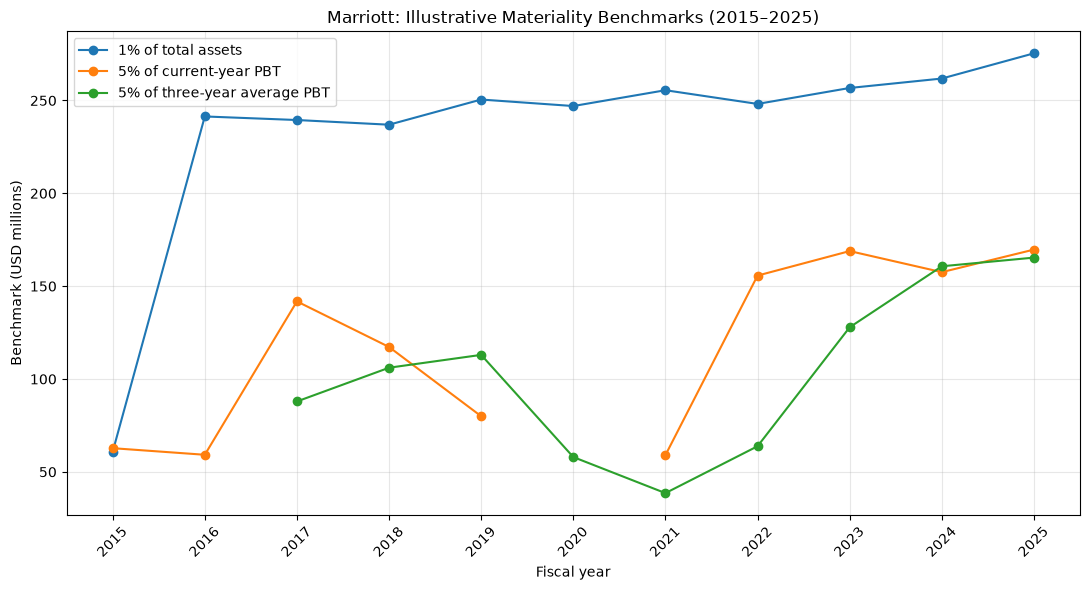

In [278]:
import matplotlib.pyplot as plt

plot_df = comparison_df.sort_values("year").copy()

# Convert USD to USD millions for readability
plot_df["assets_1pct_m"] = plot_df["assets_1pct"] / 1_000_000
plot_df["pbt_current_5pct_m"] = (
    plot_df["pbt_current_5pct"] / 1_000_000
)
plot_df["pbt_3yr_avg_5pct_m"] = (
    plot_df["pbt_3yr_avg_5pct"] / 1_000_000
)

plt.figure(figsize=(11, 6))

plt.plot(
    plot_df["year"],
    plot_df["assets_1pct_m"],
    marker="o",
    label="1% of total assets",
)

plt.plot(
    plot_df["year"],
    plot_df["pbt_current_5pct_m"],
    marker="o",
    label="5% of current-year PBT",
)

plt.plot(
    plot_df["year"],
    plot_df["pbt_3yr_avg_5pct_m"],
    marker="o",
    label="5% of three-year average PBT",
)

plt.title("Marriott: Illustrative Materiality Benchmarks (2015–2025)")
plt.xlabel("Fiscal year")
plt.ylabel("Benchmark (USD millions)")
plt.xticks(plot_df["year"], rotation=45)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

### Interpretation and Data Limitations

The chart compares three illustrative materiality benchmarks: 1% of total assets, 5% of current-year profit before tax (PBT), and 5% of the rolling three-year average PBT.

Missing values are retained as blank rather than estimated or inferred. The rolling three-year PBT benchmark is unavailable for 2015 and 2016 because the required historical data is insufficient for the calculation. For 2020, the current-year PBT benchmark is unavailable, while the rolling three-year average remains available.

The benchmarks are intended to support preliminary analytical assessment. They do not establish final audit materiality, which depends on professional judgement, the needs of financial-statement users and the circumstances of the engagement.

### Preliminary Interpretation of Materiality Benchmarks

The three benchmarks produce different materiality estimates because they reflect different aspects of the company's financial position and performance.

The asset-based benchmark (1% of total assets) provides a relatively stable reference point over time. By contrast, the profit-based benchmarks (5% of current-year PBT and 5% of the rolling three-year average PBT) are more sensitive to fluctuations in profitability.

This difference is particularly relevant around the COVID-19 period, when Marriott's profitability was affected substantially. A sharp reduction in PBT can produce a much lower profit-based benchmark than the asset-based benchmark. The rolling three-year average helps moderate year-to-year fluctuations, although it can still be affected by exceptional periods.

The comparison illustrates why benchmark selection requires professional judgement and consideration of the company's circumstances and the needs of financial-statement users. None of these illustrative percentages should be treated as an automatically appropriate or final audit materiality threshold.

These results are preliminary and intended to inform audit planning. The final benchmark and materiality level would need to be justified using the applicable auditing requirements and engagement-specific circumstances.

In [652]:
comparison_df[
    ["year", "pbt_current_5pct", "pbt_3yr_avg_5pct"]
].to_string(index=False)

' year  pbt_current_5pct  pbt_3yr_avg_5pct\n 2015        62750000.0               NaN\n 2016        59200000.0               NaN\n 2017       141800000.0      8.791667e+07\n 2018       117250000.0      1.060833e+08\n 2019        79950000.0      1.130000e+08\n 2020               NaN      5.796667e+07\n 2021        59000000.0      3.855000e+07\n 2022       155700000.0      6.380000e+07\n 2023       168900000.0      1.278667e+08\n 2024       157550000.0      1.607167e+08\n 2025       169700000.0      1.653833e+08'

In [653]:
print(comparison_df.columns.tolist())

['year', 'assets_1pct', 'pbt_current_5pct', 'pbt_3yr_avg_5pct']


In [654]:
comparison_df = comparison_df.merge(
    materiality_df[["year", "pbt_3yr_avg_5pct"]],
    on="year",
    how="left",
    suffixes=("", "_verified"),
)

comparison_df["pbt_3yr_avg_5pct"] = comparison_df[
    "pbt_3yr_avg_5pct_verified"
]

comparison_df = comparison_df.drop(
    columns="pbt_3yr_avg_5pct_verified"
)

display(comparison_df.round(0))

,year,assets_1pct,pbt_current_5pct,pbt_3yr_avg_5pct
0,2015,60820000.0,62750000.0,NaN
1,2016,241400000.0,59200000.0,NaN
2,2017,239480000.0,141800000.0,87916667.0
3,2018,236960000.0,117250000.0,106083333.0
4,2019,250510000.0,79950000.0,113000000.0
5,2020,247010000.0,NaN,57966667.0
6,2021,255530000.0,59000000.0,38550000.0
7,2022,248150000.0,155700000.0,63800000.0
8,2023,256740000.0,168900000.0,127866667.0
9,2024,261820000.0,157550000.0,160716667.0


In [655]:
print(comparison_df.columns.tolist())

['year', 'assets_1pct', 'pbt_current_5pct', 'pbt_3yr_avg_5pct']


In [656]:
display(
    comparison_df
    .sort_values("year")
    .round(0)
    .reset_index(drop=True)
)

,year,assets_1pct,pbt_current_5pct,pbt_3yr_avg_5pct
0,2015,60820000.0,62750000.0,NaN
1,2016,241400000.0,59200000.0,NaN
2,2017,239480000.0,141800000.0,87916667.0
3,2018,236960000.0,117250000.0,106083333.0
4,2019,250510000.0,79950000.0,113000000.0
5,2020,247010000.0,NaN,57966667.0
6,2021,255530000.0,59000000.0,38550000.0
7,2022,248150000.0,155700000.0,63800000.0
8,2023,256740000.0,168900000.0,127866667.0
9,2024,261820000.0,157550000.0,160716667.0


In [657]:
print(comparison_df.head(3).to_string(index=False))
print("\nData types:")
print(comparison_df.dtypes)

 year  assets_1pct  pbt_current_5pct  pbt_3yr_avg_5pct
 2015   60820000.0        62750000.0               NaN
 2016  241400000.0        59200000.0               NaN
 2017  239480000.0       141800000.0      8.791667e+07

Data types:
year                  int64
assets_1pct         float64
pbt_current_5pct    float64
pbt_3yr_avg_5pct    float64
dtype: object


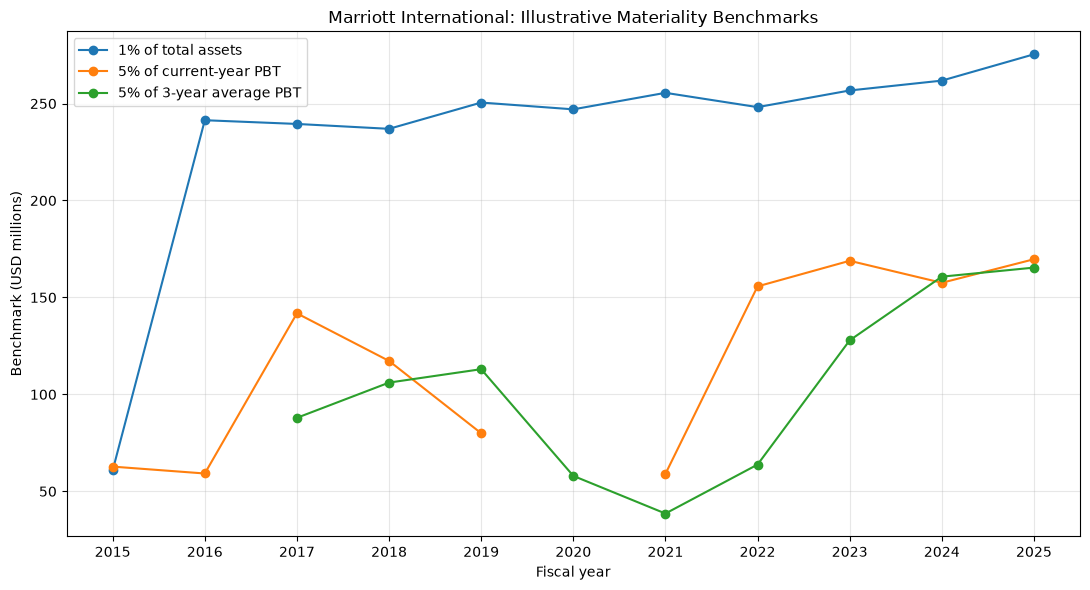

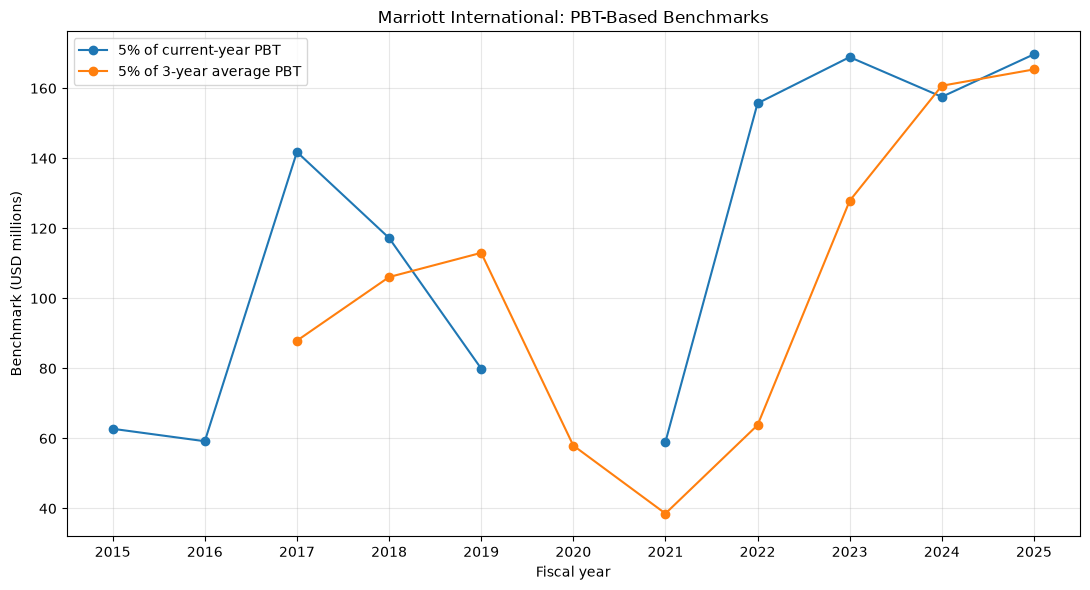

In [658]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

# Convert USD to millions for easier reading
plot_df = comparison_df.sort_values("year").copy()

for col in ["assets_1pct", "pbt_current_5pct", "pbt_3yr_avg_5pct"]:
    plot_df[f"{col}_m"] = plot_df[col] / 1_000_000

# Chart 1: all three benchmarks
fig, ax = plt.subplots(figsize=(11, 6))

ax.plot(
    plot_df["year"], plot_df["assets_1pct_m"],
    marker="o", label="1% of total assets"
)
ax.plot(
    plot_df["year"], plot_df["pbt_current_5pct_m"],
    marker="o", label="5% of current-year PBT"
)
ax.plot(
    plot_df["year"], plot_df["pbt_3yr_avg_5pct_m"],
    marker="o", label="5% of 3-year average PBT"
)

ax.set_title("Marriott International: Illustrative Materiality Benchmarks")
ax.set_xlabel("Fiscal year")
ax.set_ylabel("Benchmark (USD millions)")
ax.set_xticks(plot_df["year"])
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

# Chart 2: compare the two PBT-based benchmarks
fig, ax = plt.subplots(figsize=(11, 6))

ax.plot(
    plot_df["year"], plot_df["pbt_current_5pct_m"],
    marker="o", label="5% of current-year PBT"
)
ax.plot(
    plot_df["year"], plot_df["pbt_3yr_avg_5pct_m"],
    marker="o", label="5% of 3-year average PBT"
)

ax.set_title("Marriott International: PBT-Based Benchmarks")
ax.set_xlabel("Fiscal year")
ax.set_ylabel("Benchmark (USD millions)")
ax.set_xticks(plot_df["year"])
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

In [659]:
benchmark_analysis = comparison_df.copy()

benchmark_analysis["assets_to_current_pbt_ratio"] = (
    benchmark_analysis["assets_1pct"]
    / benchmark_analysis["pbt_current_5pct"]
)

benchmark_analysis["assets_to_avg_pbt_ratio"] = (
    benchmark_analysis["assets_1pct"]
    / benchmark_analysis["pbt_3yr_avg_5pct"]
)

display(
    benchmark_analysis[
        [
            "year",
            "assets_to_current_pbt_ratio",
            "assets_to_avg_pbt_ratio",
        ]
    ].round(2).reset_index(drop=True)
)

,year,assets_to_current_pbt_ratio,assets_to_avg_pbt_ratio
0,2015,0.97,NaN
1,2016,4.08,NaN
2,2017,1.69,2.72
3,2018,2.02,2.23
4,2019,3.13,2.22
5,2020,NaN,4.26
6,2021,4.33,6.63
7,2022,1.59,3.89
8,2023,1.52,2.01
9,2024,1.66,1.63


In [660]:
print(
    "Highest assets/current-PBT ratio:",
    benchmark_analysis.loc[
        benchmark_analysis["assets_to_current_pbt_ratio"].idxmax(),
        ["year", "assets_to_current_pbt_ratio"]
    ].to_dict()
)

print(
    "\nHighest assets/3-year-average-PBT ratio:",
    benchmark_analysis.loc[
        benchmark_analysis["assets_to_avg_pbt_ratio"].idxmax(),
        ["year", "assets_to_avg_pbt_ratio"]
    ].to_dict()
)

Highest assets/current-PBT ratio: {'year': 2021.0, 'assets_to_current_pbt_ratio': 4.331016949152542}

Highest assets/3-year-average-PBT ratio: {'year': 2021.0, 'assets_to_avg_pbt_ratio': 6.628534370946823}


In [661]:
materiality_df.loc[
    materiality_df["year"].between(2019, 2021),
    ["year", "profit_before_tax", "pbt_3yr_avg", "pbt_3yr_avg_5pct"]
].copy().assign(
    profit_before_tax_m=lambda df: df["profit_before_tax"] / 1_000_000,
    pbt_3yr_avg_m=lambda df: df["pbt_3yr_avg"] / 1_000_000,
    pbt_3yr_avg_5pct_m=lambda df: df["pbt_3yr_avg_5pct"] / 1_000_000,
)[
    ["year", "profit_before_tax_m", "pbt_3yr_avg_m", "pbt_3yr_avg_5pct_m"]
].round(2).reset_index(drop=True)

,year,profit_before_tax_m,pbt_3yr_avg_m,pbt_3yr_avg_5pct_m
0,2019,1599.0,2260.00,113.00
1,2020,-466.0,1159.33,57.97
2,2021,1180.0,771.00,38.55


In [662]:
benchmark_2019 = materiality_df.loc[
    materiality_df["year"] == 2019, "pbt_3yr_avg_5pct"
].iloc[0]

benchmark_2021 = materiality_df.loc[
    materiality_df["year"] == 2021, "pbt_3yr_avg_5pct"
].iloc[0]

decline_pct = (
    (benchmark_2021 - benchmark_2019) / benchmark_2019
) * 100

print(f"2019 benchmark: ${benchmark_2019 / 1_000_000:.2f} million")
print(f"2021 benchmark: ${benchmark_2021 / 1_000_000:.2f} million")
print(f"Percentage change: {decline_pct:.2f}%")

2019 benchmark: $113.00 million
2021 benchmark: $38.55 million
Percentage change: -65.88%


In [663]:
debt_tags = [
    name
    for name in data["facts"]["us-gaap"]
    if "Debt" in name
    or "Borrowings" in name
]

print(f"Number of debt-related tags: {len(debt_tags)}")

for tag in debt_tags:
    print(tag)

Number of debt-related tags: 25
DebtAndCapitalLeaseObligations
DebtInstrumentInterestRateStatedPercentage
DebtInstrumentUnamortizedDiscount
EarlyRepaymentOfSeniorDebt
ExtinguishmentOfDebtAmount
GainsLossesOnExtinguishmentOfDebt
HeldToMaturitySecuritiesDebtMaturitiesSingleMaturityDateAmortizedCostBasis
LongTermDebt
LongTermDebtAndCapitalLeaseObligations
LongTermDebtAndCapitalLeaseObligationsCurrent
LongTermDebtCurrent
LongTermDebtMaturitiesRepaymentsOfPrincipalAfterYearFive
LongTermDebtMaturitiesRepaymentsOfPrincipalInNextTwelveMonths
LongTermDebtMaturitiesRepaymentsOfPrincipalInYearFive
LongTermDebtMaturitiesRepaymentsOfPrincipalInYearFour
LongTermDebtMaturitiesRepaymentsOfPrincipalInYearThree
LongTermDebtMaturitiesRepaymentsOfPrincipalInYearTwo
LongTermDebtNoncurrent
MaturitiesOfSeniorDebt
OtherLongTermDebt
PaymentsOfDebtExtinguishmentCosts
ProceedsFromIssuanceOfLongTermDebt
ProceedsFromRepaymentsOfShortTermDebt
RepaymentsOfLongTermDebt
RepaymentsOfOtherLongTermDebt


In [664]:
debt_concepts = [
    "LongTermDebt",
    "LongTermDebtCurrent",
    "LongTermDebtNoncurrent",
    "LongTermDebtAndCapitalLeaseObligations",
    "ProceedsFromIssuanceOfLongTermDebt",
    "RepaymentsOfLongTermDebt",
]

for tag in debt_concepts:
    concept = data["facts"]["us-gaap"].get(tag)

    print(f"\n{'=' * 65}")
    print(f"TAG: {tag}")

    if concept is None:
        print("Tag not found")
        continue

    print("Label:", concept.get("label"))
    print("Description:", concept.get("description"))
    print("Units:", list(concept.get("units", {}).keys()))


TAG: LongTermDebt
Label: Long-term Debt
Description: Amount, after unamortized (discount) premium and debt issuance costs, of long-term debt. Includes, but not limited to, notes payable, bonds payable, debentures, mortgage loans and commercial paper. Excludes capital lease obligations.
Units: ['USD']

TAG: LongTermDebtCurrent
Label: Long-term Debt, Current Maturities
Description: Amount, after unamortized (discount) premium and debt issuance costs, of long-term debt, classified as current. Includes, but not limited to, notes payable, bonds payable, debentures, mortgage loans and commercial paper. Excludes capital lease obligations.
Units: ['USD']

TAG: LongTermDebtNoncurrent
Label: Long-term Debt, Excluding Current Maturities
Description: Amount after unamortized (discount) premium and debt issuance costs of long-term debt classified as noncurrent and excluding amounts to be repaid within one year or the normal operating cycle, if longer. Includes, but not limited to, notes payable, b

In [665]:
debt_facts = data["facts"]["us-gaap"]["LongTermDebt"]

debt_df = pd.DataFrame(debt_facts["units"]["USD"])

display(
    debt_df[
        ["end", "val", "fy", "fp", "form", "filed", "accn"]
    ]
    .sort_values(["end", "filed"])
    .tail(25)
    .reset_index(drop=True)
)

,end,val,fy,fp,form,filed,accn
0,2022-12-31,92000000,2023,FY,10-K,2024-02-13,0001628280-24-004372
1,2023-03-31,56000000,2023,Q1,10-Q,2023-05-02,0001628280-23-014793
2,2023-06-30,56000000,2023,Q2,10-Q,2023-08-01,0001628280-23-026380
3,2023-09-30,56000000,2023,Q3,10-Q,2023-11-02,0001628280-23-036256
4,2023-12-31,56000000,2023,FY,10-K,2024-02-13,0001628280-24-004372
5,2023-12-31,56000000,2024,Q1,10-Q,2024-05-01,0001628280-24-019494
6,2023-12-31,56000000,2024,Q2,10-Q,2024-07-31,0001628280-24-033679
7,2023-12-31,56000000,2024,Q3,10-Q,2024-11-04,0001628280-24-044884
8,2023-12-31,56000000,2024,FY,10-K,2025-02-11,0001628280-25-004818
9,2024-03-31,56000000,2024,Q1,10-Q,2024-05-01,0001628280-24-019494


In [666]:
debt_tags_to_compare = [
    "LongTermDebt",
    "LongTermDebtCurrent",
    "LongTermDebtNoncurrent",
    "LongTermDebtAndCapitalLeaseObligations",
]

for tag in debt_tags_to_compare:
    facts = data["facts"]["us-gaap"].get(tag)

    print(f"\n{'=' * 65}")
    print(tag)

    if facts is None:
        print("Tag not found")
        continue

    df = pd.DataFrame(facts["units"]["USD"])

    annual = df[
        (df["form"] == "10-K")
        & (df["fp"] == "FY")
        & (df["end"].str.endswith("-12-31"))
    ].copy()

    display(
        annual[["end", "val", "fy", "filed"]]
        .sort_values(["end", "filed"])
        .drop_duplicates(subset=["end"], keep="last")
        .tail(8)
        .reset_index(drop=True)
    )


LongTermDebt


,end,val,fy,filed
0,2010-12-31,2829000000,2010,2011-02-18
1,2019-12-31,247000000,2020,2021-02-18
2,2020-12-31,143000000,2021,2022-02-15
3,2021-12-31,135000000,2022,2023-02-14
4,2022-12-31,92000000,2023,2024-02-13
5,2023-12-31,56000000,2024,2025-02-11
6,2024-12-31,55000000,2025,2026-02-10
7,2025-12-31,23000000,2025,2026-02-10



LongTermDebtCurrent


,end,val,fy,filed
0,2010-12-31,138000000,2011,2012-02-16



LongTermDebtNoncurrent


,end,val,fy,filed
0,2010-12-31,2691000000,2011,2012-02-16



LongTermDebtAndCapitalLeaseObligations


,end,val,fy,filed
0,2018-12-31,8514000000,2019,2020-02-27
1,2019-12-31,9963000000,2020,2021-02-18
2,2020-12-31,9203000000,2021,2022-02-15
3,2021-12-31,9333000000,2022,2023-02-14
4,2022-12-31,9380000000,2023,2024-02-13
5,2023-12-31,11320000000,2024,2025-02-11
6,2024-12-31,13138000000,2025,2026-02-10
7,2025-12-31,14995000000,2025,2026-02-10


In [667]:
debt_tag = "LongTermDebtAndCapitalLeaseObligations"

debt_df = pd.DataFrame(
    data["facts"]["us-gaap"][debt_tag]["units"]["USD"]
)

debt_annual = (
    debt_df[
        (debt_df["form"] == "10-K")
        & (debt_df["fp"] == "FY")
        & (debt_df["end"].str.endswith("-12-31"))
    ]
    .sort_values(["end", "filed"])
    .drop_duplicates(subset=["end"], keep="last")
    .copy()
)

debt_annual["year"] = pd.to_datetime(
    debt_annual["end"]
).dt.year

debt_annual = debt_annual[
    ["year", "end", "val", "filed", "accn"]
].rename(columns={"val": "long_term_debt_and_leases"})

debt_annual = debt_annual.sort_values("year").reset_index(drop=True)

debt_annual["debt_change"] = (
    debt_annual["long_term_debt_and_leases"].diff()
)

debt_annual["debt_change_pct"] = (
    debt_annual["long_term_debt_and_leases"].pct_change() * 100
)

display(
    debt_annual[
        [
            "year",
            "long_term_debt_and_leases",
            "debt_change",
            "debt_change_pct",
        ]
    ].round(2)
)

,year,long_term_debt_and_leases,debt_change,debt_change_pct
0,2013,3147000000,NaN,NaN
1,2014,3447000000,3.000000e+08,9.53
2,2015,3807000000,3.600000e+08,10.44
3,2016,8197000000,4.390000e+09,115.31
4,2017,7840000000,-3.570000e+08,-4.36
5,2018,8514000000,6.740000e+08,8.60
6,2019,9963000000,1.449000e+09,17.02
7,2020,9203000000,-7.600000e+08,-7.63
8,2021,9333000000,1.300000e+08,1.41
9,2022,9380000000,4.700000e+07,0.50


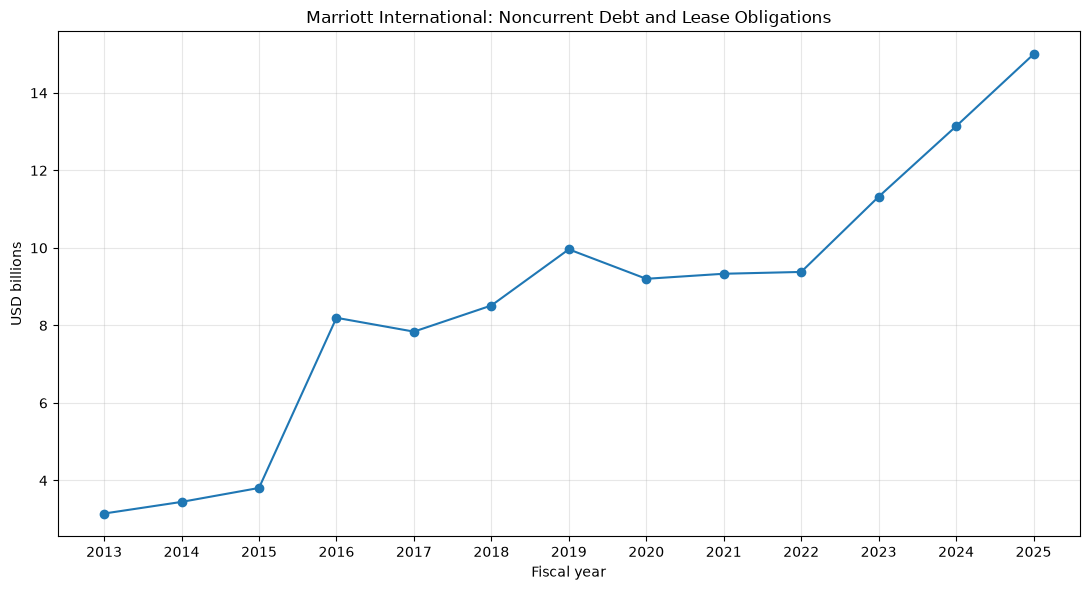

In [668]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

plot_debt = debt_annual.copy()
plot_debt["debt_billions"] = (
    plot_debt["long_term_debt_and_leases"] / 1_000_000_000
)

fig, ax = plt.subplots(figsize=(11, 6))

ax.plot(
    plot_debt["year"],
    plot_debt["debt_billions"],
    marker="o",
)

ax.set_title(
    "Marriott International: Noncurrent Debt and Lease Obligations"
)
ax.set_xlabel("Fiscal year")
ax.set_ylabel("USD billions")
ax.set_xticks(plot_debt["year"])
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [669]:
for name, obj in list(globals().items()):
    if isinstance(obj, pd.DataFrame):
        cols = set(obj.columns)

        if {"year", "revenue", "operating_cash_flow"}.issubset(cols):
            print(f"\nDataFrame: {name}")
            print("Rows:", len(obj))
            print(obj.columns.tolist())


DataFrame: _21
Rows: 11
['year', 'revenue', 'receivables', 'revenue_growth', 'receivables_growth', 'divergence', 'abs_divergence', 'period', 'operating_cash_flow', 'operating_cash_flow_growth', 'cfo_divergence', 'abs_cfo_divergence']

DataFrame: df_check
Rows: 11
['year', 'revenue', 'receivables', 'operating_cash_flow']

DataFrame: df_normal
Rows: 9
['year', 'revenue', 'receivables', 'revenue_growth', 'receivables_growth', 'divergence', 'abs_divergence', 'period', 'operating_cash_flow', 'operating_cash_flow_growth', 'cfo_divergence', 'abs_cfo_divergence', 'payables', 'payables_growth', 'receivables_change', 'payables_change']

DataFrame: _79
Rows: 11
['year', 'working_capital_cash_effect', 'revenue', 'operating_cash_flow', 'wc_effect_pct_revenue', 'wc_effect_pct_cfo']

DataFrame: _91
Rows: 11
['year', 'revenue', 'operating_cash_flow', 'total_assets', 'profit_before_tax']

DataFrame: _102
Rows: 3
['year', 'revenue', 'revenue_growth', 'receivables', 'receivables_growth', 'receivables_re

In [670]:
debt_comparison = debt_annual.merge(
    df_normal[
        ["year", "revenue", "operating_cash_flow"]
    ],
    on="year",
    how="inner",
)

debt_comparison["debt_leases_to_revenue_pct"] = (
    debt_comparison["long_term_debt_and_leases"]
    / debt_comparison["revenue"]
    * 100
)

debt_comparison["debt_leases_to_cfo"] = (
    debt_comparison["long_term_debt_and_leases"]
    / debt_comparison["operating_cash_flow"]
)

display(
    debt_comparison[
        [
            "year",
            "long_term_debt_and_leases",
            "revenue",
            "operating_cash_flow",
            "debt_leases_to_revenue_pct",
            "debt_leases_to_cfo",
        ]
    ].round(2).reset_index(drop=True)
)

,year,long_term_debt_and_leases,revenue,operating_cash_flow,debt_leases_to_revenue_pct,debt_leases_to_cfo
0,2015,3807000000,14486000000,1430000000,26.28,2.66
1,2016,8197000000,17072000000,1582000000,48.01,5.18
2,2017,7840000000,22894000000,2436000000,34.24,3.22
3,2018,8514000000,20758000000,2357000000,41.02,3.61
4,2019,9963000000,20972000000,1685000000,47.51,5.91
5,2022,9380000000,20773000000,2363000000,45.15,3.97
6,2023,11320000000,23713000000,3170000000,47.74,3.57
7,2024,13138000000,25100000000,2749000000,52.34,4.78
8,2025,14995000000,26186000000,3212000000,57.26,4.67


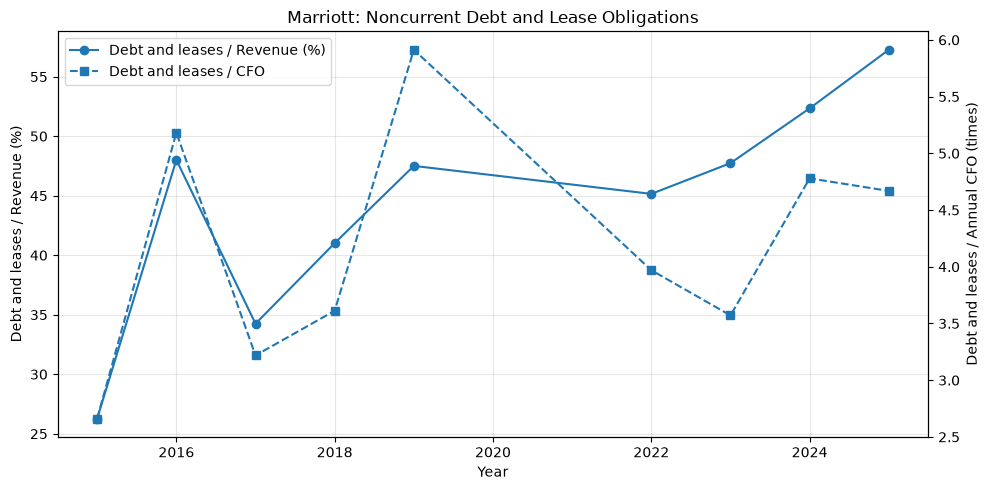

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    debt_comparison["year"],
    debt_comparison["debt_leases_to_revenue_pct"],
    marker="o",
    label="Debt and leases / Revenue (%)"
)

ax.set_xlabel("Year")
ax.set_ylabel("Debt and leases / Revenue (%)")
ax.set_title("Marriott: Debt and Lease Obligations Relative to Revenue and Operating Cash Flow (2015–2025)")
ax.grid(True, alpha=0.3)

ax2 = ax.twinx()
ax2.plot(
    debt_comparison["year"],
    debt_comparison["debt_leases_to_cfo"],
    marker="s",
    linestyle="--",
    label="Debt and leases / CFO"
)
ax2.set_ylabel("Debt and leases / Annual CFO (times)")

lines1, labels1 = ax.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax.legend(lines1 + lines2, labels1 + labels2, loc="upper left")

plt.tight_layout()
plt.show()

In [672]:
debt_comparison["debt_leases_growth_pct"] = (
    debt_comparison["long_term_debt_and_leases"]
    .pct_change()
    * 100
)

display(
    debt_comparison[
        ["year", "long_term_debt_and_leases", "debt_leases_growth_pct"]
    ].round(2).to_string(index=False)
)

' year  long_term_debt_and_leases  debt_leases_growth_pct\n 2015                 3807000000                     NaN\n 2016                 8197000000                  115.31\n 2017                 7840000000                   -4.36\n 2018                 8514000000                    8.60\n 2019                 9963000000                   17.02\n 2022                 9380000000                   -5.85\n 2023                11320000000                   20.68\n 2024                13138000000                   16.06\n 2025                14995000000                   14.13'

In [673]:
debt_comparison["revenue_growth_pct"] = (
    debt_comparison["revenue"].pct_change() * 100
)

debt_comparison["debt_minus_revenue_growth_pp"] = (
    debt_comparison["debt_leases_growth_pct"]
    - debt_comparison["revenue_growth_pct"]
)

display(
    debt_comparison[
        [
            "year",
            "debt_leases_growth_pct",
            "revenue_growth_pct",
            "debt_minus_revenue_growth_pp",
        ]
    ].round(2)
)

,year,debt_leases_growth_pct,revenue_growth_pct,debt_minus_revenue_growth_pp
0,2015,NaN,NaN,NaN
1,2016,115.31,17.85,97.46
2,2017,-4.36,34.10,-38.46
3,2018,8.60,-9.33,17.93
4,2019,17.02,1.03,15.99
5,2022,-5.85,-0.95,-4.90
6,2023,20.68,14.15,6.53
7,2024,16.06,5.85,10.21
8,2025,14.13,4.33,9.81


In [674]:
concept = "TreasuryStockCommonValue"

print("Concept:", concept)
print("Label:", data["facts"]["us-gaap"][concept].get("label"))
print("Description:", data["facts"]["us-gaap"][concept].get("description"))

Concept: TreasuryStockCommonValue
Label: Treasury Stock, Common, Value
Description: Amount allocated to previously issued common shares repurchased by the issuing entity and held in treasury.


In [675]:
concepts = [
    "StockholdersEquity",
    "TreasuryStockValue",
    "TreasuryStockValueAcquiredCostMethod",
    "TreasuryStockCommonValue",
]

for concept in concepts:
    details = data["facts"]["us-gaap"][concept]

    print(f"\nConcept: {concept}")
    print("Label:", details.get("label"))
    print("Description:", details.get("description"))
    print("Units:", list(details.get("units", {}).keys()))


Concept: StockholdersEquity
Label: Stockholders' Equity Attributable to Parent
Description: Total of all stockholders' equity (deficit) items, net of receivables from officers, directors, owners, and affiliates of the entity which are attributable to the parent. The amount of the economic entity's stockholders' equity attributable to the parent excludes the amount of stockholders' equity which is allocable to that ownership interest in subsidiary equity which is not attributable to the parent (noncontrolling interest, minority interest). This excludes temporary equity and is sometimes called permanent equity.
Units: ['USD']

Concept: TreasuryStockValue
Label: Treasury Stock, Value
Description: The amount allocated to treasury stock. Treasury stock is common and preferred shares of an entity that were issued, repurchased by the entity, and are held in its treasury.
Units: ['USD']

Concept: TreasuryStockValueAcquiredCostMethod
Label: Treasury Stock, Value, Acquired, Cost Method
Descript

In [676]:
for concept in [
    "TreasuryStockValue",
    "TreasuryStockValueAcquiredCostMethod",
    "TreasuryStockCommonValue",
]:
    print(f"\n--- {concept} ---")

    facts = data["facts"]["us-gaap"][concept]["units"].get("USD", [])

    for fact in facts:
        if (
            fact.get("end") in [
                "2023-12-31",
                "2024-12-31",
                "2025-12-31",
            ]
            and fact.get("form") == "10-K"
        ):
            print({
                "end": fact.get("end"),
                "value": fact.get("val"),
                "filed": fact.get("filed"),
                "accn": fact.get("accn"),
            })


--- TreasuryStockValue ---

--- TreasuryStockValueAcquiredCostMethod ---
{'end': '2023-12-31', 'value': 3954000000, 'filed': '2024-02-13', 'accn': '0001628280-24-004372'}
{'end': '2023-12-31', 'value': 3954000000, 'filed': '2025-02-11', 'accn': '0001628280-25-004818'}
{'end': '2023-12-31', 'value': 3954000000, 'filed': '2026-02-10', 'accn': '0001048286-26-000007'}
{'end': '2024-12-31', 'value': 3761000000, 'filed': '2025-02-11', 'accn': '0001628280-25-004818'}
{'end': '2024-12-31', 'value': 3761000000, 'filed': '2026-02-10', 'accn': '0001048286-26-000007'}
{'end': '2025-12-31', 'value': 3294000000, 'filed': '2026-02-10', 'accn': '0001048286-26-000007'}

--- TreasuryStockCommonValue ---
{'end': '2023-12-31', 'value': 20929000000, 'filed': '2024-02-13', 'accn': '0001628280-24-004372'}
{'end': '2023-12-31', 'value': 20929000000, 'filed': '2025-02-11', 'accn': '0001628280-25-004818'}
{'end': '2024-12-31', 'value': 24644000000, 'filed': '2025-02-11', 'accn': '0001628280-25-004818'}
{'end':

In [677]:
for concept in ["StockholdersEquity", "TreasuryStockValueAcquiredCostMethod"]:
    print(f"\n--- {concept} ---")

    facts = data["facts"]["us-gaap"][concept]["units"].get("USD", [])

    for fact in facts:
        if (
            fact.get("end") in [
                "2023-12-31",
                "2024-12-31",
                "2025-12-31",
            ]
            and fact.get("form") == "10-K"
        ):
            print({
                "end": fact.get("end"),
                "value": fact.get("val"),
                "filed": fact.get("filed"),
                "accn": fact.get("accn"),
                "fp": fact.get("fp"),
                "fy": fact.get("fy"),
            })


--- StockholdersEquity ---
{'end': '2023-12-31', 'value': -682000000, 'filed': '2024-02-13', 'accn': '0001628280-24-004372', 'fp': 'FY', 'fy': 2023}
{'end': '2023-12-31', 'value': -682000000, 'filed': '2025-02-11', 'accn': '0001628280-25-004818', 'fp': 'FY', 'fy': 2024}
{'end': '2023-12-31', 'value': -682000000, 'filed': '2026-02-10', 'accn': '0001048286-26-000007', 'fp': 'FY', 'fy': 2025}
{'end': '2024-12-31', 'value': -2992000000, 'filed': '2025-02-11', 'accn': '0001628280-25-004818', 'fp': 'FY', 'fy': 2024}
{'end': '2024-12-31', 'value': -2992000000, 'filed': '2026-02-10', 'accn': '0001048286-26-000007', 'fp': 'FY', 'fy': 2025}
{'end': '2025-12-31', 'value': -3771000000, 'filed': '2026-02-10', 'accn': '0001048286-26-000007', 'fp': 'FY', 'fy': 2025}

--- TreasuryStockValueAcquiredCostMethod ---
{'end': '2023-12-31', 'value': 3954000000, 'filed': '2024-02-13', 'accn': '0001628280-24-004372', 'fp': 'FY', 'fy': 2023}
{'end': '2023-12-31', 'value': 3954000000, 'filed': '2025-02-11', 'ac

In [678]:
for concept in ["StockholdersEquity", "TreasuryStockCommonValue"]:
    item = data["facts"]["us-gaap"][concept]

    print(f"\n{concept}")
    print("Label:", item.get("label"))

    for fact in item.get("units", {}).get("USD", []):
        if (
            fact.get("end") == "2023-12-31"
            and fact.get("form") == "10-K"
        ):
            print({
                "value": fact.get("val"),
                "filed": fact.get("filed"),
                "accn": fact.get("accn"),
                "frame": fact.get("frame"),
            })


StockholdersEquity
Label: Stockholders' Equity Attributable to Parent
{'value': -682000000, 'filed': '2024-02-13', 'accn': '0001628280-24-004372', 'frame': None}
{'value': -682000000, 'filed': '2025-02-11', 'accn': '0001628280-25-004818', 'frame': None}
{'value': -682000000, 'filed': '2026-02-10', 'accn': '0001048286-26-000007', 'frame': 'CY2023Q4I'}

TreasuryStockCommonValue
Label: Treasury Stock, Common, Value
{'value': 20929000000, 'filed': '2024-02-13', 'accn': '0001628280-24-004372', 'frame': None}
{'value': 20929000000, 'filed': '2025-02-11', 'accn': '0001628280-25-004818', 'frame': 'CY2023Q4I'}


In [679]:
concept = "StockholdersEquity"
facts = data["facts"]["us-gaap"][concept]["units"]["USD"]

for fact in facts:
    if (
        "2015-01-01" <= fact.get("end", "") <= "2025-12-31"
        and fact.get("end", "").endswith("-12-31")
        and fact.get("form") == "10-K"
    ):
        print({
            "end": fact.get("end"),
            "value": fact.get("val"),
            "filed": fact.get("filed"),
            "accn": fact.get("accn"),
            "fy": fact.get("fy"),
        })

{'end': '2015-12-31', 'value': -3590000000, 'filed': '2016-02-18', 'accn': '0001628280-16-011346', 'fy': 2015}
{'end': '2015-12-31', 'value': -3590000000, 'filed': '2017-02-21', 'accn': '0001628280-17-001506', 'fy': 2016}
{'end': '2015-12-31', 'value': -3590000000, 'filed': '2018-02-15', 'accn': '0001628280-18-001756', 'fy': 2017}
{'end': '2015-12-31', 'value': -3590000000, 'filed': '2019-03-01', 'accn': '0001628280-19-002337', 'fy': 2018}
{'end': '2016-12-31', 'value': 5357000000, 'filed': '2017-02-21', 'accn': '0001628280-17-001506', 'fy': 2016}
{'end': '2016-12-31', 'value': 5357000000, 'filed': '2018-02-15', 'accn': '0001628280-18-001756', 'fy': 2017}
{'end': '2016-12-31', 'value': 5121000000, 'filed': '2019-03-01', 'accn': '0001628280-19-002337', 'fy': 2018}
{'end': '2016-12-31', 'value': 5121000000, 'filed': '2020-02-27', 'accn': '0001628280-20-002376', 'fy': 2019}
{'end': '2017-12-31', 'value': 3731000000, 'filed': '2018-02-15', 'accn': '0001628280-18-001756', 'fy': 2017}
{'end'

In [680]:
import pandas as pd

concept = "StockholdersEquity"
facts = data["facts"]["us-gaap"][concept]["units"]["USD"]

equity_df = pd.DataFrame([
    {
        "end": fact.get("end"),
        "equity": fact.get("val"),
        "filed": fact.get("filed"),
        "accn": fact.get("accn"),
    }
    for fact in facts
    if (
        "2015-01-01" <= fact.get("end", "") <= "2025-12-31"
        and fact.get("end", "").endswith("-12-31")
        and fact.get("form") == "10-K"
    )
])

# Keep the latest filing for each year-end
equity_df = (
    equity_df
    .sort_values("filed")
    .drop_duplicates(subset="end", keep="last")
    .sort_values("end")
    .reset_index(drop=True)
)

equity_df["year"] = pd.to_datetime(equity_df["end"]).dt.year
equity_df["equity_usd_bn"] = equity_df["equity"] / 1e9

display(
    equity_df[["year", "equity_usd_bn", "filed"]].round(3)
)

,year,equity_usd_bn,filed
0,2015,-3.590,2019-03-01
1,2016,5.121,2020-02-27
2,2017,3.582,2021-02-18
3,2018,2.225,2022-02-15
4,2019,0.703,2023-02-14
5,2020,0.430,2024-02-13
6,2021,1.414,2025-02-11
7,2022,0.568,2026-02-10
8,2023,-0.682,2026-02-10
9,2024,-2.992,2026-02-10


In [681]:
concept = "TreasuryStockCommonValue"
facts = data["facts"]["us-gaap"][concept]["units"]["USD"]

treasury_df = pd.DataFrame([
    {
        "end": fact.get("end"),
        "treasury_stock_raw": fact.get("val"),
        "filed": fact.get("filed"),
        "accn": fact.get("accn"),
    }
    for fact in facts
    if (
        "2015-01-01" <= fact.get("end", "") <= "2025-12-31"
        and fact.get("end", "").endswith("-12-31")
        and fact.get("form") == "10-K"
    )
])

# Keep the latest filing for each year-end
treasury_df = (
    treasury_df
    .sort_values("filed")
    .drop_duplicates(subset="end", keep="last")
    .sort_values("end")
    .reset_index(drop=True)
)

treasury_df["year"] = pd.to_datetime(treasury_df["end"]).dt.year

# Present treasury stock as a deduction from equity
treasury_df["treasury_stock_usd_bn"] = (
    -treasury_df["treasury_stock_raw"] / 1e9
)

display(
    treasury_df[
        ["year", "treasury_stock_usd_bn", "filed"]
    ].round(3)
)

,year,treasury_stock_usd_bn,filed
0,2021,-14.446,2023-02-14
1,2022,-17.015,2024-02-13
2,2023,-20.929,2025-02-11
3,2024,-24.644,2026-02-10
4,2025,-27.900,2026-02-10


In [682]:
equity_treasury_df = equity_df[
    ["year", "equity_usd_bn"]
].merge(
    treasury_df[["year", "treasury_stock_usd_bn"]],
    on="year",
    how="inner"
)

equity_treasury_df["equity_change"] = (
    equity_treasury_df["equity_usd_bn"].diff()
)

equity_treasury_df["treasury_stock_change"] = (
    equity_treasury_df["treasury_stock_usd_bn"].diff()
)

display(equity_treasury_df.round(3))

,year,equity_usd_bn,treasury_stock_usd_bn,equity_change,treasury_stock_change
0,2021,1.414,-14.446,NaN,NaN
1,2022,0.568,-17.015,-0.846,-2.569
2,2023,-0.682,-20.929,-1.250,-3.914
3,2024,-2.992,-24.644,-2.310,-3.715
4,2025,-3.771,-27.900,-0.779,-3.256


In [683]:
concept = "TreasuryStockValueAcquiredCostMethod"
facts = data["facts"]["us-gaap"][concept]["units"]["USD"]

repurchases_df = pd.DataFrame([
    {
        "end": fact.get("end"),
        "repurchases_raw": fact.get("val"),
        "filed": fact.get("filed"),
        "accn": fact.get("accn"),
        "form": fact.get("form"),
        "fy": fact.get("fy"),
        "fp": fact.get("fp"),
        "start": fact.get("start"),
    }
    for fact in facts
    if (
        "2015-01-01" <= fact.get("end", "") <= "2025-12-31"
        and fact.get("end", "").endswith("-12-31")
        and fact.get("form") == "10-K"
    )
])

repurchases_df = (
    repurchases_df
    .sort_values("filed")
    .drop_duplicates(subset="end", keep="last")
    .sort_values("end")
    .reset_index(drop=True)
)

repurchases_df["year"] = pd.to_datetime(
    repurchases_df["end"]
).dt.year

repurchases_df["value_usd_bn"] = (
    repurchases_df["repurchases_raw"] / 1e9
)

display(
    repurchases_df[
        ["year", "start", "end", "value_usd_bn", "filed", "fy", "fp"]
    ].round(3)
)

,year,start,end,value_usd_bn,filed,fy,fp
0,2015,2015-01-01,2015-12-31,1.940,2018-02-15,2017,FY
1,2016,2016-01-01,2016-12-31,0.573,2019-03-01,2018,FY
2,2017,2017-01-01,2017-12-31,3.025,2020-02-27,2019,FY
3,2018,2018-01-01,2018-12-31,2.809,2021-02-18,2020,FY
4,2019,2019-01-01,2019-12-31,2.260,2022-02-15,2021,FY
5,2020,2020-01-01,2020-12-31,0.150,2023-02-14,2022,FY
6,2022,2022-01-01,2022-12-31,2.600,2025-02-11,2024,FY
7,2023,2023-01-01,2023-12-31,3.954,2026-02-10,2025,FY
8,2024,2024-01-01,2024-12-31,3.761,2026-02-10,2025,FY
9,2025,2025-01-01,2025-12-31,3.294,2026-02-10,2025,FY


In [684]:
repurchases_df = pd.DataFrame([
    {
        "start": fact.get("start"),
        "end": fact.get("end"),
        "value_usd_bn": fact.get("val") / 1e9,
        "filed": fact.get("filed"),
        "fy": fact.get("fy"),
        "fp": fact.get("fp"),
    }
    for fact in facts
    if (
        fact.get("form") == "10-K"
        and fact.get("start", "").endswith("-01-01")
        and fact.get("end", "").endswith("-12-31")
        and "2015-01-01" <= fact.get("start", "") <= "2025-01-01"
    )
])

repurchases_df = (
    repurchases_df
    .sort_values("filed")
    .drop_duplicates(subset="end", keep="last")
    .sort_values("end")
    .reset_index(drop=True)
)

repurchases_df["year"] = pd.to_datetime(
    repurchases_df["end"]
).dt.year

display(
    repurchases_df[
        ["year", "value_usd_bn", "filed"]
    ].round(3)
)

,year,value_usd_bn,filed
0,2015,1.940,2018-02-15
1,2016,0.573,2019-03-01
2,2017,3.025,2020-02-27
3,2018,2.809,2021-02-18
4,2019,2.260,2022-02-15
5,2020,0.150,2023-02-14
6,2022,2.600,2025-02-11
7,2023,3.954,2026-02-10
8,2024,3.761,2026-02-10
9,2025,3.294,2026-02-10


In [685]:
# Merge the annual repurchase measure with treasury-stock balances
repurchase_comparison_df = treasury_df[
    ["year", "treasury_stock_usd_bn"]
].merge(
    repurchases_df[["year", "value_usd_bn"]],
    on="year",
    how="left"
).sort_values("year").reset_index(drop=True)

# Annual change in the treasury-stock balance
repurchase_comparison_df["treasury_stock_change"] = (
    repurchase_comparison_df["treasury_stock_usd_bn"].diff()
)

# Compare the absolute increase in treasury stock with the annual measure
repurchase_comparison_df["balance_increase_abs"] = (
    -repurchase_comparison_df["treasury_stock_change"]
)

repurchase_comparison_df["difference_bn"] = (
    repurchase_comparison_df["balance_increase_abs"]
    - repurchase_comparison_df["value_usd_bn"]
)

display(repurchase_comparison_df.round(3))

,year,treasury_stock_usd_bn,value_usd_bn,treasury_stock_change,balance_increase_abs,difference_bn
0,2021,-14.446,NaN,NaN,NaN,NaN
1,2022,-17.015,2.600,-2.569,2.569,-0.031
2,2023,-20.929,3.954,-3.914,3.914,-0.040
3,2024,-24.644,3.761,-3.715,3.715,-0.046
4,2025,-27.900,3.294,-3.256,3.256,-0.038


In [686]:
period_df = repurchase_comparison_df[
    repurchase_comparison_df["year"].between(2022, 2025)
]

cumulative_repurchases = period_df["value_usd_bn"].sum()

equity_2021 = equity_df.loc[
    equity_df["year"] == 2021, "equity_usd_bn"
].iloc[0]

equity_2025 = equity_df.loc[
    equity_df["year"] == 2025, "equity_usd_bn"
].iloc[0]

equity_change_2021_2025 = equity_2025 - equity_2021

print(f"Cumulative repurchase measure, 2022–2025: ${cumulative_repurchases:.3f}bn")
print(f"Equity change, 2021–2025: ${equity_change_2021_2025:.3f}bn")
print(f"Treasury-stock balance change, 2021–2025: ${(
    equity_treasury_df.loc[equity_treasury_df['year'] == 2025, 'treasury_stock_usd_bn'].iloc[0]
    - equity_treasury_df.loc[equity_treasury_df['year'] == 2021, 'treasury_stock_usd_bn'].iloc[0]
):.3f}bn")

Cumulative repurchase measure, 2022–2025: $13.609bn
Equity change, 2021–2025: $-5.185bn
Treasury-stock balance change, 2021–2025: $-13.454bn


In [687]:
dividend_concepts = []

for namespace in ["us-gaap", "ffd"]:
    if namespace not in data["facts"]:
        continue

    for concept, details in data["facts"][namespace].items():
        label = details.get("label") or ""
        description = details.get("description") or ""

        if (
            "dividend" in concept.lower()
            or "dividend" in label.lower()
            or "dividend" in description.lower()
        ):
            dividend_concepts.append({
                "namespace": namespace,
                "concept": concept,
                "label": label,
                "description": description,
            })

dividend_concepts_df = pd.DataFrame(dividend_concepts)

display(dividend_concepts_df)

,namespace,concept,label,description
0,us-gaap,CommonStockDividendsPerShareCashPaid,"Common Stock, Dividends, Per Share, Cash Paid",Aggregate dividends paid during the period for...
1,us-gaap,CommonStockDividendsPerShareDeclared,"Common Stock, Dividends, Per Share, Declared",Aggregate dividends declared during the period...
2,us-gaap,DividendsCash,"Dividends, Cash",Amount of paid and unpaid cash dividends decla...
3,us-gaap,EquityMethodInvestments,Equity Method Investments,This item represents the carrying amount on th...
4,us-gaap,NetIncomeLossAvailableToCommonStockholdersDiluted,Net Income (Loss) Available to Common Stockhol...,"Amount, after deduction of tax, noncontrolling..."
5,us-gaap,PaymentsOfDividends,Payments of Dividends,Cash outflow in the form of capital distributi...
6,us-gaap,PaymentsOfDividendsCommonStock,"Payments of Ordinary Dividends, Common Stock",Amount of cash outflow in the form of ordinary...
7,us-gaap,DividendsCommonStock,"Dividends, Common Stock",Amount of paid and unpaid common stock dividen...


In [688]:
dividend_tags = [
    "PaymentsOfDividends",
    "PaymentsOfDividendsCommonStock",
]

for concept in dividend_tags:
    print(f"\n--- {concept} ---")

    details = data["facts"]["us-gaap"].get(concept)

    if details is None:
        print("Concept not found")
        continue

    print("Label:", details.get("label"))
    print("Description:", details.get("description"))

    units = details.get("units", {})

    for unit, facts in units.items():
        print("Unit:", unit)

        for fact in facts:
            if (
                fact.get("form") == "10-K"
                and fact.get("end", "").endswith("-12-31")
                and fact.get("end", "") >= "2023-01-01"
            ):
                print({
                    "start": fact.get("start"),
                    "end": fact.get("end"),
                    "value_usd_m": round(fact.get("val", 0) / 1e6, 2),
                    "filed": fact.get("filed"),
                    "fy": fact.get("fy"),
                    "fp": fact.get("fp"),
                })


--- PaymentsOfDividends ---
Label: Payments of Dividends
Description: Cash outflow in the form of capital distributions and dividends to common shareholders, preferred shareholders and noncontrolling interests.
Unit: USD

--- PaymentsOfDividendsCommonStock ---
Label: Payments of Ordinary Dividends, Common Stock
Description: Amount of cash outflow in the form of ordinary dividends to common shareholders of the parent entity.
Unit: USD
{'start': '2023-01-01', 'end': '2023-12-31', 'value_usd_m': 587.0, 'filed': '2024-02-13', 'fy': 2023, 'fp': 'FY'}
{'start': '2023-01-01', 'end': '2023-12-31', 'value_usd_m': 587.0, 'filed': '2025-02-11', 'fy': 2024, 'fp': 'FY'}
{'start': '2023-01-01', 'end': '2023-12-31', 'value_usd_m': 587.0, 'filed': '2026-02-10', 'fy': 2025, 'fp': 'FY'}
{'start': '2024-01-01', 'end': '2024-12-31', 'value_usd_m': 682.0, 'filed': '2025-02-11', 'fy': 2024, 'fp': 'FY'}
{'start': '2024-01-01', 'end': '2024-12-31', 'value_usd_m': 682.0, 'filed': '2026-02-10', 'fy': 2025, 'fp

In [689]:
concept = "PaymentsOfDividendsCommonStock"
facts = data["facts"]["us-gaap"][concept]["units"]["USD"]

dividends_df = pd.DataFrame([
    {
        "start": fact.get("start"),
        "end": fact.get("end"),
        "dividends_raw": fact.get("val"),
        "filed": fact.get("filed"),
        "fy": fact.get("fy"),
        "fp": fact.get("fp"),
    }
    for fact in facts
    if (
        fact.get("form") == "10-K"
        and fact.get("start", "") >= "2015-01-01"
        and fact.get("start", "") <= "2025-01-01"
        and fact.get("start", "").endswith("-01-01")
        and fact.get("end", "").endswith("-12-31")
    )
])

dividends_df = (
    dividends_df
    .sort_values("filed")
    .drop_duplicates(subset="end", keep="last")
    .sort_values("end")
    .reset_index(drop=True)
)

dividends_df["year"] = pd.to_datetime(
    dividends_df["end"]
).dt.year

dividends_df["dividends_usd_bn"] = (
    dividends_df["dividends_raw"] / 1e9
)

display(
    dividends_df[
        ["year", "dividends_usd_bn", "filed"]
    ].round(3)
)

,year,dividends_usd_bn,filed
0,2015,0.253,2018-02-15
1,2016,0.374,2019-03-01
2,2017,0.482,2020-02-27
3,2018,0.543,2021-02-18
4,2019,0.612,2022-02-15
5,2020,0.156,2023-02-14
6,2021,0.000,2024-02-13
7,2022,0.321,2025-02-11
8,2023,0.587,2026-02-10
9,2024,0.682,2026-02-10


In [690]:
concept = "PaymentsOfDividendsCommonStock"
facts = data["facts"]["us-gaap"][concept]["units"]["USD"]

for fact in facts:
    if (
        fact.get("start") == "2021-01-01"
        and fact.get("end") == "2021-12-31"
        and fact.get("form") == "10-K"
    ):
        print({
            "start": fact.get("start"),
            "end": fact.get("end"),
            "value_usd_m": fact.get("val", 0) / 1e6,
            "filed": fact.get("filed"),
            "fy": fact.get("fy"),
        })

{'start': '2021-01-01', 'end': '2021-12-31', 'value_usd_m': 0.0, 'filed': '2022-02-15', 'fy': 2021}
{'start': '2021-01-01', 'end': '2021-12-31', 'value_usd_m': 0.0, 'filed': '2023-02-14', 'fy': 2022}
{'start': '2021-01-01', 'end': '2021-12-31', 'value_usd_m': 0.0, 'filed': '2024-02-13', 'fy': 2023}


In [691]:
distributions_df = dividends_df[
    ["year", "dividends_usd_bn"]
].merge(
    repurchases_df[["year", "value_usd_bn"]],
    on="year",
    how="outer"
).sort_values("year").reset_index(drop=True)

distributions_df = distributions_df.rename(
    columns={"value_usd_bn": "repurchases_usd_bn"}
)

# Calculate only when both components are available
distributions_df["total_distributions_usd_bn"] = (
    distributions_df["dividends_usd_bn"]
    + distributions_df["repurchases_usd_bn"]
).where(
    distributions_df["dividends_usd_bn"].notna()
    & distributions_df["repurchases_usd_bn"].notna()
)

display(distributions_df.round(3))

,year,dividends_usd_bn,repurchases_usd_bn,total_distributions_usd_bn
0,2015,0.253,1.940,2.193
1,2016,0.374,0.573,0.947
2,2017,0.482,3.025,3.507
3,2018,0.543,2.809,3.352
4,2019,0.612,2.260,2.872
5,2020,0.156,0.150,0.306
6,2021,0.000,NaN,NaN
7,2022,0.321,2.600,2.921
8,2023,0.587,3.954,4.541
9,2024,0.682,3.761,4.443


In [692]:
print(type(df))
print(df.shape)
print(df.columns.tolist())
display(df.head())

<class 'pandas.DataFrame'>
(118, 8)
['end', 'val', 'accn', 'fy', 'fp', 'form', 'filed', 'frame']


,end,val,accn,fy,fp,form,filed,frame
0,2011-12-30,1816000000,0001445305-12-002157,2012,Q2,10-Q,2012-07-12,NaN
1,2011-12-30,1816000000,0001445305-12-003055,2012,Q3,10-Q,2012-10-04,NaN
2,2011-12-30,1816000000,0001445305-13-000255,2012,FY,10-K,2013-02-20,CY2011Q4I
3,2012-06-15,2153000000,0001445305-12-002157,2012,Q2,10-Q,2012-07-12,CY2012Q2I
4,2012-09-07,2101000000,0001445305-12-003055,2012,Q3,10-Q,2012-10-04,CY2012Q3I


In [693]:
%whos DataFrame

Variable                          Type         Data/Info
--------------------------------------------------------
analysis                          DataFrame    Shape: (11, 6)
annual                            DataFrame    Shape: (25, 8)
assets_annual                     DataFrame    Shape: (11, 5)
assets_df                         DataFrame    Shape: (22, 5)
audit_comparison                  DataFrame    Shape: (4, 11)
audit_comparison_display          DataFrame    Shape: (4, 7)
audit_flags                       DataFrame    Shape: (4, 7)
audit_flags_display               DataFrame    Shape: (4, 5)
audit_interpretation              DataFrame    Shape: (4, 7)
audit_risk_summary_df             DataFrame    Shape: (5, 9)
benchmark_analysis                DataFrame    Shape: (11, 6)
benchmark_df                      DataFrame    Shape: (11, 3)
cash_after_distributions_df       DataFrame    Shape: (11, 8)
cash_debt_analysis                DataFrame    Shape: (5, 12)
cash_df                

In [694]:
print(df.columns.tolist())

['end', 'val', 'accn', 'fy', 'fp', 'form', 'filed', 'frame']


In [695]:
print("df_normal columns:")
print(df_normal.columns.tolist())

print("\nanalysis columns:")
print(analysis.columns.tolist())

print("\ncomparison_df columns:")
print(comparison_df.columns.tolist())

df_normal columns:
['year', 'revenue', 'receivables', 'revenue_growth', 'receivables_growth', 'divergence', 'abs_divergence', 'period', 'operating_cash_flow', 'operating_cash_flow_growth', 'cfo_divergence', 'abs_cfo_divergence', 'payables', 'payables_growth', 'receivables_change', 'payables_change']

analysis columns:
['year', 'revenue_growth', 'receivables_growth', 'operating_cash_flow_growth', 'cfo_divergence', 'abs_cfo_divergence']

comparison_df columns:
['year', 'assets_1pct', 'pbt_current_5pct', 'pbt_3yr_avg_5pct']


In [696]:
# Select annual operating cash flow from the cleaned DataFrame
cfo_df = df_normal[["year", "operating_cash_flow"]].copy()

# Convert dollars to billions
cfo_df["cfo_usd_bn"] = cfo_df["operating_cash_flow"] / 1e9

# Merge with dividends and share repurchases
distribution_cfo_df = distributions_df.merge(
    cfo_df[["year", "cfo_usd_bn"]],
    on="year",
    how="left"
)

# Focus on 2022–2025
distribution_cfo_df = distribution_cfo_df[
    distribution_cfo_df["year"].between(2022, 2025)
].copy()

# Calculate distributions as a percentage of operating cash flow
distribution_cfo_df["distributions_pct_cfo"] = (
    distribution_cfo_df["total_distributions_usd_bn"]
    / distribution_cfo_df["cfo_usd_bn"]
    * 100
)

display(
    distribution_cfo_df[
        [
            "year",
            "cfo_usd_bn",
            "dividends_usd_bn",
            "repurchases_usd_bn",
            "total_distributions_usd_bn",
            "distributions_pct_cfo",
        ]
    ].round(2)
)

,year,cfo_usd_bn,dividends_usd_bn,repurchases_usd_bn,total_distributions_usd_bn,distributions_pct_cfo
7,2022,2.36,0.32,2.60,2.92,123.61
8,2023,3.17,0.59,3.95,4.54,143.25
9,2024,2.75,0.68,3.76,4.44,161.62
10,2025,3.21,0.72,3.29,4.01,124.91


In [697]:
distribution_cfo_df["distribution_cfo_gap_usd_bn"] = (
    distribution_cfo_df["total_distributions_usd_bn"]
    - distribution_cfo_df["cfo_usd_bn"]
)

display(
    distribution_cfo_df[
        [
            "year",
            "cfo_usd_bn",
            "total_distributions_usd_bn",
            "distribution_cfo_gap_usd_bn",
            "distributions_pct_cfo",
        ]
    ].round(2).reset_index(drop=True)
)

,year,cfo_usd_bn,total_distributions_usd_bn,distribution_cfo_gap_usd_bn,distributions_pct_cfo
0,2022,2.36,2.92,0.56,123.61
1,2023,3.17,4.54,1.37,143.25
2,2024,2.75,4.44,1.69,161.62
3,2025,3.21,4.01,0.80,124.91


In [698]:
print("equity_df:", equity_df.columns.tolist())
print("repurchases_df:", repurchases_df.columns.tolist())
print("dividends_df:", dividends_df.columns.tolist())
print("df_normal:", df_normal.columns.tolist())

equity_df: ['end', 'equity', 'filed', 'accn', 'year', 'equity_usd_bn']
repurchases_df: ['start', 'end', 'value_usd_bn', 'filed', 'fy', 'fp', 'year']
dividends_df: ['start', 'end', 'dividends_raw', 'filed', 'fy', 'fp', 'year', 'dividends_usd_bn']
df_normal: ['year', 'revenue', 'receivables', 'revenue_growth', 'receivables_growth', 'divergence', 'abs_divergence', 'period', 'operating_cash_flow', 'operating_cash_flow_growth', 'cfo_divergence', 'abs_cfo_divergence', 'payables', 'payables_growth', 'receivables_change', 'payables_change']


In [699]:
# 1. Select year-end stockholders' equity
equity_compare = equity_df[["year", "equity_usd_bn"]].copy()

# 2. Select annual share repurchases
repurchases_compare = repurchases_df[["year", "value_usd_bn"]].copy()
repurchases_compare = repurchases_compare.rename(
    columns={"value_usd_bn": "repurchases_usd_bn"}
)

# 3. Select annual dividends
dividends_compare = dividends_df[["year", "dividends_usd_bn"]].copy()

# 4. Select annual operating cash flow
cfo_compare = df_normal[["year", "operating_cash_flow"]].copy()
cfo_compare["cfo_usd_bn"] = cfo_compare["operating_cash_flow"] / 1e9
cfo_compare = cfo_compare[["year", "cfo_usd_bn"]]

# 5. Merge the four series
equity_distributions_df = (
    equity_compare
    .merge(repurchases_compare, on="year", how="left")
    .merge(dividends_compare, on="year", how="left")
    .merge(cfo_compare, on="year", how="left")
)

# 6. Keep 2021–2025
equity_distributions_df = equity_distributions_df[
    equity_distributions_df["year"].between(2021, 2025)
].copy()

# 7. Calculate annual change in equity
equity_distributions_df = equity_distributions_df.sort_values("year")
equity_distributions_df["equity_change_usd_bn"] = (
    equity_distributions_df["equity_usd_bn"].diff()
)

# 8. Display
display(
    equity_distributions_df[
        [
            "year",
            "equity_usd_bn",
            "equity_change_usd_bn",
            "repurchases_usd_bn",
            "dividends_usd_bn",
            "cfo_usd_bn",
        ]
    ].round(3).reset_index(drop=True)
)

,year,equity_usd_bn,equity_change_usd_bn,repurchases_usd_bn,dividends_usd_bn,cfo_usd_bn
0,2021,1.414,NaN,NaN,0.000,NaN
1,2022,0.568,-0.846,2.600,0.321,2.363
2,2023,-0.682,-1.250,3.954,0.587,3.170
3,2024,-2.992,-2.310,3.761,0.682,2.749
4,2025,-3.771,-0.779,3.294,0.718,3.212


In [700]:
print("equity_df")
display(equity_df[["year", "equity_usd_bn"]].tail())

print("repurchases_df")
display(repurchases_df.tail())

print("dividends_df")
display(dividends_df[["year", "dividends_usd_bn"]].tail())

print("df_normal")
display(df_normal[["year", "operating_cash_flow"]].tail())

equity_df


,year,equity_usd_bn
6,2021,1.414
7,2022,0.568
8,2023,-0.682
9,2024,-2.992
10,2025,-3.771


repurchases_df


,start,end,value_usd_bn,filed,fy,fp,year
5,2020-01-01,2020-12-31,0.150,2023-02-14,2022,FY,2020
6,2022-01-01,2022-12-31,2.600,2025-02-11,2024,FY,2022
7,2023-01-01,2023-12-31,3.954,2026-02-10,2025,FY,2023
8,2024-01-01,2024-12-31,3.761,2026-02-10,2025,FY,2024
9,2025-01-01,2025-12-31,3.294,2026-02-10,2025,FY,2025


dividends_df


,year,dividends_usd_bn
6,2021,0.000
7,2022,0.321
8,2023,0.587
9,2024,0.682
10,2025,0.718


df_normal


,year,operating_cash_flow
4,2019,1685000000
7,2022,2363000000
8,2023,3170000000
9,2024,2749000000
10,2025,3212000000


In [701]:
# Prepare each source independently
equity_compare = equity_df[["year", "equity_usd_bn"]].copy()

repurchases_compare = (
    repurchases_df[["year", "value_usd_bn"]]
    .rename(columns={"value_usd_bn": "repurchases_usd_bn"})
    .copy()
)

dividends_compare = dividends_df[["year", "dividends_usd_bn"]].copy()

cfo_compare = df_normal[["year", "operating_cash_flow"]].copy()
cfo_compare["cfo_usd_bn"] = cfo_compare["operating_cash_flow"] / 1e9
cfo_compare = cfo_compare[["year", "cfo_usd_bn"]]

# Merge by year
equity_distributions_df = (
    equity_compare
    .merge(repurchases_compare, on="year", how="left")
    .merge(dividends_compare, on="year", how="left")
    .merge(cfo_compare, on="year", how="left")
    .sort_values("year")
)

# Keep 2021–2025
equity_distributions_df = equity_distributions_df[
    equity_distributions_df["year"].between(2021, 2025)
].copy()

# Calculate year-on-year change in equity
equity_distributions_df["equity_change_usd_bn"] = (
    equity_distributions_df["equity_usd_bn"].diff()
)

# Put the columns in a clear order
equity_distributions_df = equity_distributions_df[
    [
        "year",
        "equity_usd_bn",
        "equity_change_usd_bn",
        "repurchases_usd_bn",
        "dividends_usd_bn",
        "cfo_usd_bn",
    ]
]

display(equity_distributions_df.round(3).reset_index(drop=True))

,year,equity_usd_bn,equity_change_usd_bn,repurchases_usd_bn,dividends_usd_bn,cfo_usd_bn
0,2021,1.414,NaN,NaN,0.000,NaN
1,2022,0.568,-0.846,2.600,0.321,2.363
2,2023,-0.682,-1.250,3.954,0.587,3.170
3,2024,-2.992,-2.310,3.761,0.682,2.749
4,2025,-3.771,-0.779,3.294,0.718,3.212


In [702]:
display(
    df_normal[["year", "operating_cash_flow"]]
    .sort_values("year")
    .tail(11)
)

,year,operating_cash_flow
0,2015,1430000000
1,2016,1582000000
2,2017,2436000000
3,2018,2357000000
4,2019,1685000000
7,2022,2363000000
8,2023,3170000000
9,2024,2749000000
10,2025,3212000000


In [703]:
# Start from the verified equity, repurchase and dividend merge
final_equity_analysis = (
    equity_compare
    .merge(repurchases_compare, on="year", how="left")
    .merge(dividends_compare, on="year", how="left")
    .merge(cfo_compare, on="year", how="left")
    .sort_values("year")
    .reset_index(drop=True)
)

# Calculate the annual change in equity
final_equity_analysis["equity_change_usd_bn"] = (
    final_equity_analysis["equity_usd_bn"].diff()
)

# Keep the period of interest
final_equity_analysis = final_equity_analysis[
    final_equity_analysis["year"].between(2021, 2025)
].copy()

# Present columns in the intended order
final_equity_analysis = final_equity_analysis[
    [
        "year",
        "equity_usd_bn",
        "equity_change_usd_bn",
        "repurchases_usd_bn",
        "dividends_usd_bn",
        "cfo_usd_bn",
    ]
]

display(final_equity_analysis.round(3).reset_index(drop=True))

,year,equity_usd_bn,equity_change_usd_bn,repurchases_usd_bn,dividends_usd_bn,cfo_usd_bn
0,2021,1.414,0.984,NaN,0.000,NaN
1,2022,0.568,-0.846,2.600,0.321,2.363
2,2023,-0.682,-1.250,3.954,0.587,3.170
3,2024,-2.992,-2.310,3.761,0.682,2.749
4,2025,-3.771,-0.779,3.294,0.718,3.212


In [704]:
# Search for relevant US-GAAP concepts
concepts = data["facts"]["us-gaap"]

for term in ["NetIncomeLoss", "ShareBasedCompensation"]:
    if term in concepts:
        print(f"\n{term}")
        print("Label:", concepts[term]["label"])
        print("Description:", concepts[term].get("description", "N/A"))
    else:
        print(f"\n{term}: not found")


NetIncomeLoss
Label: Net Income (Loss) Attributable to Parent
Description: The portion of profit or loss for the period, net of income taxes, which is attributable to the parent.

ShareBasedCompensation
Label: Share-based Payment Arrangement, Noncash Expense
Description: Amount of noncash expense for share-based payment arrangement.


In [705]:
import pandas as pd

us_gaap = data["facts"]["us-gaap"]

def extract_annual_concept(concept_name, output_name):
    facts = us_gaap[concept_name]["units"]["USD"]
    result = pd.DataFrame(facts)

    # Keep full-year 10-K observations
    result = result[
        (result["form"] == "10-K") &
        (result["fp"] == "FY") &
        (result["end"].str.endswith("-12-31"))
    ].copy()

    result["year"] = pd.to_datetime(result["end"]).dt.year

    # Keep 2021–2025 and the latest filing for each year
    result = result[result["year"].between(2021, 2025)]
    result = (
        result.sort_values("filed")
        .drop_duplicates(subset="year", keep="last")
        .sort_values("year")
    )

    result[output_name] = result["val"] / 1e9

    return result[["year", output_name, "filed", "start", "end"]]


net_income_df = extract_annual_concept(
    "NetIncomeLoss",
    "net_income_usd_bn"
)

share_comp_df = extract_annual_concept(
    "ShareBasedCompensation",
    "share_based_comp_usd_bn"
)

display(net_income_df.round(3))
display(share_comp_df.round(3))

,year,net_income_usd_bn,filed,start,end
256,2021,1.099,2024-02-13,2021-01-01,2021-12-31
275,2022,2.358,2025-02-11,2022-01-01,2022-12-31
294,2023,3.083,2026-02-10,2023-01-01,2023-12-31
312,2024,2.375,2026-02-10,2024-01-01,2024-12-31
325,2025,2.601,2026-02-10,2025-01-01,2025-12-31


,year,share_based_comp_usd_bn,filed,start,end
79,2021,0.182,2024-02-13,2021-01-01,2021-12-31
88,2022,0.192,2025-02-11,2022-01-01,2022-12-31
97,2023,0.205,2026-02-10,2023-01-01,2023-12-31
105,2024,0.237,2026-02-10,2024-01-01,2024-12-31
111,2025,0.236,2026-02-10,2025-01-01,2025-12-31


In [706]:
# Start with year-end equity
equity_bridge_df = equity_df[
    ["year", "equity_usd_bn"]
].copy()

# Merge annual movements
equity_bridge_df = (
    equity_bridge_df
    .merge(
        net_income_df[["year", "net_income_usd_bn"]],
        on="year",
        how="left"
    )
    .merge(
        repurchases_df[["year", "value_usd_bn"]]
        .rename(columns={"value_usd_bn": "repurchases_usd_bn"}),
        on="year",
        how="left"
    )
    .merge(
        dividends_df[["year", "dividends_usd_bn"]],
        on="year",
        how="left"
    )
    .sort_values("year")
    .reset_index(drop=True)
)

# Calculate the actual annual equity change
equity_bridge_df["actual_equity_change_bn"] = (
    equity_bridge_df["equity_usd_bn"].diff()
)

# Calculate the simplified expected change
equity_bridge_df["expected_change_bn"] = (
    equity_bridge_df["net_income_usd_bn"]
    - equity_bridge_df["repurchases_usd_bn"]
    - equity_bridge_df["dividends_usd_bn"]
)

# Estimate the remaining difference
equity_bridge_df["other_movements_estimate_bn"] = (
    equity_bridge_df["actual_equity_change_bn"]
    - equity_bridge_df["expected_change_bn"]
)

display(
    equity_bridge_df[
        [
            "year",
            "actual_equity_change_bn",
            "net_income_usd_bn",
            "repurchases_usd_bn",
            "dividends_usd_bn",
            "expected_change_bn",
            "other_movements_estimate_bn",
        ]
    ].round(3).reset_index(drop=True)
)

,year,actual_equity_change_bn,net_income_usd_bn,repurchases_usd_bn,dividends_usd_bn,expected_change_bn,other_movements_estimate_bn
0,2015,NaN,NaN,1.940,0.253,NaN,NaN
1,2016,8.711,NaN,0.573,0.374,NaN,NaN
2,2017,-1.539,NaN,3.025,0.482,NaN,NaN
3,2018,-1.357,NaN,2.809,0.543,NaN,NaN
4,2019,-1.522,NaN,2.260,0.612,NaN,NaN
5,2020,-0.273,NaN,0.150,0.156,NaN,NaN
6,2021,0.984,1.099,NaN,0.000,NaN,NaN
7,2022,-0.846,2.358,2.600,0.321,-0.563,-0.283
8,2023,-1.250,3.083,3.954,0.587,-1.458,0.208
9,2024,-2.310,2.375,3.761,0.682,-2.068,-0.242


In [707]:
display(
    equity_bridge_df[
        equity_bridge_df["year"].between(2022, 2025)
    ][
        [
            "year",
            "actual_equity_change_bn",
            "net_income_usd_bn",
            "repurchases_usd_bn",
            "dividends_usd_bn",
            "expected_change_bn",
            "other_movements_estimate_bn",
        ]
    ].round(3).reset_index(drop=True)
)

,year,actual_equity_change_bn,net_income_usd_bn,repurchases_usd_bn,dividends_usd_bn,expected_change_bn,other_movements_estimate_bn
0,2022,-0.846,2.358,2.600,0.321,-0.563,-0.283
1,2023,-1.250,3.083,3.954,0.587,-1.458,0.208
2,2024,-2.310,2.375,3.761,0.682,-2.068,-0.242
3,2025,-0.779,2.601,3.294,0.718,-1.411,0.632


In [708]:
equity_bridge_df = equity_bridge_df.merge(
    share_comp_df[["year", "share_based_comp_usd_bn"]],
    on="year",
    how="left"
)

display(
    equity_bridge_df[
        equity_bridge_df["year"].between(2022, 2025)
    ][
        [
            "year",
            "other_movements_estimate_bn",
            "share_based_comp_usd_bn",
        ]
    ].round(3).reset_index(drop=True)
)

,year,other_movements_estimate_bn,share_based_comp_usd_bn
0,2022,-0.283,0.192
1,2023,0.208,0.205
2,2024,-0.242,0.237
3,2025,0.632,0.236


In [709]:
equity_movements_df = pd.DataFrame({
    "year": [2022, 2023, 2024, 2025],
    "opening_equity_bn": [1.414, 0.568, -0.682, -2.992],
    "net_income_bn": [2.358, 3.083, 2.375, 2.601],
    "other_comprehensive_income_bn": [-0.387, 0.082, -0.416, 0.421],
    "dividends_bn": [0.321, 0.587, 0.682, 0.718],
    "stock_based_compensation_plans_bn": [0.104, 0.126, 0.174, 0.211],
    "treasury_stock_purchases_bn": [2.600, 3.954, 3.761, 3.294],
    "reported_closing_equity_bn": [0.568, -0.682, -2.992, -3.771]
})

equity_movements_df["calculated_closing_equity_bn"] = (
    equity_movements_df["opening_equity_bn"]
    + equity_movements_df["net_income_bn"]
    + equity_movements_df["other_comprehensive_income_bn"]
    - equity_movements_df["dividends_bn"]
    + equity_movements_df["stock_based_compensation_plans_bn"]
    - equity_movements_df["treasury_stock_purchases_bn"]
)

equity_movements_df["reconciliation_difference_bn"] = (
    equity_movements_df["reported_closing_equity_bn"]
    - equity_movements_df["calculated_closing_equity_bn"]
)

equity_movements_df.round(3)

,year,opening_equity_bn,net_income_bn,other_comprehensive_income_bn,dividends_bn,stock_based_compensation_plans_bn,treasury_stock_purchases_bn,reported_closing_equity_bn,calculated_closing_equity_bn,reconciliation_difference_bn
0,2022,1.414,2.358,-0.387,0.321,0.104,2.600,0.568,0.568,-0.0
1,2023,0.568,3.083,0.082,0.587,0.126,3.954,-0.682,-0.682,0.0
2,2024,-0.682,2.375,-0.416,0.682,0.174,3.761,-2.992,-2.992,0.0
3,2025,-2.992,2.601,0.421,0.718,0.211,3.294,-3.771,-3.771,0.0


In [710]:
equity_movements_df["repurchases_pct_net_income"] = (
    equity_movements_df["treasury_stock_purchases_bn"]
    / equity_movements_df["net_income_bn"] * 100
)

equity_movements_df["distributions_pct_net_income"] = (
    (equity_movements_df["treasury_stock_purchases_bn"]
     + equity_movements_df["dividends_bn"])
    / equity_movements_df["net_income_bn"] * 100
)

equity_movements_df[
    [
        "year",
        "net_income_bn",
        "treasury_stock_purchases_bn",
        "dividends_bn",
        "repurchases_pct_net_income",
        "distributions_pct_net_income",
    ]
].round(1)

,year,net_income_bn,treasury_stock_purchases_bn,dividends_bn,repurchases_pct_net_income,distributions_pct_net_income
0,2022,2.4,2.6,0.3,110.3,123.9
1,2023,3.1,4.0,0.6,128.3,147.3
2,2024,2.4,3.8,0.7,158.4,187.1
3,2025,2.6,3.3,0.7,126.6,154.2


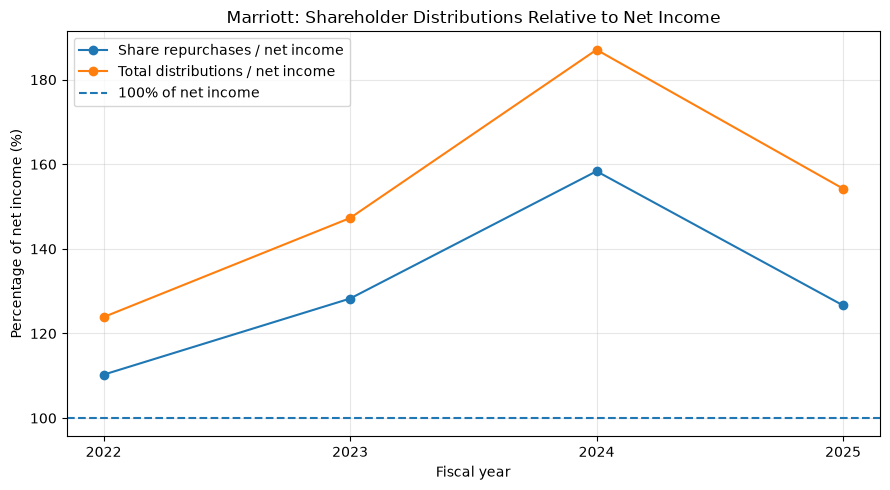

In [711]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    equity_movements_df["year"],
    equity_movements_df["repurchases_pct_net_income"],
    marker="o",
    label="Share repurchases / net income"
)

ax.plot(
    equity_movements_df["year"],
    equity_movements_df["distributions_pct_net_income"],
    marker="o",
    label="Total distributions / net income"
)

ax.axhline(100, linestyle="--", label="100% of net income")

ax.set_title("Marriott: Shareholder Distributions Relative to Net Income")
ax.set_xlabel("Fiscal year")
ax.set_ylabel("Percentage of net income (%)")
ax.set_xticks(equity_movements_df["year"])
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [712]:
# Select the years and columns we need from operating cash flow
cfo_df = df_normal[
    ["year", "operating_cash_flow"]
].copy()

# Convert operating cash flow from USD to USD billions
cfo_df["cfo_usd_bn"] = cfo_df["operating_cash_flow"] / 1_000_000_000

# Merge with shareholder distributions
distribution_coverage_df = distributions_df.merge(
    cfo_df[["year", "cfo_usd_bn"]],
    on="year",
    how="left"
)

# Calculate total distributions and compare with CFO
distribution_coverage_df["total_distributions_bn"] = (
    distribution_coverage_df["dividends_usd_bn"]
    + distribution_coverage_df["repurchases_usd_bn"]
)

distribution_coverage_df["distributions_pct_cfo"] = (
    distribution_coverage_df["total_distributions_bn"]
    / distribution_coverage_df["cfo_usd_bn"] * 100
)

distribution_coverage_df["cfo_less_distributions_bn"] = (
    distribution_coverage_df["cfo_usd_bn"]
    - distribution_coverage_df["total_distributions_bn"]
)

distribution_coverage_df.loc[
    distribution_coverage_df["year"].between(2022, 2025),
    [
        "year",
        "cfo_usd_bn",
        "dividends_usd_bn",
        "repurchases_usd_bn",
        "total_distributions_bn",
        "distributions_pct_cfo",
        "cfo_less_distributions_bn",
    ]
].round(3)

,year,cfo_usd_bn,dividends_usd_bn,repurchases_usd_bn,total_distributions_bn,distributions_pct_cfo,cfo_less_distributions_bn
7,2022,2.363,0.321,2.600,2.921,123.614,-0.558
8,2023,3.170,0.587,3.954,4.541,143.249,-1.371
9,2024,2.749,0.682,3.761,4.443,161.622,-1.694
10,2025,3.212,0.718,3.294,4.012,124.907,-0.800


In [713]:
distribution_coverage_df.loc[
    distribution_coverage_df["year"].between(2022, 2025),
    [
        "year",
        "cfo_usd_bn",
        "dividends_usd_bn",
        "repurchases_usd_bn",
        "total_distributions_bn",
        "distributions_pct_cfo",
        "cfo_less_distributions_bn",
    ]
].round(3).to_csv(
    "marriott_distribution_coverage_2022_2025.csv",
    index=False
)

In [714]:


terms = [
    "OperatingIncomeLoss",
    "InterestExpenseNonOperating",
    "InterestAndDebtExpense",
    "InterestExpenseNonOperatingNet",
    "IncomeLossFromContinuingOperationsBeforeIncomeTaxesExtraordinaryItemsNoncontrollingInterest",
]

for term in terms:
    if term in us_gaap:
        print(f"{term}: {us_gaap[term]['label']}")


OperatingIncomeLoss: Operating Income (Loss)
IncomeLossFromContinuingOperationsBeforeIncomeTaxesExtraordinaryItemsNoncontrollingInterest: Income (Loss) from Continuing Operations before Income Taxes, Noncontrolling Interest


In [715]:

interest_terms = [
    (key, value.get("label") or "")
    for key, value in us_gaap.items()
    if isinstance(value, dict)
    and (
        "interest" in key.lower()
        or "interest" in (value.get("label") or "").lower()
    )
]

for key, label in interest_terms:
    print(f"{key}: {label}")



CapitalLeasesFutureMinimumPaymentsInterestIncludedInPayments: Capital Leases, Future Minimum Payments, Interest Included in Payments
ComprehensiveIncomeNetOfTaxIncludingPortionAttributableToNoncontrollingInterest: Comprehensive Income (Loss), Net of Tax, Including Portion Attributable to Noncontrolling Interest
DebtInstrumentInterestRateStatedPercentage: Debt Instrument, Interest Rate, Stated Percentage
FinanceLeaseInterestPaymentOnLiability: Finance Lease, Interest Payment on Liability
IncomeLossFromContinuingOperationsBeforeIncomeTaxesExtraordinaryItemsNoncontrollingInterest: Income (Loss) from Continuing Operations before Income Taxes, Noncontrolling Interest
IncomeLossFromContinuingOperationsBeforeIncomeTaxesMinorityInterestAndIncomeLossFromEquityMethodInvestments: Income (Loss) from Continuing Operations before Equity Method Investments, Income Taxes, Noncontrolling Interest
IncomeLossFromContinuingOperationsIncludingPortionAttributableToNoncontrollingInterest: Income (Loss) from 

In [716]:

concepts = [
    "OperatingIncomeLoss",
    "InterestExpense",
    "InterestExpenseNonoperating",
    "InterestIncomeExpenseNonoperatingNet",
]

for concept in concepts:
    print(f"\n--- {concept} ---")

    if concept not in us_gaap:
        print("Concept not found.")
        continue

    details = us_gaap[concept]
    print("Label:", details.get("label"))
    print("Description:", details.get("description"))

    units = details.get("units", {})
    print("Available units:", list(units.keys()))

    for unit, facts in units.items():
        annual_facts = [
            fact for fact in facts
            if fact.get("form") == "10-K"
            and fact.get("fp") == "FY"
            and fact.get("end", "").endswith("-12-31")
            and fact.get("fy") in [2021, 2022, 2023, 2024, 2025]
        ]

        if annual_facts:
            facts_df = pd.DataFrame(annual_facts)
            print(f"\nUnit: {unit}")
            display(
                facts_df[
                    [
                        col for col in
                        ["fy", "start", "end", "val", "filed", "accn"]
                        if col in facts_df.columns
                    ]
                ].sort_values(["fy", "filed"])
            )



--- OperatingIncomeLoss ---
Label: Operating Income (Loss)
Description: The net result for the period of deducting operating expenses from operating revenues.
Available units: ['USD']

Unit: USD


,fy,start,end,val,filed,accn
0,2021,2019-01-01,2019-12-31,1800000000,2022-02-15,0001628280-22-002666
1,2021,2020-01-01,2020-12-31,84000000,2022-02-15,0001628280-22-002666
3,2021,2021-01-01,2021-12-31,1750000000,2022-02-15,0001628280-22-002666
2,2022,2020-01-01,2020-12-31,84000000,2023-02-14,0001628280-23-003485
4,2022,2021-01-01,2021-12-31,1750000000,2023-02-14,0001628280-23-003485
6,2022,2022-01-01,2022-12-31,3462000000,2023-02-14,0001628280-23-003485
5,2023,2021-01-01,2021-12-31,1750000000,2024-02-13,0001628280-24-004372
7,2023,2022-01-01,2022-12-31,3462000000,2024-02-13,0001628280-24-004372
9,2023,2023-01-01,2023-12-31,3864000000,2024-02-13,0001628280-24-004372
8,2024,2022-01-01,2022-12-31,3462000000,2025-02-11,0001628280-25-004818



--- InterestExpense ---
Label: Interest Expense
Description: Amount of the cost of borrowed funds accounted for as interest expense.
Available units: ['USD']

Unit: USD


,fy,start,end,val,filed,accn
0,2021,2019-01-01,2019-12-31,394000000,2022-02-15,0001628280-22-002666
1,2021,2020-01-01,2020-12-31,445000000,2022-02-15,0001628280-22-002666
3,2021,2021-01-01,2021-12-31,420000000,2022-02-15,0001628280-22-002666
2,2022,2020-01-01,2020-12-31,445000000,2023-02-14,0001628280-23-003485
4,2022,2021-01-01,2021-12-31,420000000,2023-02-14,0001628280-23-003485
6,2022,2022-01-01,2022-12-31,403000000,2023-02-14,0001628280-23-003485
5,2023,2021-01-01,2021-12-31,420000000,2024-02-13,0001628280-24-004372
7,2023,2022-01-01,2022-12-31,403000000,2024-02-13,0001628280-24-004372
8,2023,2023-01-01,2023-12-31,565000000,2024-02-13,0001628280-24-004372



--- InterestExpenseNonoperating ---
Label: None
Description: None
Available units: ['USD']

Unit: USD


,fy,start,end,val,filed,accn
0,2024,2022-01-01,2022-12-31,403000000,2025-02-11,0001628280-25-004818
1,2024,2023-01-01,2023-12-31,565000000,2025-02-11,0001628280-25-004818
3,2024,2024-01-01,2024-12-31,695000000,2025-02-11,0001628280-25-004818
2,2025,2023-01-01,2023-12-31,565000000,2026-02-10,0001048286-26-000007
4,2025,2024-01-01,2024-12-31,695000000,2026-02-10,0001048286-26-000007
5,2025,2025-01-01,2025-12-31,809000000,2026-02-10,0001048286-26-000007



--- InterestIncomeExpenseNonoperatingNet ---
Label: Interest Income (Expense), Nonoperating, Net
Description: The net amount of nonoperating interest income (expense).
Available units: ['USD']

Unit: USD


,fy,start,end,val,filed,accn
0,2024,2022-01-01,2022-12-31,-377000000,2025-02-11,0001628280-25-004818
1,2024,2023-01-01,2023-12-31,-535000000,2025-02-11,0001628280-25-004818
3,2024,2024-01-01,2024-12-31,-655000000,2025-02-11,0001628280-25-004818
2,2025,2023-01-01,2023-12-31,-535000000,2026-02-10,0001048286-26-000007
4,2025,2024-01-01,2024-12-31,-655000000,2026-02-10,0001048286-26-000007
5,2025,2025-01-01,2025-12-31,-767000000,2026-02-10,0001048286-26-000007


In [717]:

# Annual operating income
operating_income_df = pd.DataFrame({
    "year": [2021, 2022, 2023, 2024, 2025],
    "operating_income_bn": [1.750, 3.462, 3.864, 3.767, 4.141],
})

# Annual gross interest expense, using the available concepts
interest_expense_df = pd.DataFrame({
    "year": [2021, 2022, 2023, 2024, 2025],
    "interest_expense_bn": [0.420, 0.403, 0.565, 0.695, 0.809],
})

# Merge the annual figures
interest_coverage_df = operating_income_df.merge(
    interest_expense_df,
    on="year",
    how="inner",
)

# Calculate interest coverage
interest_coverage_df["interest_coverage_ratio"] = (
    interest_coverage_df["operating_income_bn"]
    / interest_coverage_df["interest_expense_bn"]
)

display(interest_coverage_df.round(2))


,year,operating_income_bn,interest_expense_bn,interest_coverage_ratio
0,2021,1.75,0.42,4.17
1,2022,3.46,0.40,8.59
2,2023,3.86,0.56,6.84
3,2024,3.77,0.70,5.42
4,2025,4.14,0.81,5.12


In [718]:
print(debt_annual.columns.tolist())
display(debt_annual.tail())

['year', 'end', 'long_term_debt_and_leases', 'filed', 'accn', 'debt_change', 'debt_change_pct']


,year,end,long_term_debt_and_leases,filed,accn,debt_change,debt_change_pct
8,2021,2021-12-31,9333000000,2023-02-14,0001628280-23-003485,1.300000e+08,1.412583
9,2022,2022-12-31,9380000000,2024-02-13,0001628280-24-004372,4.700000e+07,0.503589
10,2023,2023-12-31,11320000000,2025-02-11,0001628280-25-004818,1.940000e+09,20.682303
11,2024,2024-12-31,13138000000,2026-02-10,0001048286-26-000007,1.818000e+09,16.060071
12,2025,2025-12-31,14995000000,2026-02-10,0001048286-26-000007,1.857000e+09,14.134571


In [719]:

debt_earnings_df = debt_annual.merge(
    operating_income_df,
    on="year",
    how="inner",
)

debt_earnings_df["debt_leases_to_operating_income"] = (
    debt_earnings_df["long_term_debt_and_leases"]
    / (debt_earnings_df["operating_income_bn"] * 1_000_000_000)
)

display(
    debt_earnings_df[
        [
            "year",
            "long_term_debt_and_leases",
            "operating_income_bn",
            "debt_leases_to_operating_income",
        ]
    ].round(2).reset_index(drop=True)
)


,year,long_term_debt_and_leases,operating_income_bn,debt_leases_to_operating_income
0,2021,9333000000,1.75,5.33
1,2022,9380000000,3.46,2.71
2,2023,11320000000,3.86,2.93
3,2024,13138000000,3.77,3.49
4,2025,14995000000,4.14,3.62


In [720]:
terms = [
    "CashAndCashEquivalentsAtCarryingValue",
    "CashCashEquivalentsRestrictedCashAndRestrictedCashEquivalents",
    "LiabilitiesCurrent",
    "AssetsCurrent",
]

for term in terms:
    if term in us_gaap:
        print(f"{term}: {us_gaap[term].get('label')}")

CashAndCashEquivalentsAtCarryingValue: Cash and Cash Equivalents, at Carrying Value
CashCashEquivalentsRestrictedCashAndRestrictedCashEquivalents: Cash, Cash Equivalents, Restricted Cash and Restricted Cash Equivalents
LiabilitiesCurrent: Liabilities, Current
AssetsCurrent: Assets, Current


In [721]:

import pandas as pd

us_gaap = data["facts"]["us-gaap"]

def extract_annual_fact(concept, years=range(2021, 2026)):
    facts = us_gaap[concept]["units"]["USD"]

    fact_df = pd.DataFrame(facts)

    # Select fiscal-year 10-K facts with December 31 year-end
    fact_df = fact_df[
        (fact_df["form"] == "10-K")
        & (fact_df["fp"] == "FY")
        & (fact_df["end"].str.endswith("-12-31"))
        & (fact_df["fy"].isin(years))
    ].copy()

    # Balance-sheet facts are point-in-time values, so no start-date
    # requirement is needed.
    fact_df["year"] = pd.to_datetime(fact_df["end"]).dt.year

    # Keep the latest filing for each year
    fact_df = (
        fact_df.sort_values("filed")
        .drop_duplicates(subset="year", keep="last")
    )

    return fact_df[["year", "end", "val", "filed"]].sort_values("year")


cash_df = extract_annual_fact("CashAndCashEquivalentsAtCarryingValue")
current_assets_df = extract_annual_fact("AssetsCurrent")
current_liabilities_df = extract_annual_fact("LiabilitiesCurrent")

print("Cash and cash equivalents")
display(cash_df)

print("Current assets")
display(current_assets_df)

print("Current liabilities")
display(current_liabilities_df)


Cash and cash equivalents


,year,end,val,filed
181,2020,2020-12-31,877000000,2022-02-15
189,2021,2021-12-31,1393000000,2023-02-14
197,2022,2022-12-31,507000000,2024-02-13
205,2023,2023-12-31,338000000,2025-02-11
213,2024,2024-12-31,396000000,2026-02-10
217,2025,2025-12-31,358000000,2026-02-10


Current assets


,year,end,val,filed
103,2020,2020-12-31,2825000000,2022-02-15
111,2021,2021-12-31,3626000000,2023-02-14
119,2022,2022-12-31,3313000000,2024-02-13
127,2023,2023-12-31,3311000000,2025-02-11
135,2024,2024-12-31,3485000000,2026-02-10
139,2025,2025-12-31,3584000000,2026-02-10


Current liabilities


,year,end,val,filed
103,2020,2020-12-31,5752000000,2022-02-15
111,2021,2021-12-31,6407000000,2023-02-14
119,2022,2022-12-31,7339000000,2024-02-13
127,2023,2023-12-31,7762000000,2025-02-11
135,2024,2024-12-31,8649000000,2026-02-10
139,2025,2025-12-31,8398000000,2026-02-10


In [722]:
# Merge the three balance-sheet DataFrames
liquidity_df = (
    cash_df[["year", "val"]]
    .merge(
        current_assets_df[["year", "val"]],
        on="year",
        suffixes=("_cash", "_assets")
    )
    .merge(
        current_liabilities_df[["year", "val"]],
        on="year"
    )
    .rename(columns={"val": "current_liabilities"})
)

# Focus on 2021–2025
liquidity_df = liquidity_df[
    liquidity_df["year"].between(2021, 2025)
].copy()

# Calculate ratios
liquidity_df["current_ratio"] = (
    liquidity_df["val_assets"]
    / liquidity_df["current_liabilities"]
)

liquidity_df["cash_ratio"] = (
    liquidity_df["val_cash"]
    / liquidity_df["current_liabilities"]
)

# Display amounts in billions for readability
liquidity_df["cash_bn"] = liquidity_df["val_cash"] / 1e9
liquidity_df["current_assets_bn"] = liquidity_df["val_assets"] / 1e9
liquidity_df["current_liabilities_bn"] = (
    liquidity_df["current_liabilities"] / 1e9
)

display(
    liquidity_df[
        [
            "year",
            "cash_bn",
            "current_assets_bn",
            "current_liabilities_bn",
            "current_ratio",
            "cash_ratio",
        ]
    ].round(3)
)

,year,cash_bn,current_assets_bn,current_liabilities_bn,current_ratio,cash_ratio
1,2021,1.393,3.626,6.407,0.566,0.217
2,2022,0.507,3.313,7.339,0.451,0.069
3,2023,0.338,3.311,7.762,0.427,0.044
4,2024,0.396,3.485,8.649,0.403,0.046
5,2025,0.358,3.584,8.398,0.427,0.043


In [723]:
liquidity_results = liquidity_df[
    [
        "year",
        "cash_bn",
        "current_assets_bn",
        "current_liabilities_bn",
        "current_ratio",
        "cash_ratio",
    ]
].copy()

liquidity_results = liquidity_results.round(3)

# display(liquidity_results)
print(liquidity_results.to_string(index=False))

 year  cash_bn  current_assets_bn  current_liabilities_bn  current_ratio  cash_ratio
 2021    1.393              3.626                   6.407          0.566       0.217
 2022    0.507              3.313                   7.339          0.451       0.069
 2023    0.338              3.311                   7.762          0.427       0.044
 2024    0.396              3.485                   8.649          0.403       0.046
 2025    0.358              3.584                   8.398          0.427       0.043


In [724]:
# Select annual operating cash flow for 2021–2025
cfo_liquidity_df = df_normal.loc[
    df_normal["year"].between(2021, 2025),
    ["year", "operating_cash_flow"]
].copy()

# Merge with current liabilities
cfo_liquidity_df = cfo_liquidity_df.merge(
    current_liabilities_df[["year", "val"]],
    on="year",
    how="inner"
).rename(columns={"val": "current_liabilities"})

# Convert USD to billions
cfo_liquidity_df["operating_cash_flow_bn"] = (
    cfo_liquidity_df["operating_cash_flow"] / 1e9
)

cfo_liquidity_df["current_liabilities_bn"] = (
    cfo_liquidity_df["current_liabilities"] / 1e9
)

# Calculate ratio
cfo_liquidity_df["operating_cash_flow_ratio"] = (
    cfo_liquidity_df["operating_cash_flow"]
    / cfo_liquidity_df["current_liabilities"]
)

print(
    cfo_liquidity_df[
        [
            "year",
            "operating_cash_flow_bn",
            "current_liabilities_bn",
            "operating_cash_flow_ratio",
        ]
    ].round(3).to_string(index=False)
)

 year  operating_cash_flow_bn  current_liabilities_bn  operating_cash_flow_ratio
 2022                   2.363                   7.339                      0.322
 2023                   3.170                   7.762                      0.408
 2024                   2.749                   8.649                      0.318
 2025                   3.212                   8.398                      0.382


In [725]:
# Search relevant current-liability concepts
liability_terms = [
    "DebtCurrent",
    "LongTermDebtCurrent",
    "AccountsPayableCurrent",
    "AccountsPayableTradeCurrent",
    "AccruedLiabilitiesCurrent",
    "OtherLiabilitiesCurrent",
]

for term in liability_terms:
    matches = [
        (concept, details.get("label"))
        for concept, details in us_gaap.items()
        if term.lower() in concept.lower()
    ]

    print(f"\n--- {term} ---")
    for concept, label in matches:
        print(f"{concept}: {label}")


--- DebtCurrent ---
LongTermDebtCurrent: Long-term Debt, Current Maturities

--- LongTermDebtCurrent ---
LongTermDebtCurrent: Long-term Debt, Current Maturities

--- AccountsPayableCurrent ---
AccountsPayableCurrent: Accounts Payable, Current

--- AccountsPayableTradeCurrent ---
AccountsPayableTradeCurrent: Accounts Payable, Trade, Current

--- AccruedLiabilitiesCurrent ---

--- OtherLiabilitiesCurrent ---
OtherLiabilitiesCurrent: Other Liabilities, Current


In [726]:
liability_concepts = {
    "Current debt maturities": "LongTermDebtCurrent",
    "Accounts payable": "AccountsPayableCurrent",
    "Trade accounts payable": "AccountsPayableTradeCurrent",
    "Other current liabilities": "OtherLiabilitiesCurrent",
}

liability_detail = {}

for label, concept in liability_concepts.items():
    result = extract_annual_fact(concept)

    result = result[result["year"].between(2021, 2025)].copy()
    result["val_bn"] = result["val"] / 1e9

    liability_detail[label] = result[
        ["year", "val_bn", "filed"]
    ].rename(columns={"val_bn": label})

    print(f"\n{label} ({concept})")
    print(
        liability_detail[label]
        .round(3)
        .to_string(index=False)
    )


Current debt maturities (LongTermDebtCurrent)
Empty DataFrame
Columns: [year, Current debt maturities, filed]
Index: []

Accounts payable (AccountsPayableCurrent)
Empty DataFrame
Columns: [year, Accounts payable, filed]
Index: []

Trade accounts payable (AccountsPayableTradeCurrent)
 year  Trade accounts payable      filed
 2021                   0.726 2023-02-14
 2022                   0.746 2024-02-13
 2023                   0.738 2025-02-11
 2024                   0.763 2026-02-10
 2025                   0.814 2026-02-10

Other current liabilities (OtherLiabilitiesCurrent)
 year  Other current liabilities      filed
 2021                      1.167 2023-02-14
 2022                      1.296 2024-02-13
 2023                      1.753 2025-02-11
 2024                      1.641 2026-02-10
 2025                      1.440 2026-02-10


In [727]:
for concept, details in us_gaap.items():
    label = details.get("label", "")
    if "debt" in concept.lower():
        if any(
            term in (concept + " " + str(label)).lower()
            for term in ["current", "maturit", "short-term"]
        ):
            print(f"{concept}: {label}")

HeldToMaturitySecuritiesDebtMaturitiesSingleMaturityDateAmortizedCostBasis: Debt Securities, Held-to-maturity, Maturity, Allocated and Single Maturity Date, Amortized Cost
LongTermDebtAndCapitalLeaseObligationsCurrent: Long-term Debt and Lease Obligation, Current
LongTermDebtCurrent: Long-term Debt, Current Maturities
LongTermDebtMaturitiesRepaymentsOfPrincipalAfterYearFive: Long-Term Debt, Maturity, after Year Five
LongTermDebtMaturitiesRepaymentsOfPrincipalInNextTwelveMonths: Long-Term Debt, Maturity, Year One
LongTermDebtMaturitiesRepaymentsOfPrincipalInYearFive: Long-Term Debt, Maturity, Year Five
LongTermDebtMaturitiesRepaymentsOfPrincipalInYearFour: Long-Term Debt, Maturity, Year Four
LongTermDebtMaturitiesRepaymentsOfPrincipalInYearThree: Long-Term Debt, Maturity, Year Three
LongTermDebtMaturitiesRepaymentsOfPrincipalInYearTwo: Long-Term Debt, Maturity, Year Two
LongTermDebtNoncurrent: Long-term Debt, Excluding Current Maturities
MaturitiesOfSeniorDebt: Maturities of Senior Debt

In [728]:
debt_current_concepts = [
    "LongTermDebtAndCapitalLeaseObligationsCurrent",
    "LongTermDebtMaturitiesRepaymentsOfPrincipalInNextTwelveMonths",
]

for concept in debt_current_concepts:
    print(f"\n--- {concept} ---")

    if concept not in us_gaap:
        print("Concept not found")
        continue

    print("Label:", us_gaap[concept].get("label"))

    units = us_gaap[concept].get("units", {})
    print("Available units:", list(units.keys()))

    for unit, facts in units.items():
        facts_df = pd.DataFrame(facts)

        selected = facts_df[
            (facts_df["form"] == "10-K")
            & (facts_df["end"].str.endswith("-12-31"))
            & (facts_df["fy"].isin(range(2021, 2026)))
        ].copy()

        if not selected.empty:
            columns = [
                col for col in
                ["end", "val", "fy", "fp", "filed", "accn", "frame"]
                if col in selected.columns
            ]

            print(f"\nUnit: {unit}")
            print(selected[columns].sort_values("end").to_string(index=False))


--- LongTermDebtAndCapitalLeaseObligationsCurrent ---
Label: Long-term Debt and Lease Obligation, Current
Available units: ['USD']

Unit: USD
       end        val   fy fp      filed                 accn     frame
2020-12-31 1173000000 2021 FY 2022-02-15 0001628280-22-002666 CY2020Q4I
2021-12-31  805000000 2021 FY 2022-02-15 0001628280-22-002666       NaN
2021-12-31  805000000 2022 FY 2023-02-14 0001628280-23-003485 CY2021Q4I
2022-12-31  684000000 2022 FY 2023-02-14 0001628280-23-003485       NaN
2022-12-31  684000000 2023 FY 2024-02-13 0001628280-24-004372 CY2022Q4I
2023-12-31  553000000 2023 FY 2024-02-13 0001628280-24-004372       NaN
2023-12-31  553000000 2024 FY 2025-02-11 0001628280-25-004818 CY2023Q4I
2024-12-31 1309000000 2024 FY 2025-02-11 0001628280-25-004818       NaN
2024-12-31 1309000000 2025 FY 2026-02-10 0001048286-26-000007 CY2024Q4I
2025-12-31 1209000000 2025 FY 2026-02-10 0001048286-26-000007       NaN

--- LongTermDebtMaturitiesRepaymentsOfPrincipalInNextTwelveMonth

In [729]:
# Extract current debt and lease obligations from the raw SEC facts
current_maturities_df = pd.DataFrame(
    us_gaap[
        "LongTermDebtAndCapitalLeaseObligationsCurrent"
    ]["units"]["USD"]
)

current_maturities_df = current_maturities_df[
    (current_maturities_df["form"] == "10-K")
    & (current_maturities_df["fp"] == "FY")
    & (current_maturities_df["end"].isin([
        "2021-12-31",
        "2022-12-31",
        "2023-12-31",
        "2024-12-31",
        "2025-12-31",
    ]))
].copy()

current_maturities_df["year"] = pd.to_datetime(
    current_maturities_df["end"]
).dt.year

current_maturities_df = (
    current_maturities_df
    .sort_values("filed")
    .drop_duplicates("year", keep="last")
    [["year", "val"]]
    .rename(columns={"val": "current_maturities"})
)

# Merge with the existing annual debt series
debt_risk_df = debt_annual[
    ["year", "long_term_debt_and_leases"]
].merge(
    current_maturities_df,
    on="year",
    how="inner"
)

debt_risk_df = debt_risk_df[
    debt_risk_df["year"].between(2021, 2025)
].copy()

debt_risk_df["total_debt_and_leases_bn"] = (
    debt_risk_df["long_term_debt_and_leases"] / 1e9
)

debt_risk_df["current_maturities_bn"] = (
    debt_risk_df["current_maturities"] / 1e9
)

debt_risk_df["current_maturities_pct"] = (
    debt_risk_df["current_maturities"]
    / debt_risk_df["long_term_debt_and_leases"]
    * 100
)

print(
    debt_risk_df[
        [
            "year",
            "total_debt_and_leases_bn",
            "current_maturities_bn",
            "current_maturities_pct",
        ]
    ].round(2).to_string(index=False)
)

 year  total_debt_and_leases_bn  current_maturities_bn  current_maturities_pct
 2021                      9.33                   0.80                    8.63
 2022                      9.38                   0.68                    7.29
 2023                     11.32                   0.55                    4.89
 2024                     13.14                   1.31                    9.96
 2025                     15.00                   1.21                    8.06


In [730]:
debt_risk_df = debt_risk_df.merge(
    cfo_liquidity_df[["year", "operating_cash_flow"]],
    on="year",
    how="left"
)

debt_risk_df["cfo_to_current_maturities"] = (
    debt_risk_df["operating_cash_flow"]
    / debt_risk_df["current_maturities"]
)

print(
    debt_risk_df[
        [
            "year",
            "operating_cash_flow",
            "current_maturities",
            "cfo_to_current_maturities",
        ]
    ].round(2).to_string(index=False)
)

 year  operating_cash_flow  current_maturities  cfo_to_current_maturities
 2021                  NaN           805000000                        NaN
 2022         2363000000.0           684000000                       3.45
 2023         3170000000.0           553000000                       5.73
 2024         2749000000.0          1309000000                       2.10
 2025         3212000000.0          1209000000                       2.66


In [731]:
cash_after_distributions_df = distributions_df[
    ["year", "total_distributions_usd_bn"]
].merge(
    df_normal[["year", "operating_cash_flow"]],
    on="year",
    how="left"
)

# Convert operating cash flow from USD to USD billions
cash_after_distributions_df["operating_cash_flow_usd_bn"] = (
    cash_after_distributions_df["operating_cash_flow"] / 1e9
)

# Cash flow remaining after dividends and share repurchases
cash_after_distributions_df["cfo_after_distributions_usd_bn"] = (
    cash_after_distributions_df["operating_cash_flow_usd_bn"]
    - cash_after_distributions_df["total_distributions_usd_bn"]
)

print(
    cash_after_distributions_df[
        [
            "year",
            "operating_cash_flow_usd_bn",
            "total_distributions_usd_bn",
            "cfo_after_distributions_usd_bn"
        ]
    ].round(3).to_string(index=False)
)

 year  operating_cash_flow_usd_bn  total_distributions_usd_bn  cfo_after_distributions_usd_bn
 2015                       1.430                       2.193                          -0.763
 2016                       1.582                       0.947                           0.635
 2017                       2.436                       3.507                          -1.071
 2018                       2.357                       3.352                          -0.995
 2019                       1.685                       2.872                          -1.187
 2020                         NaN                       0.306                             NaN
 2021                         NaN                         NaN                             NaN
 2022                       2.363                       2.921                          -0.558
 2023                       3.170                       4.541                          -1.371
 2024                       2.749                       4.44

In [732]:
print(current_maturities_df.columns.tolist())
print(current_maturities_df.head())

['year', 'current_maturities']
     year  current_maturities
85   2021           805000000
93   2022           684000000
101  2023           553000000
109  2024          1309000000
113  2025          1209000000


In [733]:
# Merge current debt maturities into the existing analysis
cash_after_distributions_df = cash_after_distributions_df.merge(
    current_maturities_df[["year", "current_maturities"]],
    on="year",
    how="left"
)

# Convert maturities from USD to USD billions
cash_after_distributions_df["current_maturities_usd_bn"] = (
    cash_after_distributions_df["current_maturities"] / 1e9
)

# Calculate the remaining CFO after distributions and current maturities
cash_after_distributions_df[
    "cfo_after_distributions_less_maturities_usd_bn"
] = (
    cash_after_distributions_df["cfo_after_distributions_usd_bn"]
    - cash_after_distributions_df["current_maturities_usd_bn"]
)

print(
    cash_after_distributions_df[
        [
            "year",
            "cfo_after_distributions_usd_bn",
            "current_maturities_usd_bn",
            "cfo_after_distributions_less_maturities_usd_bn"
        ]
    ].round(3).to_string(index=False)
)

 year  cfo_after_distributions_usd_bn  current_maturities_usd_bn  cfo_after_distributions_less_maturities_usd_bn
 2015                          -0.763                        NaN                                             NaN
 2016                           0.635                        NaN                                             NaN
 2017                          -1.071                        NaN                                             NaN
 2018                          -0.995                        NaN                                             NaN
 2019                          -1.187                        NaN                                             NaN
 2020                             NaN                        NaN                                             NaN
 2021                             NaN                      0.805                                             NaN
 2022                          -0.558                      0.684                                

In [734]:
print("Cash and liquidity data:")
print(liquidity_results.columns.tolist())
print(liquidity_results.tail())

print("\nDebt data:")
print(debt_annual.columns.tolist())
print(debt_annual[["year", "long_term_debt_and_leases"]].tail())

Cash and liquidity data:
['year', 'cash_bn', 'current_assets_bn', 'current_liabilities_bn', 'current_ratio', 'cash_ratio']
   year  cash_bn  current_assets_bn  current_liabilities_bn  current_ratio  \
1  2021    1.393              3.626                   6.407          0.566   
2  2022    0.507              3.313                   7.339          0.451   
3  2023    0.338              3.311                   7.762          0.427   
4  2024    0.396              3.485                   8.649          0.403   
5  2025    0.358              3.584                   8.398          0.427   

   cash_ratio  
1       0.217  
2       0.069  
3       0.044  
4       0.046  
5       0.043  

Debt data:
['year', 'end', 'long_term_debt_and_leases', 'filed', 'accn', 'debt_change', 'debt_change_pct']
    year  long_term_debt_and_leases
8   2021                 9333000000
9   2022                 9380000000
10  2023                11320000000
11  2024                13138000000
12  2025                

In [735]:
# 1. Start with cash balances
cash_debt_analysis = liquidity_results[
    ["year", "cash_bn"]
].merge(
    debt_annual[
        ["year", "long_term_debt_and_leases", "debt_change"]
    ],
    on="year",
    how="left"
).merge(
    cash_after_distributions_df[
        [
            "year",
            "cfo_after_distributions_usd_bn",
            "current_maturities_usd_bn",
            "cfo_after_distributions_less_maturities_usd_bn"
        ]
    ],
    on="year",
    how="left"
)

# 2. Convert debt and annual debt changes from USD to USD billions
cash_debt_analysis["debt_and_leases_bn"] = (
    cash_debt_analysis["long_term_debt_and_leases"] / 1e9
)

cash_debt_analysis["debt_change_bn"] = (
    cash_debt_analysis["debt_change"] / 1e9
)

# 3. Calculate the year-over-year change in cash
cash_debt_analysis = cash_debt_analysis.sort_values("year")

cash_debt_analysis["cash_change_bn"] = (
    cash_debt_analysis["cash_bn"].diff()
)

# 4. Display the combined analysis
print(
    cash_debt_analysis[
        [
            "year",
            "cash_bn",
            "cash_change_bn",
            "debt_and_leases_bn",
            "debt_change_bn",
            "cfo_after_distributions_usd_bn",
            "cfo_after_distributions_less_maturities_usd_bn"
        ]
    ].round(3).to_string(index=False)
)

 year  cash_bn  cash_change_bn  debt_and_leases_bn  debt_change_bn  cfo_after_distributions_usd_bn  cfo_after_distributions_less_maturities_usd_bn
 2021    1.393             NaN               9.333           0.130                             NaN                                             NaN
 2022    0.507          -0.886               9.380           0.047                          -0.558                                          -1.242
 2023    0.338          -0.169              11.320           1.940                          -1.371                                          -1.924
 2024    0.396           0.058              13.138           1.818                          -1.694                                          -3.003
 2025    0.358          -0.038              14.995           1.857                          -0.800                                          -2.009


In [736]:
cash_debt_analysis["net_debt_bn"] = (
    cash_debt_analysis["debt_and_leases_bn"]
    - cash_debt_analysis["cash_bn"]
)

cash_debt_analysis["net_debt_change_bn"] = (
    cash_debt_analysis["net_debt_bn"].diff()
)

print(
    cash_debt_analysis[
        [
            "year",
            "cash_bn",
            "debt_and_leases_bn",
            "net_debt_bn",
            "net_debt_change_bn"
        ]
    ].round(3).to_string(index=False)
)

 year  cash_bn  debt_and_leases_bn  net_debt_bn  net_debt_change_bn
 2021    1.393               9.333        7.940                 NaN
 2022    0.507               9.380        8.873               0.933
 2023    0.338              11.320       10.982               2.109
 2024    0.396              13.138       12.742               1.760
 2025    0.358              14.995       14.637               1.895


In [737]:
period = cash_debt_analysis[
    cash_debt_analysis["year"].between(2022, 2025)
]

total_distributions = distributions_df.loc[
    distributions_df["year"].between(2022, 2025),
    "total_distributions_usd_bn"
].sum()

total_cfo = period["cfo_after_distributions_usd_bn"].sum() + total_distributions

net_debt_increase = (
    cash_debt_analysis.loc[
        cash_debt_analysis["year"] == 2025, "net_debt_bn"
    ].iloc[0]
    - cash_debt_analysis.loc[
        cash_debt_analysis["year"] == 2021, "net_debt_bn"
    ].iloc[0]
)

print(f"Total distributions, 2022–2025: ${total_distributions:.3f}bn")
print(f"Total operating cash flow, 2022–2025: ${total_cfo:.3f}bn")
print(f"Net debt increase, 2021–2025: ${net_debt_increase:.3f}bn")

Total distributions, 2022–2025: $15.917bn
Total operating cash flow, 2022–2025: $11.494bn
Net debt increase, 2021–2025: $6.697bn


In [738]:
for tag, details in us_gaap.items():
    label = details.get("label", "")
    description = details.get("description", "")

    text_to_search = f"{tag} {label} {description}".lower()

    if (
        "proceeds from" in text_to_search
        and ("debt" in text_to_search or "borrow" in text_to_search)
    ) or (
        "repayment" in text_to_search
        and ("debt" in text_to_search or "borrow" in text_to_search)
    ):
        print(f"{tag}: {label}")

EarlyRepaymentOfSeniorDebt: Early Repayment of Senior Debt
LongTermDebtMaturitiesRepaymentsOfPrincipalAfterYearFive: Long-Term Debt, Maturity, after Year Five
LongTermDebtMaturitiesRepaymentsOfPrincipalInNextTwelveMonths: Long-Term Debt, Maturity, Year One
LongTermDebtMaturitiesRepaymentsOfPrincipalInYearFive: Long-Term Debt, Maturity, Year Five
LongTermDebtMaturitiesRepaymentsOfPrincipalInYearFour: Long-Term Debt, Maturity, Year Four
LongTermDebtMaturitiesRepaymentsOfPrincipalInYearThree: Long-Term Debt, Maturity, Year Three
LongTermDebtMaturitiesRepaymentsOfPrincipalInYearTwo: Long-Term Debt, Maturity, Year Two
PaymentsOfDebtExtinguishmentCosts: Payment for Debt Extinguishment or Debt Prepayment Cost
ProceedsFromIssuanceOfLongTermDebt: Proceeds from Issuance of Long-term Debt
ProceedsFromMaturitiesPrepaymentsAndCallsOfHeldToMaturitySecurities: Proceeds from Maturities, Prepayments and Calls of Held-to-maturity Securities
ProceedsFromRepaymentsOfShortTermDebt: Proceeds from (Repayment

In [739]:
debt_cash_flow_tags = [
    "ProceedsFromIssuanceOfLongTermDebt",
    "RepaymentsOfLongTermDebt",
    "RepaymentsOfLongTermLinesOfCredit",
    "ProceedsFromRepaymentsOfShortTermDebt",
]

for tag in debt_cash_flow_tags:
    print(f"\n--- {tag} ---")

    if tag not in us_gaap:
        print("Tag not found")
        continue

    units = us_gaap[tag].get("units", {})

    for unit, facts in units.items():
        annual_facts = [
            fact for fact in facts
            if fact.get("form") == "10-K"
            and fact.get("end", "").startswith(("2022", "2023", "2024", "2025"))
        ]

        print(f"Unit: {unit}")
        for fact in annual_facts[-12:]:
            print(
                fact.get("end"),
                fact.get("val"),
                fact.get("fy"),
                fact.get("filed")
            )


--- ProceedsFromIssuanceOfLongTermDebt ---
Unit: USD
2022-12-31 983000000 2022 2023-02-14
2022-12-31 983000000 2023 2024-02-13
2022-12-31 983000000 2024 2025-02-11
2023-12-31 1918000000 2023 2024-02-13
2023-12-31 1918000000 2024 2025-02-11
2023-12-31 1918000000 2025 2026-02-10
2024-12-31 2948000000 2024 2025-02-11
2024-12-31 2948000000 2025 2026-02-10
2025-12-31 3436000000 2025 2026-02-10

--- RepaymentsOfLongTermDebt ---
Unit: USD
2022-12-31 804000000 2022 2023-02-14
2022-12-31 804000000 2023 2024-02-13
2022-12-31 804000000 2024 2025-02-11
2023-12-31 684000000 2023 2024-02-13
2023-12-31 684000000 2024 2025-02-11
2023-12-31 684000000 2025 2026-02-10
2024-12-31 558000000 2024 2025-02-11
2024-12-31 558000000 2025 2026-02-10
2025-12-31 1309000000 2025 2026-02-10

--- RepaymentsOfLongTermLinesOfCredit ---
Unit: USD

--- ProceedsFromRepaymentsOfShortTermDebt ---
Unit: USD


In [740]:
debt_cash_flow_tags = [
    "ProceedsFromIssuanceOfLongTermDebt",
    "RepaymentsOfLongTermDebt",
]

debt_cash_flow_rows = []

for tag in debt_cash_flow_tags:
    facts = us_gaap[tag]["units"]["USD"]

    # Select one 10-K observation per fiscal year.
    for year in range(2022, 2026):
        candidates = [
            f for f in facts
            if f.get("form") == "10-K"
            and f.get("end") == f"{year}-12-31"
            and f.get("fy") == year
        ]

        if candidates:
            # Use the latest filing for that fiscal year's reported fact.
            fact = max(candidates, key=lambda f: f.get("filed", ""))

            debt_cash_flow_rows.append({
                "year": year,
                "tag": tag,
                "value_usd_bn": fact["val"] / 1e9,
            })

debt_cash_flow_long = pd.DataFrame(debt_cash_flow_rows)

debt_cash_flow_df = (
    debt_cash_flow_long
    .pivot(index="year", columns="tag", values="value_usd_bn")
    .reset_index()
    .rename(columns={
        "ProceedsFromIssuanceOfLongTermDebt": "long_term_debt_issued_bn",
        "RepaymentsOfLongTermDebt": "long_term_debt_repaid_bn",
    })
)

debt_cash_flow_df["net_debt_issuance_bn"] = (
    debt_cash_flow_df["long_term_debt_issued_bn"]
    - debt_cash_flow_df["long_term_debt_repaid_bn"]
)

print(debt_cash_flow_df.round(3).to_string(index=False))

 year  long_term_debt_issued_bn  long_term_debt_repaid_bn  net_debt_issuance_bn
 2022                     0.983                     0.804                 0.179
 2023                     1.918                     0.684                 1.234
 2024                     2.948                     0.558                 2.390
 2025                     3.436                     1.309                 2.127


In [741]:
debt_reconciliation_df = debt_cash_flow_df.merge(
    debt_annual[["year", "debt_change"]],
    on="year",
    how="left"
)

debt_reconciliation_df["balance_sheet_debt_change_bn"] = (
    debt_reconciliation_df["debt_change"] / 1e9
)

debt_reconciliation_df["difference_bn"] = (
    debt_reconciliation_df["balance_sheet_debt_change_bn"]
    - debt_reconciliation_df["net_debt_issuance_bn"]
)

print(
    debt_reconciliation_df[
        [
            "year",
            "net_debt_issuance_bn",
            "balance_sheet_debt_change_bn",
            "difference_bn"
        ]
    ].round(3).to_string(index=False)
)

 year  net_debt_issuance_bn  balance_sheet_debt_change_bn  difference_bn
 2022                 0.179                         0.047         -0.132
 2023                 1.234                         1.940          0.706
 2024                 2.390                         1.818         -0.572
 2025                 2.127                         1.857         -0.270


In [742]:
additional_debt_tags = [
    "RepaymentsOfLongTermLinesOfCredit",
    "RepaymentsOfOtherLongTermDebt",
    "ProceedsFromRepaymentsOfShortTermDebt",
    "PaymentsOfDebtExtinguishmentCosts",
]

for tag in additional_debt_tags:
    print(f"\n--- {tag} ---")

    if tag not in us_gaap:
        print("Tag not found")
        continue

    for unit, facts in us_gaap[tag].get("units", {}).items():
        annual_facts = [
            f for f in facts
            if f.get("form") == "10-K"
            and f.get("fy") in [2022, 2023, 2024, 2025]
            and f.get("end") == f"{f.get('fy')}-12-31"
        ]

        # One reported observation per fiscal year
        by_year = {}
        for f in annual_facts:
            year = f["fy"]
            if year not in by_year or f.get("filed", "") > by_year[year].get("filed", ""):
                by_year[year] = f

        print("Unit:", unit)
        for year in sorted(by_year):
            f = by_year[year]
            print(year, f["val"], "filed:", f["filed"])


--- RepaymentsOfLongTermLinesOfCredit ---
Unit: USD

--- RepaymentsOfOtherLongTermDebt ---
Unit: USD

--- ProceedsFromRepaymentsOfShortTermDebt ---
Unit: USD

--- PaymentsOfDebtExtinguishmentCosts ---
Unit: USD
2022 0 filed: 2023-02-14
2023 0 filed: 2024-02-13


In [743]:
print(
    "Cumulative net long-term debt issuance:",
    round(debt_reconciliation_df["net_debt_issuance_bn"].sum(), 3),
    "bn USD"
)

print(
    "Cumulative increase in debt and leases:",
    round(debt_reconciliation_df["balance_sheet_debt_change_bn"].sum(), 3),
    "bn USD"
)

print(
    "Cumulative difference:",
    round(debt_reconciliation_df["difference_bn"].sum(), 3),
    "bn USD"
)

Cumulative net long-term debt issuance: 5.93 bn USD
Cumulative increase in debt and leases: 5.662 bn USD
Cumulative difference: -0.268 bn USD


In [744]:
# Combine noncurrent long-term debt with current maturities
total_debt_analysis = debt_annual[
    ["year", "long_term_debt_and_leases"]
].merge(
    current_maturities_df[["year", "current_maturities"]],
    on="year",
    how="left"
).merge(
    liquidity_results[["year", "cash_bn"]],
    on="year",
    how="left"
)

# Convert USD to USD billions
total_debt_analysis["long_term_debt_bn"] = (
    total_debt_analysis["long_term_debt_and_leases"] / 1e9
)

total_debt_analysis["current_debt_bn"] = (
    total_debt_analysis["current_maturities"] / 1e9
)

total_debt_analysis["total_debt_bn"] = (
    total_debt_analysis["long_term_debt_bn"]
    + total_debt_analysis["current_debt_bn"]
)

total_debt_analysis["net_debt_bn"] = (
    total_debt_analysis["total_debt_bn"]
    - total_debt_analysis["cash_bn"]
)

print(
    total_debt_analysis[
        [
            "year",
            "long_term_debt_bn",
            "current_debt_bn",
            "total_debt_bn",
            "cash_bn",
            "net_debt_bn"
        ]
    ].round(3).to_string(index=False)
)

 year  long_term_debt_bn  current_debt_bn  total_debt_bn  cash_bn  net_debt_bn
 2013              3.147              NaN            NaN      NaN          NaN
 2014              3.447              NaN            NaN      NaN          NaN
 2015              3.807              NaN            NaN      NaN          NaN
 2016              8.197              NaN            NaN      NaN          NaN
 2017              7.840              NaN            NaN      NaN          NaN
 2018              8.514              NaN            NaN      NaN          NaN
 2019              9.963              NaN            NaN      NaN          NaN
 2020              9.203              NaN            NaN      NaN          NaN
 2021              9.333            0.805         10.138    1.393        8.745
 2022              9.380            0.684         10.064    0.507        9.557
 2023             11.320            0.553         11.873    0.338       11.535
 2024             13.138            1.309         14

In [745]:
# Combine noncurrent long-term debt with current maturities
total_debt_analysis = debt_annual[
    ["year", "long_term_debt_and_leases"]
].merge(
    current_maturities_df[["year", "current_maturities"]],
    on="year",
    how="left"
).merge(
    liquidity_results[["year", "cash_bn"]],
    on="year",
    how="left"
)

# Convert USD to USD billions
total_debt_analysis["long_term_debt_bn"] = (
    total_debt_analysis["long_term_debt_and_leases"] / 1e9
)

total_debt_analysis["current_debt_bn"] = (
    total_debt_analysis["current_maturities"] / 1e9
)

total_debt_analysis["total_debt_bn"] = (
    total_debt_analysis["long_term_debt_bn"]
    + total_debt_analysis["current_debt_bn"]
)

total_debt_analysis["net_debt_bn"] = (
    total_debt_analysis["total_debt_bn"]
    - total_debt_analysis["cash_bn"]
)

print(
    total_debt_analysis[
        [
            "year",
            "long_term_debt_bn",
            "current_debt_bn",
            "total_debt_bn",
            "cash_bn",
            "net_debt_bn"
        ]
    ].round(3).to_string(index=False)
)

 year  long_term_debt_bn  current_debt_bn  total_debt_bn  cash_bn  net_debt_bn
 2013              3.147              NaN            NaN      NaN          NaN
 2014              3.447              NaN            NaN      NaN          NaN
 2015              3.807              NaN            NaN      NaN          NaN
 2016              8.197              NaN            NaN      NaN          NaN
 2017              7.840              NaN            NaN      NaN          NaN
 2018              8.514              NaN            NaN      NaN          NaN
 2019              9.963              NaN            NaN      NaN          NaN
 2020              9.203              NaN            NaN      NaN          NaN
 2021              9.333            0.805         10.138    1.393        8.745
 2022              9.380            0.684         10.064    0.507        9.557
 2023             11.320            0.553         11.873    0.338       11.535
 2024             13.138            1.309         14

In [746]:
# Combine noncurrent long-term debt with current maturities
total_debt_analysis = debt_annual[
    ["year", "long_term_debt_and_leases"]
].merge(
    current_maturities_df[["year", "current_maturities"]],
    on="year",
    how="left"
).merge(
    liquidity_results[["year", "cash_bn"]],
    on="year",
    how="left"
)

# Convert USD to USD billions
total_debt_analysis["long_term_debt_bn"] = (
    total_debt_analysis["long_term_debt_and_leases"] / 1e9
)

total_debt_analysis["current_debt_bn"] = (
    total_debt_analysis["current_maturities"] / 1e9
)

total_debt_analysis["total_debt_bn"] = (
    total_debt_analysis["long_term_debt_bn"]
    + total_debt_analysis["current_debt_bn"]
)

total_debt_analysis["net_debt_bn"] = (
    total_debt_analysis["total_debt_bn"]
    - total_debt_analysis["cash_bn"]
)

print(
    total_debt_analysis[
        [
            "year",
            "long_term_debt_bn",
            "current_debt_bn",
            "total_debt_bn",
            "cash_bn",
            "net_debt_bn"
        ]
    ].round(3).to_string(index=False)
)

 year  long_term_debt_bn  current_debt_bn  total_debt_bn  cash_bn  net_debt_bn
 2013              3.147              NaN            NaN      NaN          NaN
 2014              3.447              NaN            NaN      NaN          NaN
 2015              3.807              NaN            NaN      NaN          NaN
 2016              8.197              NaN            NaN      NaN          NaN
 2017              7.840              NaN            NaN      NaN          NaN
 2018              8.514              NaN            NaN      NaN          NaN
 2019              9.963              NaN            NaN      NaN          NaN
 2020              9.203              NaN            NaN      NaN          NaN
 2021              9.333            0.805         10.138    1.393        8.745
 2022              9.380            0.684         10.064    0.507        9.557
 2023             11.320            0.553         11.873    0.338       11.535
 2024             13.138            1.309         14

In [747]:
for tag, details in us_gaap.items():
    label = details.get("label", "")
    description = details.get("description", "")

    search_text = f"{tag} {label} {description}".lower()

    if any(term in search_text for term in [
        "commercial paper",
        "credit facility",
        "credit facilities",
        "proceeds from issuance of debt",
        "repayments of debt",
        "borrowings under"
    ]):
        print(f"{tag}: {label}")

AvailableForSaleSecuritiesFairValueDisclosure: Available-for-sale Securities, Fair Value Disclosure (Deprecated 2013-01-31)
CommercialPaperNoncurrent: Long-term Commercial Paper, Noncurrent
LineOfCreditFacilityAmountOutstanding: Line of Credit Facility, Amount Outstanding (Deprecated 2014-01-31)
LineOfCreditFacilityCurrentBorrowingCapacity: Line of Credit Facility, Current Borrowing Capacity
LineOfCreditFacilityInterestRateDuringPeriod: Line of Credit Facility, Interest Rate During Period
LineOfCreditFacilityMaximumBorrowingCapacity: Line of Credit Facility, Maximum Borrowing Capacity
LongTermDebt: Long-term Debt
LongTermDebtCurrent: Long-term Debt, Current Maturities
LongTermDebtNoncurrent: Long-term Debt, Excluding Current Maturities
LongtermCommercialPaperCurrentAndNoncurrent: Long-term Commercial Paper


In [748]:
tags_to_inspect = [
    "LongTermDebt",
    "LongTermDebtCurrent",
    "LongTermDebtNoncurrent",
    "CommercialPaperNoncurrent",
    "LongtermCommercialPaperCurrentAndNoncurrent",
    "LineOfCreditFacilityCurrentBorrowingCapacity",
    "LineOfCreditFacilityMaximumBorrowingCapacity",
]

for tag in tags_to_inspect:
    print(f"\n--- {tag} ---")

    if tag not in us_gaap:
        print("Tag not found")
        continue

    for unit, facts in us_gaap[tag].get("units", {}).items():
        by_year = {}

        for f in facts:
            year = f.get("fy")

            if (
                f.get("form") == "10-K"
                and year in [2021, 2022, 2023, 2024, 2025]
                and f.get("end") == f"{year}-12-31"
            ):
                if (
                    year not in by_year
                    or f.get("filed", "") > by_year[year].get("filed", "")
                ):
                    by_year[year] = f

        print("Unit:", unit)

        for year in sorted(by_year):
            f = by_year[year]
            print(
                year,
                round(f["val"] / 1e9, 3) if unit == "USD" else f["val"],
                "filed:", f["filed"]
            )


--- LongTermDebt ---
Unit: USD
2021 0.135 filed: 2022-02-15
2022 0.092 filed: 2023-02-14
2023 0.056 filed: 2024-02-13
2024 0.055 filed: 2025-02-11
2025 0.023 filed: 2026-02-10

--- LongTermDebtCurrent ---
Unit: USD

--- LongTermDebtNoncurrent ---
Unit: USD

--- CommercialPaperNoncurrent ---
Unit: USD
2022 0.871 filed: 2023-02-14
2023 1.421 filed: 2024-02-13
2024 1.582 filed: 2025-02-11
2025 1.177 filed: 2026-02-10

--- LongtermCommercialPaperCurrentAndNoncurrent ---
Unit: USD

--- LineOfCreditFacilityCurrentBorrowingCapacity ---
Unit: USD

--- LineOfCreditFacilityMaximumBorrowingCapacity ---
Unit: USD
2021 4.5 filed: 2022-02-15
2022 4.5 filed: 2023-02-14
2023 4.5 filed: 2024-02-13
2024 4.5 filed: 2025-02-11
2025 4.5 filed: 2026-02-10


In [749]:
tags_to_inspect = [
    "LongTermDebt",
    "CommercialPaperNoncurrent",
    "LongTermDebtCurrent",
    "LongTermDebtNoncurrent",
]

for tag in tags_to_inspect:
    if tag in us_gaap:
        item = us_gaap[tag]
        print(f"\n{tag}")
        print("Label:", item.get("label"))
        print("Description:", item.get("description"))


LongTermDebt
Label: Long-term Debt
Description: Amount, after unamortized (discount) premium and debt issuance costs, of long-term debt. Includes, but not limited to, notes payable, bonds payable, debentures, mortgage loans and commercial paper. Excludes capital lease obligations.

CommercialPaperNoncurrent
Label: Long-term Commercial Paper, Noncurrent
Description: Carrying value as of the balance sheet date of long-term unsecured obligations issued by corporations and other borrowers to investors (with maturities initially due after one year or beyond the operating cycle if longer), excluding current portion.

LongTermDebtCurrent
Label: Long-term Debt, Current Maturities
Description: Amount, after unamortized (discount) premium and debt issuance costs, of long-term debt, classified as current. Includes, but not limited to, notes payable, bonds payable, debentures, mortgage loans and commercial paper. Excludes capital lease obligations.

LongTermDebtNoncurrent
Label: Long-term Debt, E

In [750]:
tags_to_inspect = [
    "LongTermDebt",
    "LongTermDebtCurrent",
    "LongTermDebtNoncurrent",
]

for tag in tags_to_inspect:
    print(f"\n--- {tag} ---")

    units = us_gaap[tag].get("units", {})

    for unit, facts in units.items():
        print("Unit:", unit)

        for fact in facts:
            if (
                fact.get("form") == "10-K"
                and fact.get("end", "").startswith(("2021-", "2022-", "2023-", "2024-", "2025-"))
            ):
                print(
                    fact.get("end"),
                    fact.get("val"),
                    "FY:", fact.get("fy"),
                    "Filed:", fact.get("filed"),
                    "Accn:", fact.get("accn"),
                )


--- LongTermDebt ---
Unit: USD
2021-12-31 135000000 FY: 2021 Filed: 2022-02-15 Accn: 0001628280-22-002666
2021-12-31 135000000 FY: 2022 Filed: 2023-02-14 Accn: 0001628280-23-003485
2022-12-31 92000000 FY: 2022 Filed: 2023-02-14 Accn: 0001628280-23-003485
2022-12-31 92000000 FY: 2023 Filed: 2024-02-13 Accn: 0001628280-24-004372
2023-12-31 56000000 FY: 2023 Filed: 2024-02-13 Accn: 0001628280-24-004372
2023-12-31 56000000 FY: 2024 Filed: 2025-02-11 Accn: 0001628280-25-004818
2024-12-31 55000000 FY: 2024 Filed: 2025-02-11 Accn: 0001628280-25-004818
2024-12-31 55000000 FY: 2025 Filed: 2026-02-10 Accn: 0001048286-26-000007
2025-12-31 23000000 FY: 2025 Filed: 2026-02-10 Accn: 0001048286-26-000007

--- LongTermDebtCurrent ---
Unit: USD

--- LongTermDebtNoncurrent ---
Unit: USD


In [751]:
for tag, item in us_gaap.items():
    label = item.get("label", "")
    description = item.get("description", "")

    if any(word in f"{tag} {label} {description}".lower()
           for word in ["debt", "commercial paper", "capital lease"]):
        print(f"{tag}: {label}")

AccumulatedOtherComprehensiveIncomeLossAvailableForSaleSecuritiesAdjustmentNetOfTax: AOCI, Debt Securities, Available-for-sale, Adjustment, after Tax
AccumulatedOtherComprehensiveIncomeLossNetOfTax: Accumulated Other Comprehensive Income (Loss), Net of Tax
AdditionalPaidInCapital: Additional Paid in Capital
AllowanceForLoanAndLeaseLossesProvisionForLossNet: Allowance for Loan and Lease Losses, Provision for Loss, Net (Deprecated 2013-01-31)
AvailableForSaleSecurities: Available-for-sale Securities
AvailableForSaleSecuritiesAmortizedCost: Available-for-sale Securities, Amortized Cost Basis
AvailableForSaleSecuritiesFairValueDisclosure: Available-for-sale Securities, Fair Value Disclosure (Deprecated 2013-01-31)
AvailableForSaleSecuritiesGrossRealizedGains: Available-for-sale Securities, Gross Realized Gains
CapitalLeasedAssetsGross: Capital Leased Assets, Gross
CapitalLeaseObligations: Capital Lease Obligations
CapitalLeasesBalanceSheetAssetsByMajorClassNet: Capital Leases, Balance Shee

In [752]:
tags_to_check = [
    "DebtAndCapitalLeaseObligations",
    "LongTermDebtAndCapitalLeaseObligations",
    "LongTermDebtAndCapitalLeaseObligationsCurrent",
    "OtherLongTermDebt",
    "LongTermDebtMaturitiesRepaymentsOfPrincipalInNextTwelveMonths",
]

for tag in tags_to_check:
    print(f"\n--- {tag} ---")

    units = us_gaap.get(tag, {}).get("units", {})

    for unit, facts in units.items():
        print("Unit:", unit)

        for fact in facts:
            if (
                fact.get("form") == "10-K"
                and fact.get("end") in [
                    f"{year}-12-31" for year in range(2021, 2026)
                ]
                and fact.get("fy") == int(fact["end"][:4])
            ):
                print(
                    fact["end"],
                    round(fact["val"] / 1e9, 3),
                    "bn; filed:",
                    fact["filed"],
                )


--- DebtAndCapitalLeaseObligations ---
Unit: USD
2021-12-31 10.138 bn; filed: 2022-02-15
2022-12-31 10.064 bn; filed: 2023-02-14
2023-12-31 11.873 bn; filed: 2024-02-13
2024-12-31 14.447 bn; filed: 2025-02-11
2025-12-31 16.204 bn; filed: 2026-02-10

--- LongTermDebtAndCapitalLeaseObligations ---
Unit: USD
2021-12-31 9.333 bn; filed: 2022-02-15
2022-12-31 9.38 bn; filed: 2023-02-14
2023-12-31 11.32 bn; filed: 2024-02-13
2024-12-31 13.138 bn; filed: 2025-02-11
2025-12-31 14.995 bn; filed: 2026-02-10

--- LongTermDebtAndCapitalLeaseObligationsCurrent ---
Unit: USD
2021-12-31 0.805 bn; filed: 2022-02-15
2022-12-31 0.684 bn; filed: 2023-02-14
2023-12-31 0.553 bn; filed: 2024-02-13
2024-12-31 1.309 bn; filed: 2025-02-11
2025-12-31 1.209 bn; filed: 2026-02-10

--- OtherLongTermDebt ---
Unit: USD

--- LongTermDebtMaturitiesRepaymentsOfPrincipalInNextTwelveMonths ---
Unit: USD
2021-12-31 0.805 bn; filed: 2022-02-15
2022-12-31 0.684 bn; filed: 2023-02-14
2023-12-31 0.553 bn; filed: 2024-02-13
2

In [753]:
tag = "DebtAndCapitalLeaseObligations"

facts = us_gaap[tag]["units"]["USD"]

debt_total_df = pd.DataFrame([
    {
        "year": int(f["end"][:4]),
        "total_debt_bn": f["val"] / 1e9,
        "filed": f["filed"],
        "accn": f["accn"],
    }
    for f in facts
    if (
        f.get("form") == "10-K"
        and f.get("end") in [
            f"{year}-12-31" for year in range(2021, 2026)
        ]
        and f.get("fy") == int(f["end"][:4])
    )
])

debt_total_df = (
    debt_total_df
    .sort_values(["year", "filed"])
    .drop_duplicates("year", keep="last")
    .sort_values("year")
    .reset_index(drop=True)
)

debt_total_df["debt_change_bn"] = (
    debt_total_df["total_debt_bn"].diff()
)

debt_total_df["debt_change_pct"] = (
    debt_total_df["total_debt_bn"].pct_change() * 100
)

debt_total_df.round(3)

,year,total_debt_bn,filed,accn,debt_change_bn,debt_change_pct
0,2021,10.138,2022-02-15,0001628280-22-002666,NaN,NaN
1,2022,10.064,2023-02-14,0001628280-23-003485,-0.074,-0.730
2,2023,11.873,2024-02-13,0001628280-24-004372,1.809,17.975
3,2024,14.447,2025-02-11,0001628280-25-004818,2.574,21.679
4,2025,16.204,2026-02-10,0001048286-26-000007,1.757,12.162


In [754]:
tag = "DebtAndCapitalLeaseObligations"

facts = us_gaap[tag]["units"]["USD"]

debt_total_df = pd.DataFrame([
    {
        "year": int(f["end"][:4]),
        "total_debt_bn": f["val"] / 1e9,
        "filed": f["filed"],
        "accn": f["accn"],
    }
    for f in facts
    if (
        f.get("form") == "10-K"
        and f.get("end") in [
            f"{year}-12-31" for year in range(2021, 2026)
        ]
        and f.get("fy") == int(f["end"][:4])
    )
])

debt_total_df = (
    debt_total_df
    .sort_values(["year", "filed"])
    .drop_duplicates("year", keep="last")
    .sort_values("year")
    .reset_index(drop=True)
)

debt_total_df["debt_change_bn"] = (
    debt_total_df["total_debt_bn"].diff()
)

debt_total_df["debt_change_pct"] = (
    debt_total_df["total_debt_bn"].pct_change() * 100
)

debt_total_df.round(3)

,year,total_debt_bn,filed,accn,debt_change_bn,debt_change_pct
0,2021,10.138,2022-02-15,0001628280-22-002666,NaN,NaN
1,2022,10.064,2023-02-14,0001628280-23-003485,-0.074,-0.730
2,2023,11.873,2024-02-13,0001628280-24-004372,1.809,17.975
3,2024,14.447,2025-02-11,0001628280-25-004818,2.574,21.679
4,2025,16.204,2026-02-10,0001048286-26-000007,1.757,12.162


In [755]:
debt_reconciliation_total_df = debt_total_df[
    ["year", "total_debt_bn", "debt_change_bn"]
].merge(
    debt_cash_flow_df[
        ["year", "long_term_debt_issued_bn",
         "long_term_debt_repaid_bn", "net_debt_issuance_bn"]
    ],
    on="year",
    how="left"
)

debt_reconciliation_total_df["difference_bn"] = (
    debt_reconciliation_total_df["debt_change_bn"]
    - debt_reconciliation_total_df["net_debt_issuance_bn"]
)

debt_reconciliation_total_df.round(3)

,year,total_debt_bn,debt_change_bn,long_term_debt_issued_bn,long_term_debt_repaid_bn,net_debt_issuance_bn,difference_bn
0,2021,10.138,NaN,NaN,NaN,NaN,NaN
1,2022,10.064,-0.074,0.983,0.804,0.179,-0.253
2,2023,11.873,1.809,1.918,0.684,1.234,0.575
3,2024,14.447,2.574,2.948,0.558,2.390,0.184
4,2025,16.204,1.757,3.436,1.309,2.127,-0.370


In [756]:
commercial_paper_df = pd.DataFrame([
    {
        "year": int(f["end"][:4]),
        "commercial_paper_noncurrent_bn": f["val"] / 1e9,
        "filed": f["filed"],
    }
    for f in us_gaap["CommercialPaperNoncurrent"]["units"]["USD"]
    if (
        f.get("form") == "10-K"
        and f.get("end") in [
            f"{year}-12-31" for year in range(2021, 2026)
        ]
        and f.get("fy") == int(f["end"][:4])
    )
])

commercial_paper_df = (
    commercial_paper_df
    .sort_values(["year", "filed"])
    .drop_duplicates("year", keep="last")
)

commercial_paper_df.merge(
    debt_total_df[["year", "total_debt_bn"]],
    on="year",
    how="right"
).round(3)

,year,commercial_paper_noncurrent_bn,filed,total_debt_bn
0,2021,NaN,NaN,10.138
1,2022,0.871,2023-02-14,10.064
2,2023,1.421,2024-02-13,11.873
3,2024,1.582,2025-02-11,14.447
4,2025,1.177,2026-02-10,16.204


In [757]:
for namespace, concepts in data["facts"].items():
    print(f"\n=== Namespace: {namespace} ===")

    for tag, item in concepts.items():
        label = item.get("label", "")
        description = item.get("description", "")
        text_to_check = f"{tag} {label} {description}".lower()

        if (
            "commercial paper" in text_to_check
            or "credit facility" in text_to_check
        ):
            print(f"{tag}: {label}")


=== Namespace: dei ===

=== Namespace: us-gaap ===
AvailableForSaleSecuritiesFairValueDisclosure: Available-for-sale Securities, Fair Value Disclosure (Deprecated 2013-01-31)
CommercialPaperNoncurrent: Long-term Commercial Paper, Noncurrent
LineOfCreditFacilityAmountOutstanding: Line of Credit Facility, Amount Outstanding (Deprecated 2014-01-31)
LineOfCreditFacilityCurrentBorrowingCapacity: Line of Credit Facility, Current Borrowing Capacity
LineOfCreditFacilityInterestRateDuringPeriod: Line of Credit Facility, Interest Rate During Period
LineOfCreditFacilityMaximumBorrowingCapacity: Line of Credit Facility, Maximum Borrowing Capacity
LongTermDebt: Long-term Debt
LongTermDebtCurrent: Long-term Debt, Current Maturities
LongTermDebtNoncurrent: Long-term Debt, Excluding Current Maturities
LongtermCommercialPaperCurrentAndNoncurrent: Long-term Commercial Paper

=== Namespace: ffd ===


In [758]:
debt_cash_flow_df[
    [
        "year",
        "long_term_debt_issued_bn",
        "long_term_debt_repaid_bn",
        "net_debt_issuance_bn",
    ]
].round(3)

tag,year,long_term_debt_issued_bn,long_term_debt_repaid_bn,net_debt_issuance_bn
0,2022,0.983,0.804,0.179
1,2023,1.918,0.684,1.234
2,2024,2.948,0.558,2.390
3,2025,3.436,1.309,2.127


In [759]:
# Commercial paper / Credit Facility, net
commercial_paper_df = pd.DataFrame({
    "year": [2022, 2023, 2024, 2025],
    "commercial_paper_credit_facility_net_bn": [
        -0.182, 0.546, 0.163, -0.403
    ]
})

# Extend the existing debt reconciliation
debt_reconciliation_extended_df = (
    debt_reconciliation_total_df
    .merge(commercial_paper_df, on="year", how="left")
)

# Combine the two financing cash-flow categories
debt_reconciliation_extended_df["total_net_financing_bn"] = (
    debt_reconciliation_extended_df["net_debt_issuance_bn"]
    + debt_reconciliation_extended_df[
        "commercial_paper_credit_facility_net_bn"
    ]
)

# Compare debt balance changes with combined financing cash flows
debt_reconciliation_extended_df[
    "difference_after_commercial_paper_bn"
] = (
    debt_reconciliation_extended_df["debt_change_bn"]
    - debt_reconciliation_extended_df["total_net_financing_bn"]
)

debt_reconciliation_extended_df[
    [
        "year",
        "debt_change_bn",
        "net_debt_issuance_bn",
        "commercial_paper_credit_facility_net_bn",
        "total_net_financing_bn",
        "difference_after_commercial_paper_bn"
    ]
].round(3)

,year,debt_change_bn,net_debt_issuance_bn,commercial_paper_credit_facility_net_bn,total_net_financing_bn,difference_after_commercial_paper_bn
0,2021,NaN,NaN,NaN,NaN,NaN
1,2022,-0.074,0.179,-0.182,-0.003,-0.071
2,2023,1.809,1.234,0.546,1.780,0.029
3,2024,2.574,2.390,0.163,2.553,0.021
4,2025,1.757,2.127,-0.403,1.724,0.033


In [760]:
debt_reconciliation_extended_df["difference_pct_of_abs_debt_change"] = (
    debt_reconciliation_extended_df["difference_after_commercial_paper_bn"]
    / debt_reconciliation_extended_df["debt_change_bn"].abs()
    * 100
)

debt_reconciliation_extended_df[
    [
        "year",
        "debt_change_bn",
        "difference_after_commercial_paper_bn",
        "difference_pct_of_abs_debt_change"
    ]
].round(2)

,year,debt_change_bn,difference_after_commercial_paper_bn,difference_pct_of_abs_debt_change
0,2021,NaN,NaN,NaN
1,2022,-0.07,-0.07,-95.95
2,2023,1.81,0.03,1.60
3,2024,2.57,0.02,0.82
4,2025,1.76,0.03,1.88


In [761]:
operating_income = pd.DataFrame({
    "year": [2021, 2022, 2023, 2024, 2025],
    "operating_income_bn": [
        1.750, 3.462, 3.864, 3.767, 4.141
    ]
})

operating_income

,year,operating_income_bn
0,2021,1.750
1,2022,3.462
2,2023,3.864
3,2024,3.767
4,2025,4.141


In [762]:
print(total_debt_analysis.columns.tolist())

['year', 'long_term_debt_and_leases', 'current_maturities', 'cash_bn', 'long_term_debt_bn', 'current_debt_bn', 'total_debt_bn', 'net_debt_bn']


In [763]:
debt_vs_income_df = (
    total_debt_analysis[
        ["year", "total_debt_bn", "net_debt_bn"]
    ]
    .merge(operating_income, on="year", how="inner")
)

debt_vs_income_df["debt_to_operating_income"] = (
    debt_vs_income_df["total_debt_bn"]
    / debt_vs_income_df["operating_income_bn"]
)

debt_vs_income_df["net_debt_to_operating_income"] = (
    debt_vs_income_df["net_debt_bn"]
    / debt_vs_income_df["operating_income_bn"]
)

debt_vs_income_df.round(2)

,year,total_debt_bn,net_debt_bn,operating_income_bn,debt_to_operating_income,net_debt_to_operating_income
0,2021,10.14,8.74,1.75,5.79,5.00
1,2022,10.06,9.56,3.46,2.91,2.76
2,2023,11.87,11.54,3.86,3.07,2.99
3,2024,14.45,14.05,3.77,3.84,3.73
4,2025,16.20,15.85,4.14,3.91,3.83


In [764]:
print([name for name in globals() if "cash" in name.lower() or "cfo" in name.lower()])

['cash_flow_operations', 'get_cash_flow_signal', 'cfo_df', 'distribution_cfo_df', 'cfo_compare', 'cash_df', 'cfo_liquidity_df', 'cash_after_distributions_df', 'cash_debt_analysis', 'total_cfo', 'debt_cash_flow_tags', 'debt_cash_flow_rows', 'debt_cash_flow_long', 'debt_cash_flow_df', 'cfo_vs_debt_df']


In [765]:
cash_debt_analysis.head()

,year,cash_bn,long_term_debt_and_leases,debt_change,cfo_after_distributions_usd_bn,current_maturities_usd_bn,cfo_after_distributions_less_maturities_usd_bn,debt_and_leases_bn,debt_change_bn,cash_change_bn,net_debt_bn,net_debt_change_bn
0,2021,1.393,9333000000,1.300000e+08,NaN,0.805,NaN,9.333,0.130,NaN,7.940,NaN
1,2022,0.507,9380000000,4.700000e+07,-0.558,0.684,-1.242,9.380,0.047,-0.886,8.873,0.933
2,2023,0.338,11320000000,1.940000e+09,-1.371,0.553,-1.924,11.320,1.940,-0.169,10.982,2.109
3,2024,0.396,13138000000,1.818000e+09,-1.694,1.309,-3.003,13.138,1.818,0.058,12.742,1.760
4,2025,0.358,14995000000,1.857000e+09,-0.800,1.209,-2.009,14.995,1.857,-0.038,14.637,1.895


In [766]:
cash_debt_analysis.columns.tolist()

['year',
 'cash_bn',
 'long_term_debt_and_leases',
 'debt_change',
 'cfo_after_distributions_usd_bn',
 'current_maturities_usd_bn',
 'cfo_after_distributions_less_maturities_usd_bn',
 'debt_and_leases_bn',
 'debt_change_bn',
 'cash_change_bn',
 'net_debt_bn',
 'net_debt_change_bn']

In [767]:
print(cfo_df.columns.tolist())
cfo_df.head()

['year', 'operating_cash_flow', 'cfo_usd_bn']


,year,operating_cash_flow,cfo_usd_bn
0,2015,1430000000,1.430
1,2016,1582000000,1.582
2,2017,2436000000,2.436
3,2018,2357000000,2.357
4,2019,1685000000,1.685


In [768]:
cfo_df[["year", "cfo_usd_bn"]].tail(10)

,year,cfo_usd_bn
0,2015,1.430
1,2016,1.582
2,2017,2.436
3,2018,2.357
4,2019,1.685
7,2022,2.363
8,2023,3.170
9,2024,2.749
10,2025,3.212


In [769]:
cfo_vs_debt_df = (
    total_debt_analysis[["year", "total_debt_bn", "net_debt_bn"]]
    .merge(
        cfo_df[["year", "cfo_usd_bn"]],
        on="year",
        how="inner"
    )
)

cfo_vs_debt_df["cfo_to_total_debt_pct"] = (
    cfo_vs_debt_df["cfo_usd_bn"]
    / cfo_vs_debt_df["total_debt_bn"]
    * 100
)

cfo_vs_debt_df["cfo_to_net_debt_pct"] = (
    cfo_vs_debt_df["cfo_usd_bn"]
    / cfo_vs_debt_df["net_debt_bn"]
    * 100
)

cfo_vs_debt_df.round(2)

,year,total_debt_bn,net_debt_bn,cfo_usd_bn,cfo_to_total_debt_pct,cfo_to_net_debt_pct
0,2015,NaN,NaN,1.43,NaN,NaN
1,2016,NaN,NaN,1.58,NaN,NaN
2,2017,NaN,NaN,2.44,NaN,NaN
3,2018,NaN,NaN,2.36,NaN,NaN
4,2019,NaN,NaN,1.68,NaN,NaN
5,2022,10.06,9.56,2.36,23.48,24.73
6,2023,11.87,11.54,3.17,26.70,27.48
7,2024,14.45,14.05,2.75,19.03,19.56
8,2025,16.20,15.85,3.21,19.82,20.27


In [770]:
cfo_vs_debt_df = (
    cfo_vs_debt_df
    .dropna(subset=["total_debt_bn", "net_debt_bn"])
    .sort_values("year")
    .reset_index(drop=True)
)

cfo_vs_debt_df.round(2)

,year,total_debt_bn,net_debt_bn,cfo_usd_bn,cfo_to_total_debt_pct,cfo_to_net_debt_pct
0,2022,10.06,9.56,2.36,23.48,24.73
1,2023,11.87,11.54,3.17,26.70,27.48
2,2024,14.45,14.05,2.75,19.03,19.56
3,2025,16.20,15.85,3.21,19.82,20.27


Preliminary analytical assessment — debt and liquidity risk

Marriott International's debt and liquidity indicators warrant further attention. Total debt increased materially between 2022 and 2025, while operating cash flow grew only modestly between 2023 and 2025. Over the same period, cash-flow coverage of debt weakened from its 2023 peak, and interest coverage declined from its 2022 peak. The current and cash ratios also indicate limited short-term liquidity coverage.

Taken together, these indicators suggest increased financial risk and justify further consideration during audit planning. However, they do not independently establish financial distress, going-concern uncertainty or a material misstatement. Further assessment would require consideration of debt maturities, committed credit facilities, forecasts, contractual obligations and management's financing plans.

In [771]:
for name, obj in list(globals().items()):
    if isinstance(obj, pd.DataFrame) and any(
        term in name.lower()
        for term in ["debt", "liquidity", "interest", "coverage", "cfo"]
    ):
        print(f"\n{name}:")
        print(obj.columns.tolist())


interest_later:
['year', 'interest_expense']

debt_df:
['end', 'val', 'accn', 'fy', 'fp', 'form', 'filed', 'frame']

debt_annual:
['year', 'end', 'long_term_debt_and_leases', 'filed', 'accn', 'debt_change', 'debt_change_pct']

plot_debt:
['year', 'end', 'long_term_debt_and_leases', 'filed', 'accn', 'debt_change', 'debt_change_pct', 'debt_billions']

debt_comparison:
['year', 'end', 'long_term_debt_and_leases', 'filed', 'accn', 'debt_change', 'debt_change_pct', 'revenue', 'operating_cash_flow', 'debt_leases_to_revenue_pct', 'debt_leases_to_cfo', 'debt_leases_growth_pct', 'revenue_growth_pct', 'debt_minus_revenue_growth_pp']

cfo_df:
['year', 'operating_cash_flow', 'cfo_usd_bn']

distribution_cfo_df:
['year', 'dividends_usd_bn', 'repurchases_usd_bn', 'total_distributions_usd_bn', 'cfo_usd_bn', 'distributions_pct_cfo', 'distribution_cfo_gap_usd_bn']

cfo_compare:
['year', 'cfo_usd_bn']

distribution_coverage_df:
['year', 'dividends_usd_bn', 'repurchases_usd_bn', 'total_distributions_usd_

In [772]:
# Start with total debt and net debt
audit_risk_summary_df = (
    total_debt_analysis[
        ["year", "total_debt_bn", "net_debt_bn"]
    ]
    .merge(
        liquidity_results[
            ["year", "current_ratio", "cash_ratio"]
        ],
        on="year",
        how="left"
    )
    .merge(
        interest_coverage_df[
            ["year", "interest_coverage_ratio"]
        ],
        on="year",
        how="left"
    )
    .merge(
        debt_vs_income_df[
            ["year", "debt_to_operating_income"]
        ],
        on="year",
        how="left"
    )
    .merge(
        cfo_vs_debt_df[
            ["year", "cfo_usd_bn", "cfo_to_total_debt_pct"]
        ],
        on="year",
        how="left"
    )
    .sort_values("year")
    .reset_index(drop=True)
)

audit_risk_summary_df.round(2)

,year,total_debt_bn,net_debt_bn,current_ratio,cash_ratio,interest_coverage_ratio,debt_to_operating_income,cfo_usd_bn,cfo_to_total_debt_pct
0,2013,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2014,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2015,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2016,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2017,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,2018,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,2019,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,2020,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,2021,10.14,8.74,0.57,0.22,4.17,5.79,NaN,NaN
9,2022,10.06,9.56,0.45,0.07,8.59,2.91,2.36,23.48


In [773]:
audit_risk_summary_df = (
    audit_risk_summary_df
    .dropna(subset=["total_debt_bn", "net_debt_bn"])
    .sort_values("year")
    .reset_index(drop=True)
)

audit_risk_summary_df.round(2)

,year,total_debt_bn,net_debt_bn,current_ratio,cash_ratio,interest_coverage_ratio,debt_to_operating_income,cfo_usd_bn,cfo_to_total_debt_pct
0,2021,10.14,8.74,0.57,0.22,4.17,5.79,NaN,NaN
1,2022,10.06,9.56,0.45,0.07,8.59,2.91,2.36,23.48
2,2023,11.87,11.54,0.43,0.04,6.84,3.07,3.17,26.70
3,2024,14.45,14.05,0.40,0.05,5.42,3.84,2.75,19.03
4,2025,16.20,15.85,0.43,0.04,5.12,3.91,3.21,19.82


### Preliminary debt, liquidity and cash-flow risk assessment

The preliminary analysis of Marriott International's financial data for 2021–2025 identifies several indicators warranting further audit-planning attention.

Total debt increased from approximately $10.14 billion in 2021 to $16.20 billion in 2025. Over the same period, the current ratio remained below 1, while the cash ratio declined to approximately 0.04 in 2025. These results indicate limited coverage of current liabilities by current assets and, particularly, cash.

Interest coverage declined from 8.59 times in 2022 to 5.12 times in 2025. Debt also increased relative to operating income after 2022. Furthermore, operating cash flow as a percentage of total debt decreased from 26.70% in 2023 to 19.82% in 2025.

Taken together, these indicators suggest increased exposure to debt and liquidity-related risks compared with the stronger coverage observed in 2022–2023. They may inform subsequent audit procedures concerning debt classification and completeness, interest expense, liquidity disclosures, financing arrangements and management's assessment of going concern.

**Limitations:** These are preliminary analytical procedures based on selected reported financial data. Debt-to-operating-income and operating-cash-flow-to-debt ratios are supplementary indicators rather than definitive measures of leverage or repayment capacity. The results do not, by themselves, demonstrate financial distress, a material misstatement or a material uncertainty related to going concern. Further evidence and consideration of the company's circumstances would be required before reaching audit conclusions.

In [401]:
distributions_df.columns.tolist()

['year',
 'dividends_usd_bn',
 'repurchases_usd_bn',
 'total_distributions_usd_bn']

In [402]:
print(cash_debt_analysis.columns.tolist())
print(cash_debt_analysis.head())

['year', 'cash_bn', 'long_term_debt_and_leases', 'debt_change', 'cfo_after_distributions_usd_bn', 'current_maturities_usd_bn', 'cfo_after_distributions_less_maturities_usd_bn', 'debt_and_leases_bn', 'debt_change_bn', 'cash_change_bn', 'net_debt_bn', 'net_debt_change_bn']
   year  cash_bn  long_term_debt_and_leases   debt_change  \
0  2021    1.393                 9333000000  1.300000e+08   
1  2022    0.507                 9380000000  4.700000e+07   
2  2023    0.338                11320000000  1.940000e+09   
3  2024    0.396                13138000000  1.818000e+09   
4  2025    0.358                14995000000  1.857000e+09   

   cfo_after_distributions_usd_bn  current_maturities_usd_bn  \
0                             NaN                      0.805   
1                          -0.558                      0.684   
2                          -1.371                      0.553   
3                          -1.694                      1.309   
4                          -0.800        

In [403]:
cash_debt_analysis[
    [
        "year",
        "cfo_after_distributions_usd_bn",
        "current_maturities_usd_bn",
        "cfo_after_distributions_less_maturities_usd_bn",
        "net_debt_change_bn",
    ]
].round(3)

,year,cfo_after_distributions_usd_bn,current_maturities_usd_bn,cfo_after_distributions_less_maturities_usd_bn,net_debt_change_bn
0,2021,NaN,0.805,NaN,NaN
1,2022,-0.558,0.684,-1.242,0.933
2,2023,-1.371,0.553,-1.924,2.109
3,2024,-1.694,1.309,-3.003,1.760
4,2025,-0.800,1.209,-2.009,1.895


In [404]:
df_normal[
    [
        "year",
        "revenue",
        "revenue_growth",
        "receivables",
        "receivables_growth",
        "divergence",
        "operating_cash_flow",
        "operating_cash_flow_growth",
        "cfo_divergence",
        "payables",
        "payables_growth",
    ]
].round(3)

,year,revenue,revenue_growth,receivables,receivables_growth,divergence,operating_cash_flow,operating_cash_flow_growth,cfo_divergence,payables,payables_growth
0,2015,14486000000,NaN,1103000000,NaN,NaN,1430000000,NaN,NaN,593.0,-0.020
1,2016,17072000000,0.179,1695000000,0.537,-0.358,1582000000,0.106,0.072,687.0,0.159
2,2017,22894000000,0.341,1991000000,0.175,0.166,2436000000,0.540,-0.199,783.0,0.140
3,2018,20758000000,-0.093,2133000000,0.071,-0.165,2357000000,-0.032,-0.061,767.0,-0.020
4,2019,20972000000,0.010,2395000000,0.123,-0.113,1685000000,-0.285,0.295,720.0,-0.061
7,2022,20773000000,0.499,2571000000,0.297,0.202,2363000000,1.008,-0.509,746.0,0.028
8,2023,23713000000,0.142,2712000000,0.055,0.087,3170000000,0.342,-0.200,738.0,-0.011
9,2024,25100000000,0.058,2795000000,0.031,0.028,2749000000,-0.133,0.191,763.0,0.034
10,2025,26186000000,0.043,2909000000,0.041,0.002,3212000000,0.168,-0.125,814.0,0.067


## Preliminary Integrated Audit-Risk Assessment

The analysis of Marriott International's financial information for 2015–2025
identifies several areas that may warrant further audit attention.

**Revenue and receivables:** Revenue growth exceeded receivables growth in 2021 and 2024. However, operating cash flow moved in the opposite direction to revenue growth in those years, declining by 28.19% in 2021 and 13.28% in 2024 despite positive revenue growth. These differences warrant further investigation into cash conversion, working-capital movements and the timing of receipts and payments. They do not, by themselves, establish a revenue-recognition or receivables-valuation risk.

**Working capital and operating cash flow:** The estimated cash-flow effect
of the included receivables and payables movements was negative from 2022
to 2025, although its relative impact was limited in 2024 and 2025.
These movements do not fully explain the changes in operating cash flow.

**Debt and liquidity:** Total debt, including leases, increased substantially
between 2021 and 2025. The current ratio remained below 1, while the cash
ratio declined. In addition, cash flow after distributions was negative
throughout 2022–2025. These trends support further examination of debt
classification, financing arrangements, liquidity disclosures and the
company's going-concern assessment.

**Overall conclusion:** The combined indicators suggest that cash generation,
liquidity and financing deserve particular attention in audit planning.
Revenue recognition, receivables valuation and the completeness and
classification of liabilities should also be considered when designing
further audit procedures.

This assessment is preliminary and based on selected financial ratios,
growth comparisons and SEC XBRL data. The indicators do not establish
that material misstatements exist, nor do they independently demonstrate
financial distress or a going-concern uncertainty. Further procedures,
including verification against the underlying financial statements,
accounting policies and relevant disclosures, would be required before
drawing audit conclusions.

## Limitations and Further Audit Procedures

### Limitations

1. **Use of published financial information:** The analysis relies on
   selected SEC XBRL facts and derived financial ratios. It does not
   include transaction-level testing or independent confirmation of
   reported balances.

2. **Comparability:** Accounting classifications, changes in business
   conditions and exceptional events may affect comparisons across years.
   Some ratios may also be affected by differences in the XBRL concepts
   used.

3. **Risk indicators:** Divergences between revenue growth and operating
   cash flow, as well as changes in debt and liquidity ratios, identify
   areas for further investigation but do not establish that misstatements
   exist.

4. **Working-capital scope:** The calculated cash-flow effect covers only
   the receivables and payables movements included in the analysis. It is
   not a complete reconciliation of working-capital changes to operating
   cash flow.

5. **Materiality:** The selected benchmarks provide preliminary estimates
   for analytical purposes. Final audit materiality would depend on
   professional judgement, the needs of financial-statement users and
   the circumstances of the engagement.

6. **Going concern:** Liquidity and debt ratios alone are insufficient to
   conclude whether a material uncertainty related to going concern exists.
   Additional information about forecasts, financing facilities,
   contractual obligations and management's plans would be required.

### Further Audit Procedures

| Risk area | Suggested audit procedure |
|---|---|
| Revenue and receivables | Test selected revenue transactions and subsequent cash receipts. |
| Operating cash flow | Investigate significant divergences between revenue growth and operating cash-flow growth. |
| Debt and financing |Reconcile debt balances to supporting records and examine debt completeness, classification and interest expense. |
| Liquidity and going concern | Review cash-flow forecasts, debt maturities and available financing. |


In [406]:
for i, cell in enumerate(nb["cells"]):
    if cell["cell_type"] == "markdown":
        source = cell["source"]
        text = "".join(source) if isinstance(source, list) else source

        if "Preliminary Integrated Audit-Risk Assessment" in text:
            print(f"Cell index: {i}")
            print(text)

NameError: name 'nb' is not defined

In [ ]:
for i, cell in enumerate(nb["cells"]):
    if cell["cell_type"] == "markdown":
        source = "".join(cell["source"])
        headings = [
            line for line in source.splitlines()
            if line.startswith("#")
        ]
        if headings:
            print(f"Cell {i}: {' | '.join(headings)}")

Cell 406: ### Preliminary debt, liquidity and cash-flow risk assessment
Cell 411: ## Preliminary Integrated Audit-Risk Assessment
Cell 412: ## Limitations and Further Audit Procedures | ### Limitations


In [ ]:
for i, cell in list(enumerate(nb["cells"]))[-15:]:
    source = "".join(cell["source"])
    preview = " ".join(source.split())[:160]
    print(f"{i} | {cell['cell_type']} | {preview}")

400 | code | cfo_vs_debt_df = ( total_debt_analysis[["year", "total_debt_bn", "net_debt_bn"]] .merge( cfo_df[["year", "cfo_usd_bn"]], on="year", how="inner" ) ) cfo_vs_debt_
401 | code | cfo_vs_debt_df = ( cfo_vs_debt_df .dropna(subset=["total_debt_bn", "net_debt_bn"]) .sort_values("year") .reset_index(drop=True) ) cfo_vs_debt_df.round(2)
402 | markdown | Preliminary analytical assessment — debt and liquidity risk Marriott International's debt and liquidity indicators warrant further attention. Total debt increas
403 | code | for name, obj in list(globals().items()): if isinstance(obj, pd.DataFrame) and any( term in name.lower() for term in ["debt", "liquidity", "interest", "coverage
404 | code | # Start with total debt and net debt audit_risk_summary_df = ( total_debt_analysis[ ["year", "total_debt_bn", "net_debt_bn"] ] .merge( liquidity_results[ ["year
405 | code | audit_risk_summary_df = ( audit_risk_summary_df .dropna(subset=["total_debt_bn", "net_debt_bn"]) .sort_values("year") .r

In [529]:
comparison_df[
    ["year", "pbt_current_5pct", "pbt_3yr_avg_5pct"]
].to_string(index=False)

' year  pbt_current_5pct  pbt_3yr_avg_5pct\n 2015        62750000.0               NaN\n 2016        59200000.0               NaN\n 2017       141800000.0      8.791667e+07\n 2018       117250000.0      1.060833e+08\n 2019        79950000.0      1.130000e+08\n 2020               NaN      5.796667e+07\n 2021        59000000.0      3.855000e+07\n 2022       155700000.0      6.380000e+07\n 2023       168900000.0      1.278667e+08\n 2024       157550000.0      1.607167e+08\n 2025       169700000.0      1.653833e+08'